# VAE vs ViT vs V-JEPA: ba cách *học* khác nhau (CIFAR-10)

Notebook `VAE_ViT_VJEPA.ipynb` so sánh **kết quả cuối** (ba không gian biểu diễn). Notebook này tập trung vào **cách học**:
mỗi model nhận tín hiệu gì, gradient chảy về đâu, nó học theo thời gian ra sao, nó nhìn vào đâu trong ảnh,
và mục tiêu huấn luyện để lại dấu vết gì trong biểu diễn.

| | **VAE** | **ViT (supervised)** | **V-JEPA** |
|---|---|---|---|
| Thấy gì khi học | toàn bộ ảnh | toàn bộ ảnh | chỉ phần **không bị che** |
| Phải dự đoán gì | **pixel** của chính ảnh đó | **nhãn lớp** | **biểu diễn** (không phải pixel) của phần bị che |
| Dùng nhãn? | không | **có** | không |
| Loss | MSE + β·KL | cross-entropy | L1 giữa token dự đoán và token của target encoder (EMA) |
| Biểu diễn dùng để so sánh | `mu(x)` (128-d) | token `[CLS]` (192-d) | trung bình patch token của target encoder (192-d) |

**Nội dung**

1. Sơ đồ ba cách học
1b. **Nhìn trực tiếp ba không gian `S_vae`, `S_vit`, `S_vjepa`**: PCA, t-SNE, dấu vân tay, cosine, láng giềng, trục chính
1c. **Ba không gian trên mặt cầu** (3D hai mặt + bản đồ Mollweide)
1d. **Vị trí đối tượng và chia khung hình**: không gian có biết vật nằm ở đâu, có đọc được từng góc ảnh không
2. Tín hiệu học trên từng ảnh: mỗi model bị "chấm điểm" vào cái gì
3. Gradient theo pixel: model nhận tín hiệu học từ vùng nào của ảnh
4. Huấn luyện từ đầu, song song: loss, kNN, rank, gradient từng tầng, trọng số thay đổi, không gian tiến hoá
5. Thí nghiệm collapse: vì sao V-JEPA cần target encoder EMA + stop-gradient
6. Attention: ViT vs V-JEPA nhìn vào đâu, nhìn gần hay xa (và feature map của VAE)
7. Cấu trúc không gian của patch token (PCA → RGB)
8. Probe từng tầng + CKA: ngữ nghĩa xuất hiện ở đâu, các model giống nhau tới mức nào
9. Bất biến và nhạy cảm: model "bỏ qua" biến đổi nào
10. Nội suy: biểu diễn thay đổi liên tục hay nhảy bậc
11. Riêng VAE (sinh ảnh, KL từng chiều) và riêng V-JEPA (predictor dự đoán tốt tới đâu)
12. Hình học không gian: phổ, alignment/uniformity, khoảng cách trong/ngoài lớp, ma trận nhầm lẫn
13. Tổng kết

Mục 1b–1d, 2, 3, 6–12 dùng checkpoint đã train trong `./checkpoints`. Mục 4–5 train **4 model nhỏ từ đầu** để quan sát quá trình học: khoảng 35 phút trên GTX 1650 với cấu hình mặc định (25 epoch)
(giảm `MINI["n_train"]` / `MINI["epochs"]` nếu muốn nhanh hơn, hoặc đặt `QUICK_TEST = True` để chạy thử toàn bộ notebook trong ~2 phút).
Các con số trong phần "Đọc hình" được ghi từ một lần chạy với cấu hình mặc định và checkpoint hiện tại; chạy lại (nhất là với `QUICK_TEST`) sẽ lệch đôi chút.
Notebook import trực tiếp `common.py`, `train_vae.py`, `train_vit.py`, `train_vjepa.py`, nên phải chạy trong thư mục project.

In [ ]:
import copy
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
from torchvision import datasets

from common import ViTEncoder, cosine_lr, gather_tokens, knn_accuracy, set_lr, set_seed
from train_vae import ConvVAE, vae_loss
from train_vit import ViTClassifier
from train_vjepa import MultiBlockMask, Predictor

# ----------------------------------------------------------------------------- cấu hình
CKPT_DIR = "./checkpoints"           # checkpoint đã train (vae.pt, vit.pt, vjepa.pt)
DATA_DIR = "./data"
OUT_DIR = "./outputs_learning"       # mọi hình được lưu ở đây
SEED = 0

QUICK_TEST = False                   # True -> mọi thứ chạy rất nhanh (kiểm tra notebook chạy được)
N_PROBE_TRAIN = 2000 if QUICK_TEST else 10000   # ảnh train dùng làm "bộ nhớ" cho kNN / linear probe
N_PROBE_TEST = 1000 if QUICK_TEST else 5000     # ảnh test để đánh giá

MINI = dict(                         # mục 4-5: train từ đầu
    n_train=2000 if QUICK_TEST else 20000,
    epochs=1 if QUICK_TEST else 25,
    batch_size=128,
    log_every=5 if QUICK_TEST else 10,
)

os.makedirs(OUT_DIR, exist_ok=True)
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ----------------------------------------------------------------------------- style
NAMES = ["VAE", "ViT", "V-JEPA"]
MODEL_COLORS = {"VAE": "#2a78d6", "ViT": "#eb6834", "V-JEPA": "#1baf7a", "V-JEPA (no EMA)": "#7a7974"}
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
                "#008300", "#6250d6", "#e34948", "#7a7974", "#8c5a2b"]
INK, INK_MUTED, GRID, SURFACE = "#1f1e1c", "#6b6a64", "#e4e2dc", "#ffffff"
GOOD, BAD = "#008300", "#e34948"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#9cc3ee", "#2a78d6", "#123a6b"])
HEAT = "magma"                       # cho heatmap đè lên ảnh
DIVERGING = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])   # âm - 0 - dương

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})


def show(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()


def img_np(x):
    """(3,H,W) trong [-1,1] -> (H,W,3) trong [0,1]"""
    return (x.detach().float().cpu() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()


def noaxis(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def grid_style(ax):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)

In [ ]:
# ----------------------------------------------------------------------------- dữ liệu: nạp CIFAR-10 thẳng thành tensor
# Ảnh 32x32 nên transform "test" của common.py (Resize 32 + CenterCrop 32 + Normalize) chỉ là chuẩn hoá về [-1, 1].
raw_tr = datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_te = datasets.CIFAR10(DATA_DIR, train=False, download=True)
CLASSES = raw_tr.classes


def to_tensor(arr):
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(255).sub(0.5).div(0.5)


X_train, Y_train = to_tensor(raw_tr.data), torch.tensor(raw_tr.targets)
X_test, Y_test = to_tensor(raw_te.data), torch.tensor(raw_te.targets)

g = torch.Generator().manual_seed(SEED)
probe_tr_idx = torch.randperm(len(X_train), generator=g)[:N_PROBE_TRAIN]
probe_te_idx = torch.randperm(len(X_test), generator=g)[:N_PROBE_TEST]
Xp_tr, Yp_tr = X_train[probe_tr_idx], Y_train[probe_tr_idx]
Xp_te, Yp_te = X_test[probe_te_idx], Y_test[probe_te_idx]
print(f"train {tuple(X_train.shape)}, test {tuple(X_test.shape)} | probe: {len(Xp_tr)} train / {len(Xp_te)} test")


@torch.no_grad()
def feats_of(fn, X, bs=500):
    return torch.cat([fn(X[i:i + bs].to(device)).float().cpu() for i in range(0, len(X), bs)])


def eff_rank(f):
    """exp(entropy) của phổ trị riêng hiệp phương sai: không gian thực sự dùng bao nhiêu hướng."""
    f = f - f.mean(0)
    ev = torch.linalg.svdvals(f.double()) ** 2
    p = ev / ev.sum()
    return float(torch.exp(-(p * torch.log(p + 1e-12)).sum()))


def mean_cos(f, n=1000):
    """cos trung bình giữa hai ảnh KHÁC nhau. -> 1 nghĩa là mọi ảnh có cùng biểu diễn (collapse)."""
    f = F.normalize(f[:n], dim=1)
    s = f @ f.T
    return float((s.sum() - s.diag().sum()) / (len(f) * (len(f) - 1)))


def knn(ftr, ytr, fte, yte):
    return knn_accuracy(ftr, ytr, fte, yte, k=20, num_classes=10)

In [ ]:
# ----------------------------------------------------------------------------- nạp 3 model đã train
def load_pretrained():
    ck = torch.load(os.path.join(CKPT_DIR, "vae.pt"), map_location=device)
    a = ck["args"]
    vae = ConvVAE(a["img_size"], a["latent_dim"]).to(device).eval()
    vae.load_state_dict(ck["model"])
    info = {"VAE": a}

    ck = torch.load(os.path.join(CKPT_DIR, "vit.pt"), map_location=device)
    a = ck["args"]
    vit = ViTClassifier(len(ck["classes"]), a["img_size"], a["patch_size"], a["dim"], a["depth"], a["heads"]).to(device).eval()
    vit.load_state_dict(ck["model"])
    info["ViT"] = a

    ck = torch.load(os.path.join(CKPT_DIR, "vjepa.pt"), map_location=device)
    a = ck["args"]
    mk = lambda: ViTEncoder(a["img_size"], a["patch_size"], 3, a["dim"], a["depth"], a["heads"]).to(device).eval()
    tgt, ctx = mk(), mk()
    tgt.load_state_dict(ck["target_encoder"])
    ctx.load_state_dict(ck["encoder"])
    pred = Predictor(tgt.grid, a["dim"], a["pred_dim"], a["pred_depth"], a["heads"]).to(device).eval()
    pred.load_state_dict(ck["predictor"])
    info["V-JEPA"] = a
    for n, a in info.items():
        assert (a["data"], a["img_size"]) == ("cifar10", 32), f"{n} was not trained on CIFAR-10 32x32"
    return vae, vit, tgt, ctx, pred, info


vae, vit, vj_tgt, vj_ctx, vj_pred, ck_info = load_pretrained()
for p in [*vae.parameters(), *vit.parameters(), *vj_tgt.parameters(), *vj_ctx.parameters(), *vj_pred.parameters()]:
    p.requires_grad_(False)

FEAT = {"VAE": lambda x: vae.encode(x)[0],
        "ViT": vit.features,
        "V-JEPA": lambda x: vj_tgt(x).mean(1)}

for n, a in ck_info.items():
    print(f"{n:7s} epochs={a['epochs']:4d}  lr={a['lr']}  batch={a['batch_size']}")
print(f"params: VAE {sum(p.numel() for p in vae.parameters())/1e6:.2f}M | "
      f"ViT {sum(p.numel() for p in vit.parameters())/1e6:.2f}M | "
      f"V-JEPA encoder {sum(p.numel() for p in vj_tgt.parameters())/1e6:.2f}M + predictor "
      f"{sum(p.numel() for p in vj_pred.parameters())/1e6:.2f}M")

# đặc trưng của tập probe, dùng lại ở nhiều mục
F_tr = {n: feats_of(fn, Xp_tr) for n, fn in FEAT.items()}
F_te = {n: feats_of(fn, Xp_te) for n, fn in FEAT.items()}
mean_tr = {n: F_tr[n].mean(0) for n in NAMES}       # dùng để "trừ trung bình" trước khi tính cosine

## 1. Sơ đồ ba cách học

Ba model có encoder khác nhau (VAE là CNN, ViT và V-JEPA dùng **cùng** kiến trúc ViT), nhưng khác biệt quyết định nằm ở **mục tiêu**:
encoder bị buộc phải giữ lại thông tin gì để giải được bài toán.

- **VAE**: phải giữ *mọi thứ* cần để vẽ lại pixel (màu, nền, vị trí), đồng thời bị KL ép về N(0, I).
- **ViT**: chỉ cần giữ thông tin *phân biệt lớp*; mọi thứ khác (màu nền, vị trí) có thể bỏ.
- **V-JEPA**: phải đoán *nội dung trừu tượng* của vùng bị che từ vùng nhìn thấy; không cần chi tiết pixel, không có nhãn.

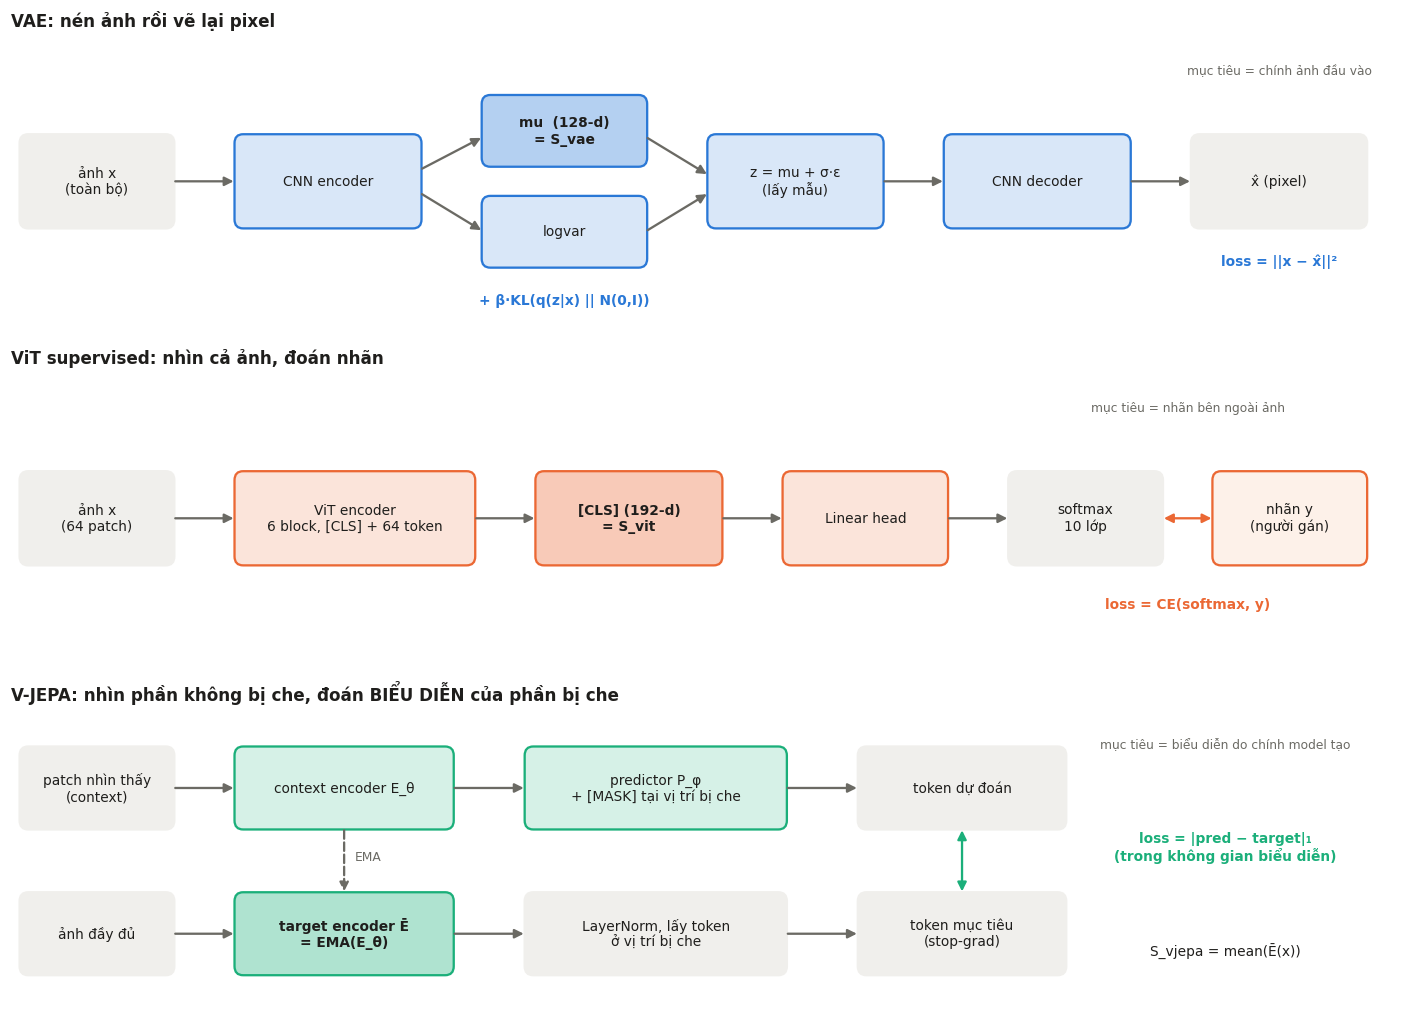

In [ ]:
def draw_box(ax, x, y, w, h, text, fc, ec=None, fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec or fc, lw=1.5))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", color=INK)


def arrow(ax, x0, y0, x1, y1, color=INK_MUTED, style="-|>", ls="-", text=None):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle=style, mutation_scale=12,
                                 color=color, lw=1.5, linestyle=ls))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, text, ha="center", fontsize=8, color=INK_MUTED)


def tint(hex_color, a=0.18):
    c = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return tuple(c * a + (1 - a))


fig, axes = plt.subplots(3, 1, figsize=(13, 9.3))
light = "#f0efec"
for ax in axes:
    ax.set_xlim(0, 13); ax.set_ylim(0, 2.6); noaxis(ax)

# VAE
ax, c = axes[0], MODEL_COLORS["VAE"]
ax.set_title("VAE: nén ảnh rồi vẽ lại pixel", loc="left", color=INK)
draw_box(ax, 0.1, 0.9, 1.4, 0.8, "ảnh x\n(toàn bộ)", light)
draw_box(ax, 2.1, 0.9, 1.7, 0.8, "CNN encoder", tint(c), c)
draw_box(ax, 4.4, 1.45, 1.5, 0.6, "mu  (128-d)\n= S_vae", tint(c, .35), c, bold=True)
draw_box(ax, 4.4, 0.55, 1.5, 0.6, "logvar", tint(c), c)
draw_box(ax, 6.5, 0.9, 1.6, 0.8, "z = mu + σ·ε\n(lấy mẫu)", tint(c), c)
draw_box(ax, 8.7, 0.9, 1.7, 0.8, "CNN decoder", tint(c), c)
draw_box(ax, 11.0, 0.9, 1.6, 0.8, "x̂ (pixel)", light)
arrow(ax, 1.5, 1.3, 2.1, 1.3); arrow(ax, 3.8, 1.4, 4.4, 1.7); arrow(ax, 3.8, 1.2, 4.4, 0.85)
arrow(ax, 5.9, 1.7, 6.5, 1.35); arrow(ax, 5.9, 0.85, 6.5, 1.2); arrow(ax, 8.1, 1.3, 8.7, 1.3); arrow(ax, 10.4, 1.3, 11.0, 1.3)
ax.text(11.8, 0.55, "loss = ||x − x̂||²", ha="center", fontsize=9, color=c, fontweight="bold")
ax.text(5.15, 0.2, "+ β·KL(q(z|x) || N(0,I))", ha="center", fontsize=9, color=c, fontweight="bold")
ax.text(11.8, 2.25, "mục tiêu = chính ảnh đầu vào", ha="center", fontsize=8, color=INK_MUTED)

# ViT
ax, c = axes[1], MODEL_COLORS["ViT"]
ax.set_title("ViT supervised: nhìn cả ảnh, đoán nhãn", loc="left", color=INK)
draw_box(ax, 0.1, 0.9, 1.4, 0.8, "ảnh x\n(64 patch)", light)
draw_box(ax, 2.1, 0.9, 2.2, 0.8, "ViT encoder\n6 block, [CLS] + 64 token", tint(c), c)
draw_box(ax, 4.9, 0.9, 1.7, 0.8, "[CLS] (192-d)\n= S_vit", tint(c, .35), c, bold=True)
draw_box(ax, 7.2, 0.9, 1.5, 0.8, "Linear head", tint(c), c)
draw_box(ax, 9.3, 0.9, 1.4, 0.8, "softmax\n10 lớp", light)
draw_box(ax, 11.2, 0.9, 1.4, 0.8, "nhãn y\n(người gán)", "#fdf1e9", c)
arrow(ax, 1.5, 1.3, 2.1, 1.3); arrow(ax, 4.3, 1.3, 4.9, 1.3); arrow(ax, 6.6, 1.3, 7.2, 1.3); arrow(ax, 8.7, 1.3, 9.3, 1.3)
arrow(ax, 11.2, 1.3, 10.7, 1.3, color=c, style="<|-|>")
ax.text(10.95, 0.5, "loss = CE(softmax, y)", ha="center", fontsize=9, color=c, fontweight="bold")
ax.text(10.95, 2.25, "mục tiêu = nhãn bên ngoài ảnh", ha="center", fontsize=8, color=INK_MUTED)

# V-JEPA
ax, c = axes[2], MODEL_COLORS["V-JEPA"]
ax.set_title("V-JEPA: nhìn phần không bị che, đoán BIỂU DIỄN của phần bị che", loc="left", color=INK)
draw_box(ax, 0.1, 1.55, 1.4, 0.7, "patch nhìn thấy\n(context)", light)
draw_box(ax, 0.1, 0.25, 1.4, 0.7, "ảnh đầy đủ", light)
draw_box(ax, 2.1, 1.55, 2.0, 0.7, "context encoder E_θ", tint(c), c)
draw_box(ax, 2.1, 0.25, 2.0, 0.7, "target encoder Ē\n= EMA(E_θ)", tint(c, .35), c, bold=True)
draw_box(ax, 4.8, 1.55, 2.4, 0.7, "predictor P_φ\n+ [MASK] tại vị trí bị che", tint(c), c)
draw_box(ax, 7.9, 1.55, 1.9, 0.7, "token dự đoán", light)
draw_box(ax, 4.8, 0.25, 2.4, 0.7, "LayerNorm, lấy token\nở vị trí bị che", light)
draw_box(ax, 7.9, 0.25, 1.9, 0.7, "token mục tiêu\n(stop-grad)", light)
arrow(ax, 1.5, 1.9, 2.1, 1.9); arrow(ax, 1.5, 0.6, 2.1, 0.6); arrow(ax, 4.1, 1.9, 4.8, 1.9); arrow(ax, 7.2, 1.9, 7.9, 1.9)
arrow(ax, 4.1, 0.6, 4.8, 0.6); arrow(ax, 7.2, 0.6, 7.9, 0.6)
arrow(ax, 8.85, 1.55, 8.85, 0.95, color=c, style="<|-|>")
arrow(ax, 3.1, 1.55, 3.1, 0.95, color=INK_MUTED, ls="--")
ax.text(3.2, 1.25, "EMA", fontsize=8, color=INK_MUTED)
ax.text(11.3, 1.25, "loss = |pred − target|₁\n(trong không gian biểu diễn)", ha="center", fontsize=9, color=c, fontweight="bold")
ax.text(11.3, 2.25, "mục tiêu = biểu diễn do chính model tạo", ha="center", fontsize=8, color=INK_MUTED)
ax.text(11.3, 0.4, "S_vjepa = mean(Ē(x))", ha="center", fontsize=9, color=INK)
fig.tight_layout()
show(fig, "01_pipelines.png")

**Nhận xét**

- Khác biệt cốt lõi nằm ở **mũi tên cuối cùng**: VAE so với **pixel**, ViT so với **nhãn**, V-JEPA so với **biểu diễn do chính nó tạo ra** (qua target encoder EMA).
- Hai mục tiêu đầu cố định suốt quá trình học. Mục tiêu của V-JEPA **thay đổi theo thời gian**, vì target encoder cũng học. Đây vừa là sức mạnh (tự sinh nhãn), vừa là nguồn rủi ro collapse (mục 5).
- ViT và V-JEPA dùng **cùng một kiến trúc encoder**, nên mọi khác biệt giữa hai không gian của chúng đến từ mục tiêu học, không phải từ kiến trúc.

## 1b. Nhìn trực tiếp ba không gian `S_vae`, `S_vit`, `S_vjepa`

Mỗi ảnh được biến thành **một vector**, và ba vector đó là ba "không gian" mà cả notebook so sánh:

| Không gian | Lấy từ đâu | Số chiều |
|---|---|---|
| `S_vae` | `mu(x)`: trung bình của posterior q(z\|x) trong encoder VAE | 128 |
| `S_vit` | token `[CLS]` ở output cuối của ViT (thứ đi vào lớp phân loại) | 192 |
| `S_vjepa` | trung bình 64 patch token của **target encoder** V-JEPA | 192 |

Mục này vẽ chính các vector đó trên cùng những ảnh test:
1. PCA 2D và t-SNE 2D, tô màu theo lớp (model không thấy màu này, trừ ViT).
2. "Dấu vân tay": giá trị từng chiều của vector cho 200 ảnh xếp theo lớp.
3. Ma trận cosine giữa các ảnh, và giữa tâm các lớp.
4. Láng giềng gần nhất: cùng một ảnh hỏi, mỗi không gian trả về ảnh nào.
5. Mỗi không gian "xếp hàng" ảnh theo hướng chính thứ nhất như thế nào.

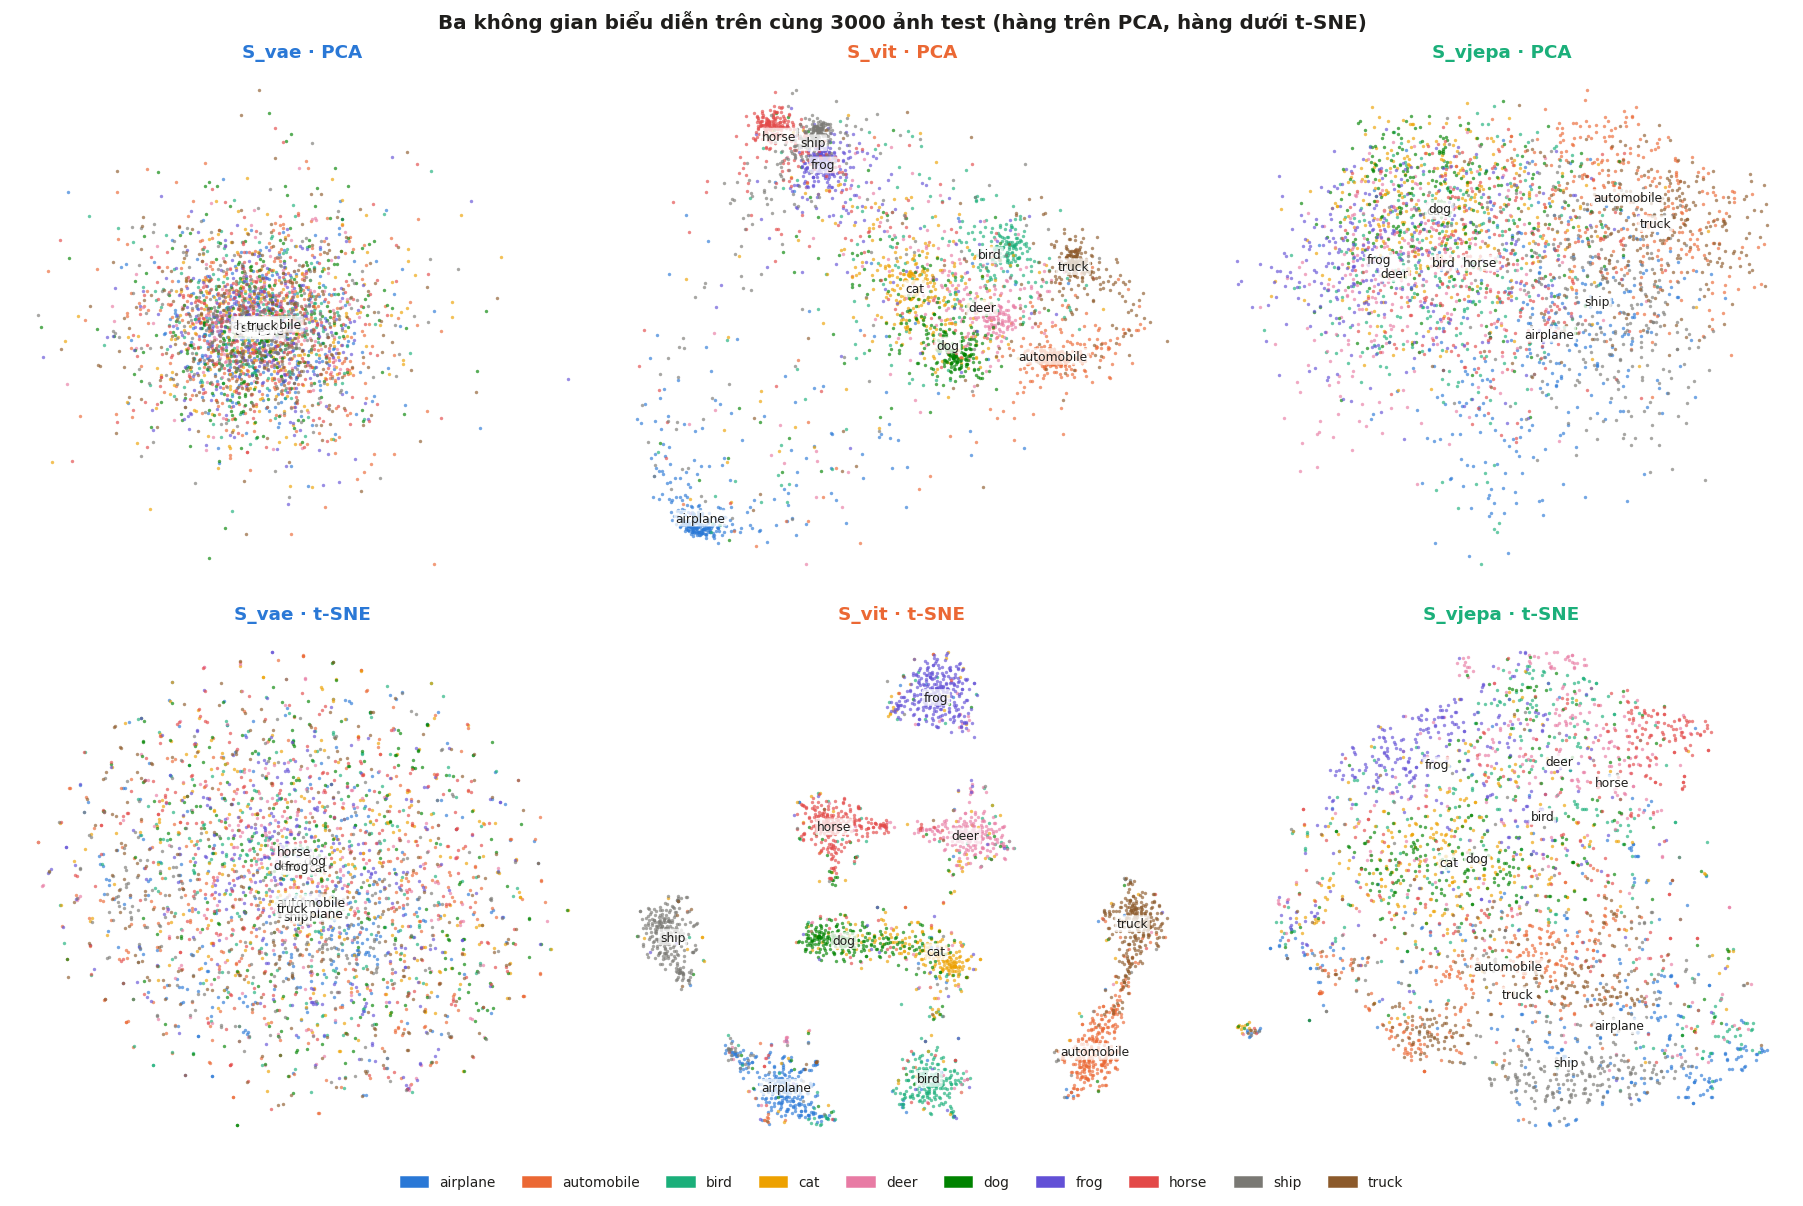

In [ ]:
from sklearn.manifold import TSNE

N_VIS = 1000 if QUICK_TEST else 3000
S = {n: F_te[n][:N_VIS] for n in NAMES}              # S_vae, S_vit, S_vjepa của cùng N_VIS ảnh test
y_vis = Yp_te[:N_VIS].numpy()
X_vis = Xp_te[:N_VIS]
SPACE = {"VAE": "S_vae", "ViT": "S_vit", "V-JEPA": "S_vjepa"}
for n in NAMES:
    print(f"{SPACE[n]:8s} shape {tuple(S[n].shape)}   ||f|| TB {S[n].norm(dim=1).mean():.2f}")

emb = {}
for n in NAMES:
    z = StandardScaler().fit_transform(S[n].numpy())
    emb[n, "PCA"] = PCA(2).fit_transform(z)
    z50 = PCA(min(50, z.shape[1])).fit_transform(z)
    emb[n, "t-SNE"] = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(z50)

fig, axes = plt.subplots(2, 3, figsize=(16.5, 11))
for j, n in enumerate(NAMES):
    for i, m in enumerate(["PCA", "t-SNE"]):
        ax, z = axes[i, j], emb[n, m]
        for c in range(10):
            sel = y_vis == c
            ax.scatter(z[sel, 0], z[sel, 1], s=5, color=CLASS_COLORS[c], alpha=0.65, linewidths=0)
        if True:                                      # tên lớp đặt tại trung vị cụm
            for c in range(10):
                cx, cy = np.median(z[y_vis == c], 0)
                ax.text(cx, cy, CLASSES[c], fontsize=8, ha="center", va="center", color=INK,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
        noaxis(ax)
        ax.set_title(f"{SPACE[n]} · {m}", color=MODEL_COLORS[n], fontsize=12)
fig.legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASSES[c]) for c in range(10)],
           loc="lower center", ncol=10, fontsize=9, bbox_to_anchor=(0.5, -0.005))
fig.suptitle(f"Ba không gian biểu diễn trên cùng {N_VIS} ảnh test (hàng trên PCA, hàng dưới t-SNE)",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.025, 1, 1))
show(fig, "01b_spaces_pca_tsne.png")

**Nhận xét**

- **`S_vae`**: cả PCA lẫn t-SNE đều là một đám mây tròn, các lớp trộn đều. Tên các lớp chồng lên nhau ở giữa hình: tâm của 10 lớp gần như trùng nhau.
- **`S_vit`**: ngay trong PCA (phép chiếu **tuyến tính**) đã thấy cụm: airplane tách hẳn ở một góc, horse / ship / frog ở góc khác. Trong t-SNE là 10 đảo rời; chỉ **cat–dog** dính nhau thành một dải.
- **`S_vjepa`**: PCA cho thấy một **trục động vật ↔ xe cộ** (trái sang phải). t-SNE chia hai vùng lớn (frog/deer/horse/bird phía trên, automobile/truck/airplane/ship phía dưới), nhưng trong mỗi vùng các lớp còn đan xen.
- Cặp **cat–dog** khó nhất trong cả ba không gian.

### "Dấu vân tay" của từng không gian

Mỗi hàng là một ảnh (20 ảnh mỗi lớp, xếp theo lớp), mỗi cột là một chiều của vector (đã chuẩn hoá z-score; cột xếp theo mức chênh giữa các lớp).
Nếu không gian mang thông tin lớp, ta sẽ thấy các **dải ngang theo khối lớp**. Nếu không, hình trông như nhiễu.

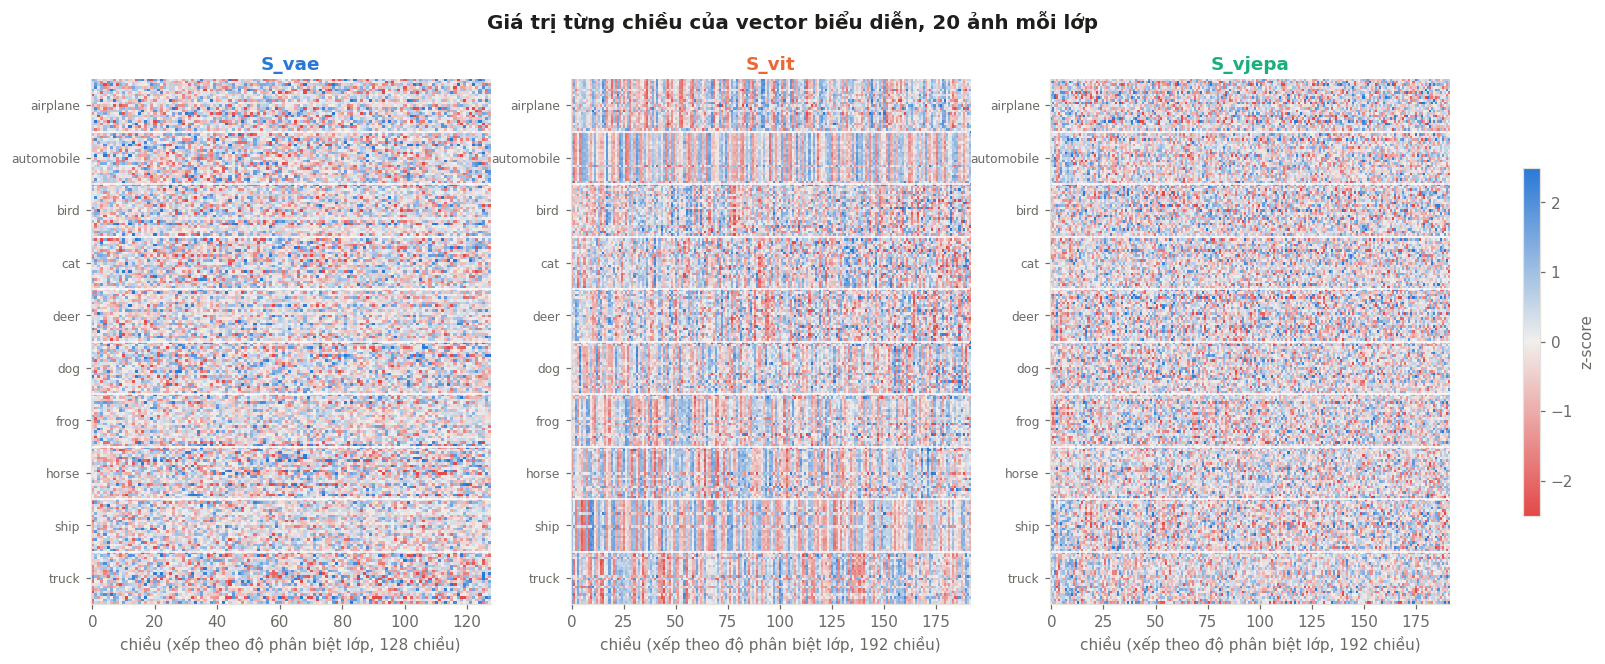

In [ ]:
per = 20
idx_fp = np.concatenate([np.nonzero(y_vis == c)[0][:per] for c in range(10)])
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2))
for ax, n in zip(axes, NAMES):
    z = StandardScaler().fit_transform(S[n].numpy())
    cls_means = np.stack([z[y_vis == c].mean(0) for c in range(10)])
    order_d = np.argsort(-cls_means.std(0))                   # chiều phân biệt lớp mạnh nhất ở bên trái
    im = ax.imshow(np.clip(z[idx_fp][:, order_d], -2.5, 2.5), aspect="auto", cmap=DIVERGING, vmin=-2.5, vmax=2.5,
                   interpolation="nearest")
    for c in range(1, 10):
        ax.axhline(c * per - 0.5, color="white", lw=1)
    ax.set_yticks(np.arange(10) * per + per / 2 - 0.5); ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_xlabel(f"chiều (xếp theo độ phân biệt lớp, {z.shape[1]} chiều)")
    ax.set_title(SPACE[n], color=MODEL_COLORS[n], fontsize=12)
fig.colorbar(im, ax=axes, fraction=0.012, label="z-score")
fig.suptitle("Giá trị từng chiều của vector biểu diễn, 20 ảnh mỗi lớp", fontsize=13, fontweight="bold")
show(fig, "01c_spaces_fingerprint.png")

**Nhận xét**

- **`S_vit`** có **dải ngang rõ** theo khối lớp: nhiều chiều cùng đổi màu cho cả một lớp (dễ thấy nhất ở automobile, ship, frog, horse). Mỗi lớp có một "chữ ký" riêng trên hàng chục chiều.
- **`S_vjepa`** chỉ có dải mờ: thông tin lớp có, nhưng trải trên nhiều chiều và yếu hơn.
- **`S_vae`** gần như nhiễu: các chiều của `mu` mã hoá những thứ không liên quan tới lớp (màu, độ sáng, bố cục), nên xếp ảnh theo lớp không tạo ra khối nào.

### Ma trận cosine: ảnh với ảnh, lớp với lớp

Trái (mỗi không gian): cosine (sau khi trừ trung bình) giữa 300 ảnh xếp theo lớp. **Khối vuông sáng trên đường chéo** = ảnh cùng lớp nằm gần nhau.
Phải: cosine giữa **tâm** 10 lớp, cho thấy không gian coi lớp nào gần lớp nào (ví dụ cat–dog, automobile–truck).

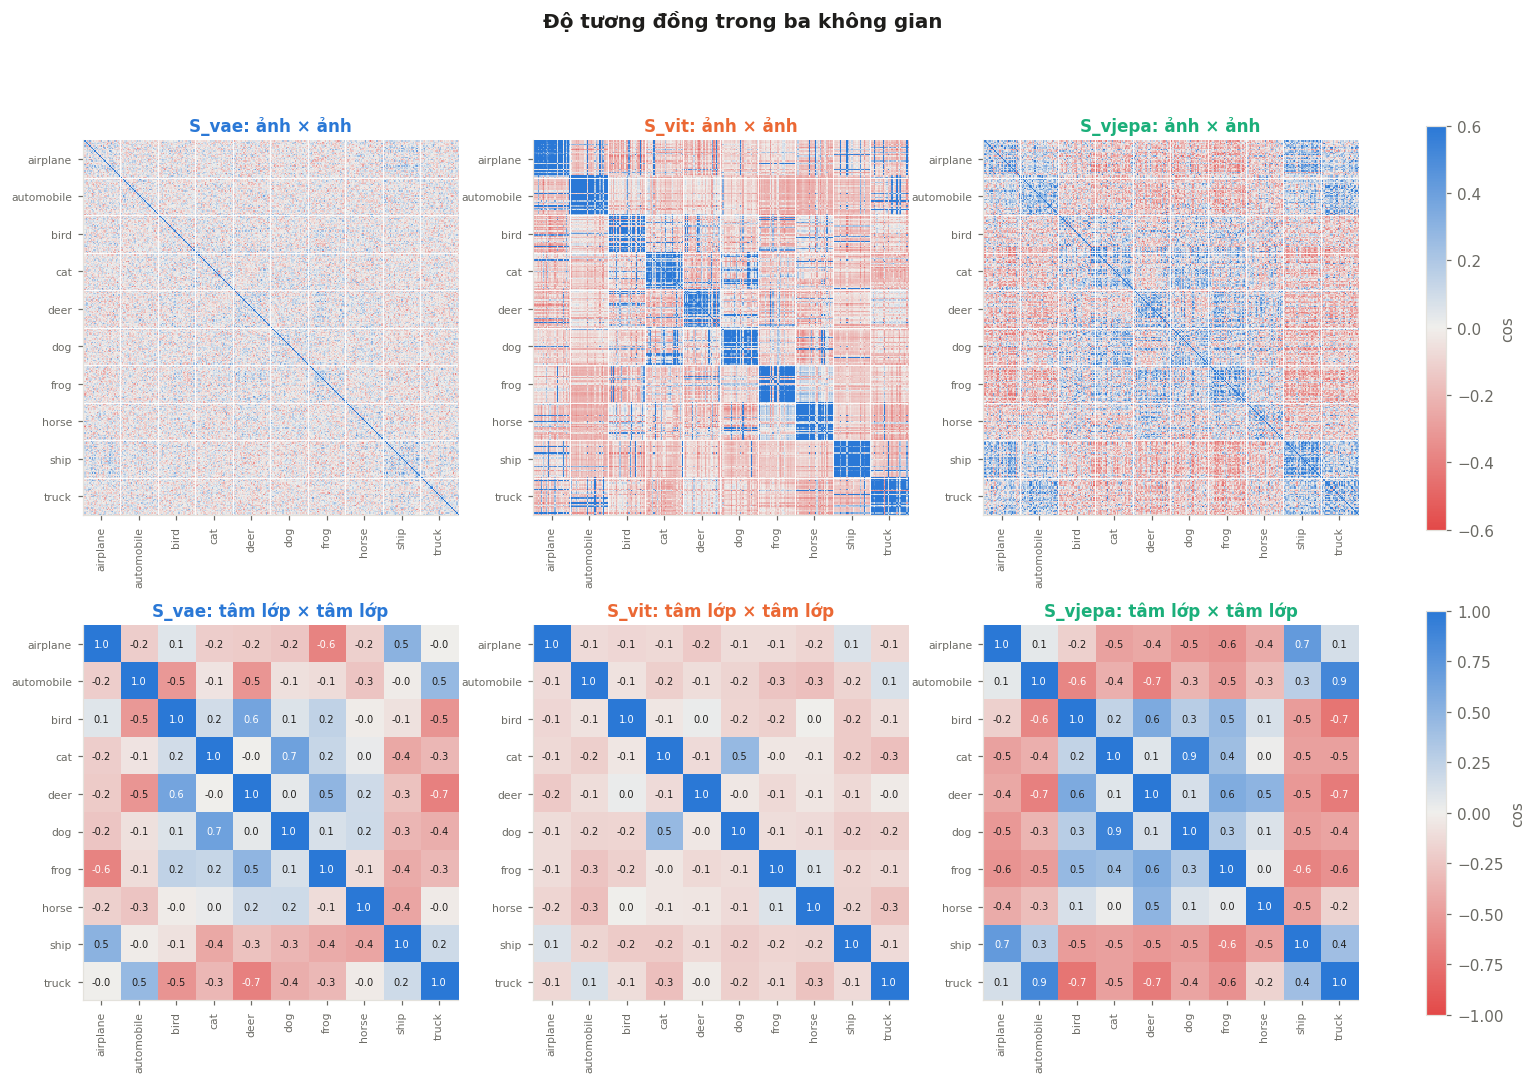

In [ ]:
per = 30
idx_sm = np.concatenate([np.nonzero(y_vis == c)[0][:per] for c in range(10)])
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for j, n in enumerate(NAMES):
    f = S[n] - mean_tr[n]
    fn = F.normalize(f, dim=1)
    sim = (fn[idx_sm] @ fn[idx_sm].T).numpy()
    ax = axes[0, j]
    im = ax.imshow(sim, cmap=DIVERGING, vmin=-0.6, vmax=0.6, interpolation="nearest")
    for c in range(1, 10):
        ax.axhline(c * per - 0.5, color="white", lw=0.6); ax.axvline(c * per - 0.5, color="white", lw=0.6)
    ticks = np.arange(10) * per + per / 2 - 0.5
    ax.set_xticks(ticks); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_yticks(ticks); ax.set_yticklabels(CLASSES, fontsize=7)
    ax.set_title(f"{SPACE[n]}: ảnh × ảnh", color=MODEL_COLORS[n])

    cent = F.normalize(torch.stack([f[torch.from_numpy(y_vis == c)].mean(0) for c in range(10)]), dim=1)
    cs = (cent @ cent.T).numpy()
    ax = axes[1, j]
    im2 = ax.imshow(cs, cmap=DIVERGING, vmin=-1, vmax=1)
    for a_ in range(10):
        for b_ in range(10):
            ax.text(b_, a_, f"{cs[a_, b_]:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(cs[a_, b_]) > 0.6 else INK)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=7)
    ax.set_title(f"{SPACE[n]}: tâm lớp × tâm lớp", color=MODEL_COLORS[n])
fig.colorbar(im, ax=axes[0], fraction=0.015, label="cos")
fig.colorbar(im2, ax=axes[1], fraction=0.015, label="cos")
fig.suptitle("Độ tương đồng trong ba không gian", fontsize=13, fontweight="bold")
show(fig, "01d_spaces_similarity.png")

**Nhận xét**

- **`S_vit`**: khối vuông đậm trên đường chéo cho mọi lớp, cộng thêm các khối ngoài đường chéo giữa **xe cộ với nhau** (airplane–ship, automobile–truck). Tâm lớp gần như vuông góc nhau (cos ≈ −0,1), riêng cat–dog 0,5.
- **`S_vjepa`**: khối đường chéo mờ hơn, nhưng thấy rõ **siêu lớp**: automobile–truck 0,9, cat–dog 0,9, airplane–ship 0,7, và động vật nói chung đối nghịch với xe cộ (cos âm).
- **`S_vae`**: gần như chỉ có đường chéo mảnh, tức mỗi ảnh chỉ giống chính nó. Tâm lớp lại cho thấy "ngữ nghĩa theo màu": airplane–ship 0,5 (cùng nền trời / biển xanh), deer–bird 0,6, cat–dog 0,7 (nền nâu), frog–airplane −0,6 (xanh lá vs xanh trời).

### Láng giềng gần nhất: cùng một ảnh hỏi, mỗi không gian trả về gì?

Với mỗi ảnh hỏi (cột trái), 6 ảnh test gần nhất theo cosine trong từng không gian. Viền xanh = cùng lớp, viền đỏ = khác lớp.
Không gian học pixel (VAE) hay trả về ảnh **giống màu / bố cục**; không gian học nhãn (ViT) trả về ảnh **cùng lớp** dù màu khác.

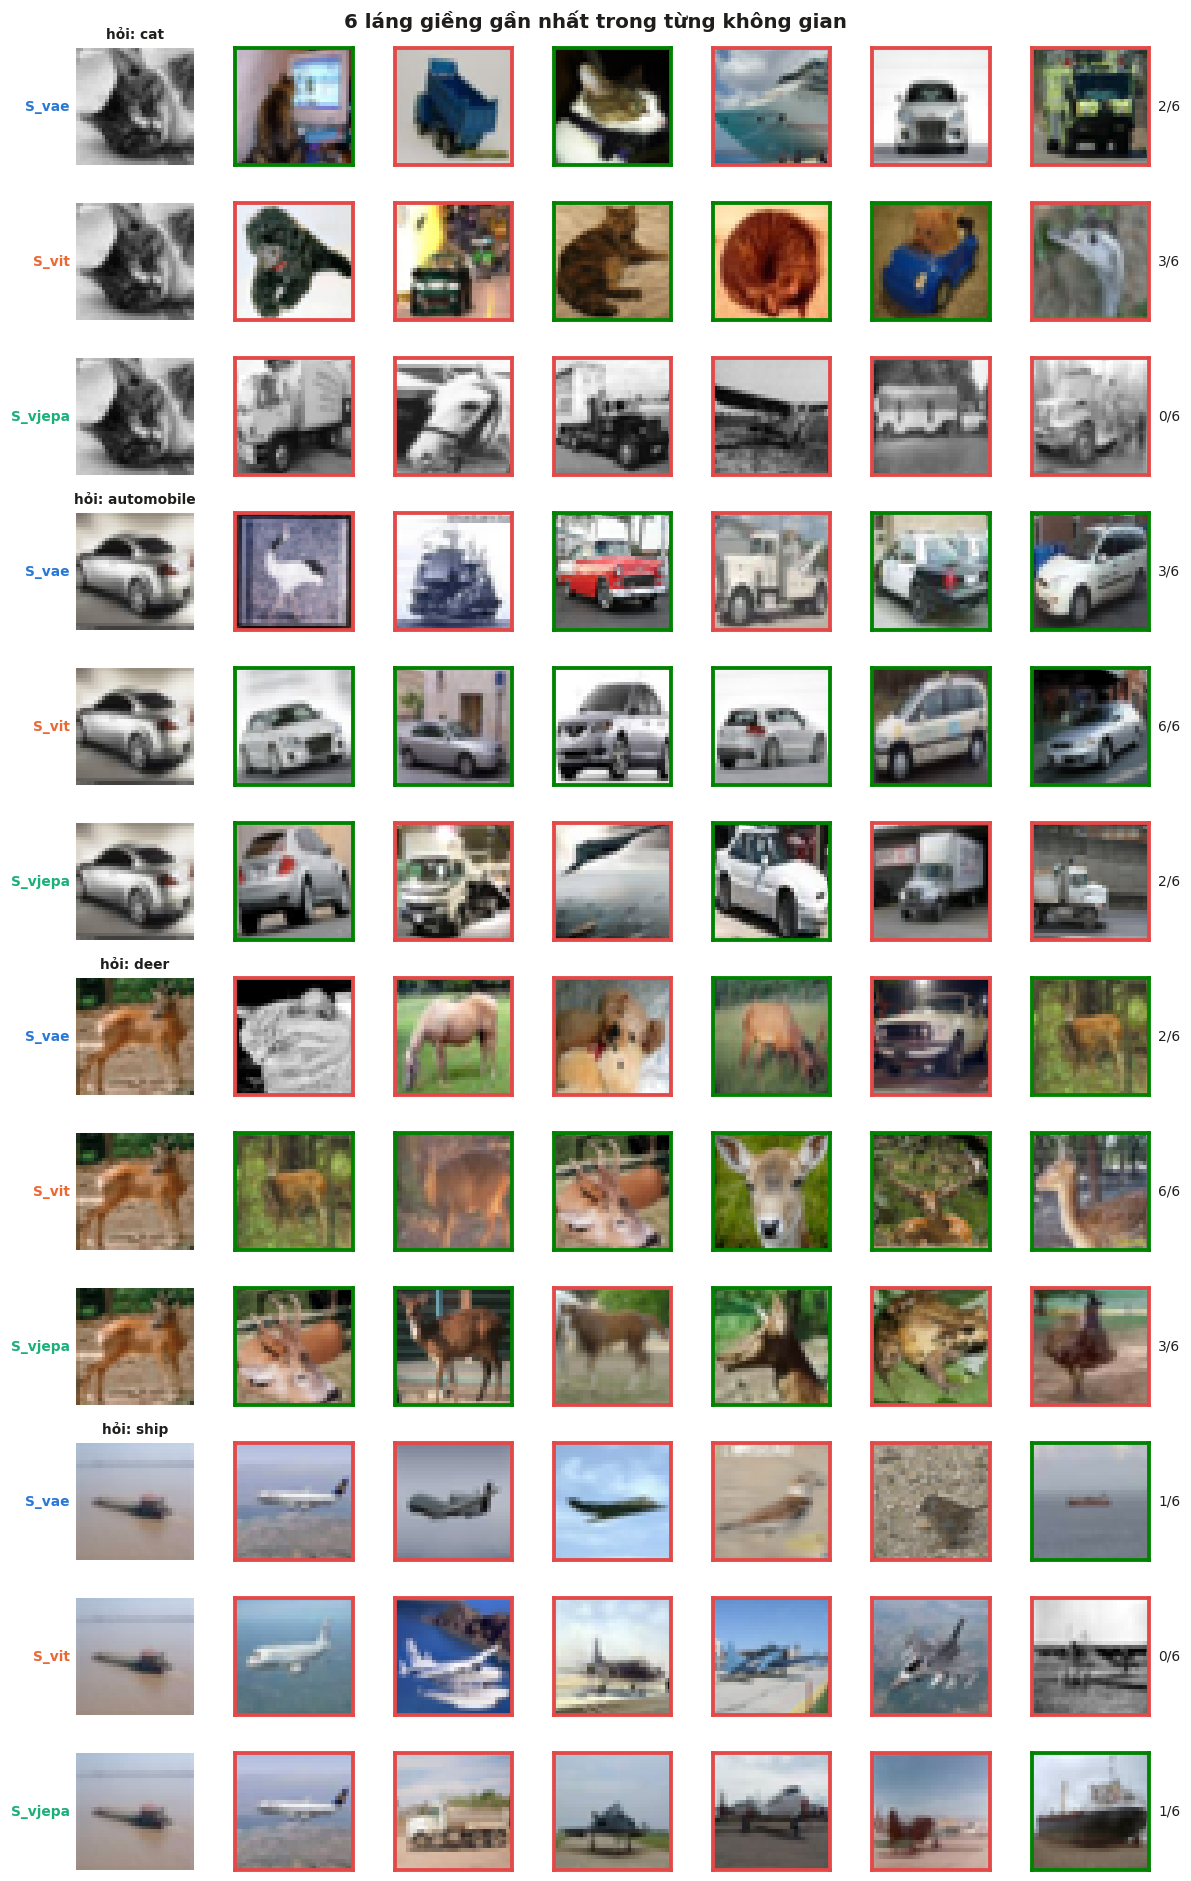

In [ ]:
K_NN = 6
queries = [int(np.nonzero(y_vis == c)[0][5]) for c in [3, 1, 4, 8]]      # mèo, ô tô, hươu, tàu
fn_all = {n: F.normalize(S[n] - mean_tr[n], dim=1) for n in NAMES}
rows = len(queries) * len(NAMES)
fig, axes = plt.subplots(rows, K_NN + 1, figsize=(1.45 * (K_NN + 1) + 1, 1.45 * rows))
for qi, q in enumerate(queries):
    for j, n in enumerate(NAMES):
        r_ = qi * len(NAMES) + j
        sims = fn_all[n] @ fn_all[n][q]
        sims[q] = -2
        nn_ = sims.topk(K_NN).indices.tolist()
        axes[r_, 0].imshow(img_np(X_vis[q]))
        axes[r_, 0].set_ylabel(SPACE[n], color=MODEL_COLORS[n], fontsize=9, fontweight="bold", rotation=0,
                               ha="right", va="center")
        hits = 0
        for k, t in enumerate(nn_):
            a = axes[r_, k + 1]
            a.imshow(img_np(X_vis[t]))
            ok = y_vis[t] == y_vis[q]; hits += ok
            for sp in a.spines.values():
                sp.set_visible(True); sp.set_color(GOOD if ok else BAD); sp.set_linewidth(2.5)
        axes[r_, K_NN].text(1.08, 0.5, f"{hits}/{K_NN}", transform=axes[r_, K_NN].transAxes, va="center", fontsize=9)
    axes[qi * len(NAMES), 0].set_title(f"hỏi: {CLASSES[y_vis[q]]}", fontsize=9)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
for a in axes[:, 0]:
    for sp in a.spines.values():
        sp.set_visible(False)
fig.suptitle("6 láng giềng gần nhất trong từng không gian", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "01e_spaces_neighbors.png")

**Nhận xét**

- **automobile, deer**: `S_vit` đúng 6/6, `S_vjepa` 2–3/6, `S_vae` 2–3/6. Láng giềng của VAE giống ảnh hỏi về **màu và bố cục** (xe trắng → chim trắng, tàu xám).
- **cat (ảnh xám)**: `S_vjepa` trả về **toàn ảnh xám** khác lớp (0/6). V-JEPA coi "ảnh xám" là một đặc điểm rất mạnh, khớp với độ nhạy cao với ảnh xám ở mục 9.
- **ship**: cả ba đều thất bại, trả về máy bay. Ảnh này (vật dẹt, tối, trên mặt nước sáng) trông giống máy bay trên trời, nên đây là ví dụ khó thật chứ không phải lỗi của riêng model nào.

### Hướng chính thứ nhất của mỗi không gian "đo" cái gì?

Chiếu mọi ảnh lên PC1 của từng không gian, rồi xếp ảnh từ giá trị thấp nhất đến cao nhất (hiển thị 12 ảnh cách đều).
Hướng biến thiên mạnh nhất là thứ không gian đó "quan tâm nhất": với `S_vae` thường là **màu / độ sáng tổng thể** (lớp lẫn lộn dọc trục),
với `S_vit` và `S_vjepa` là một trục **ngữ nghĩa** (động vật / thiên nhiên ↔ xe cộ / nhân tạo).

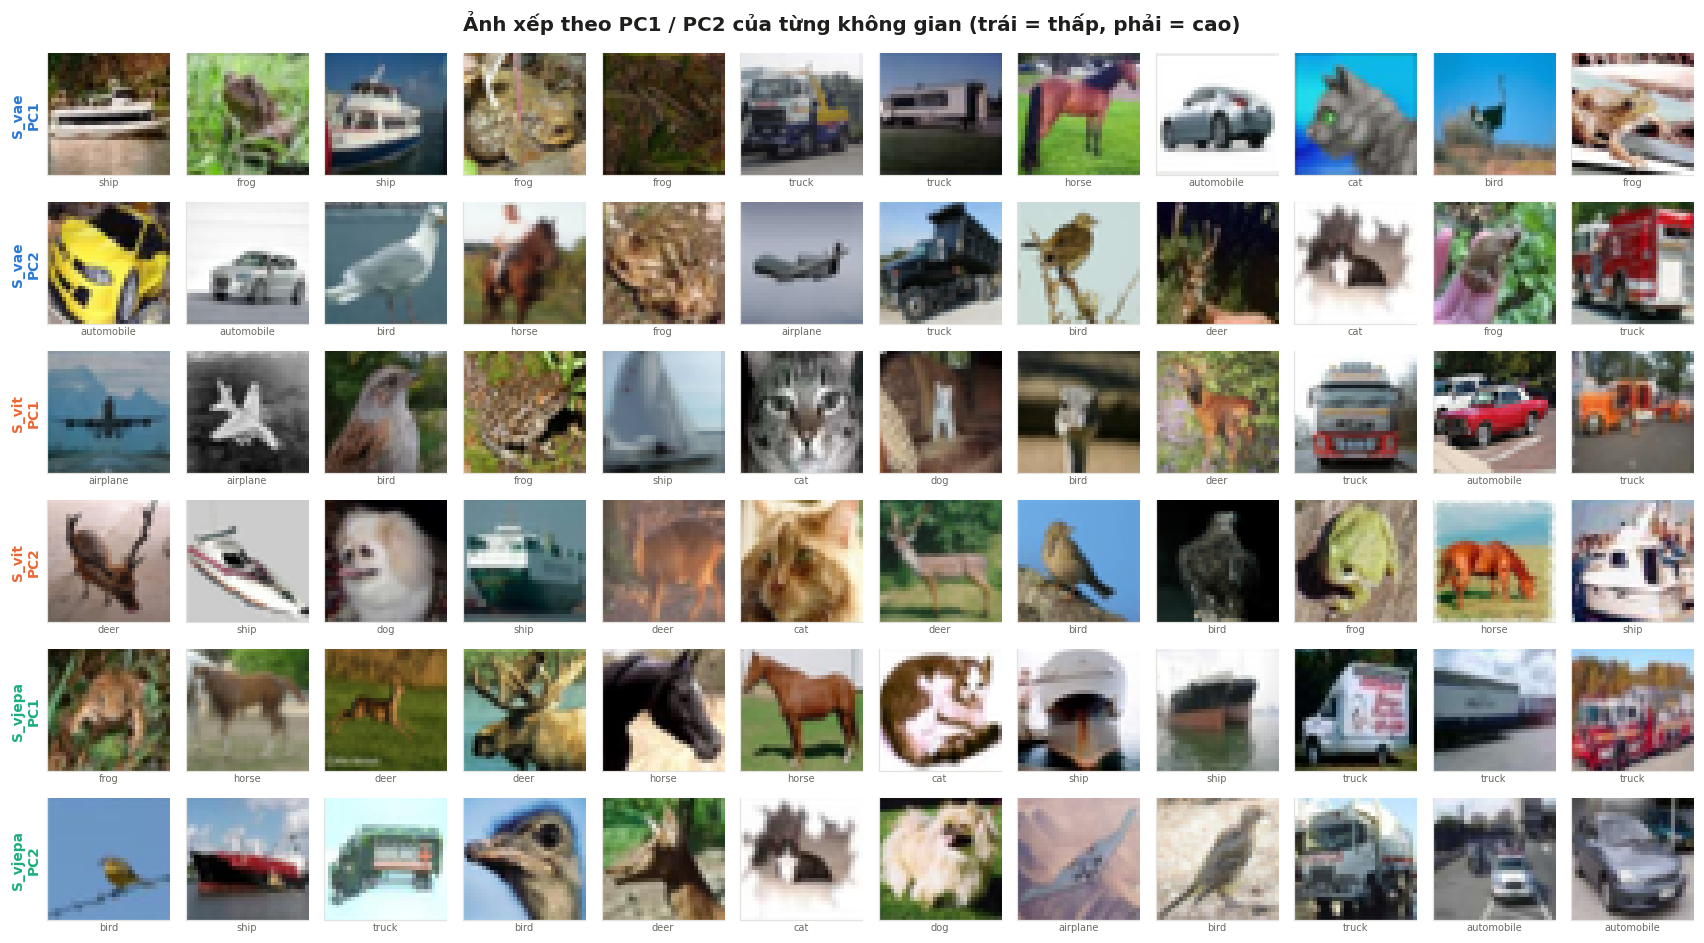

In [ ]:
n_show_pc = 12
fig, axes = plt.subplots(len(NAMES) * 2, n_show_pc, figsize=(1.3 * n_show_pc, 1.45 * 2 * len(NAMES)))
for i, n in enumerate(NAMES):
    z = StandardScaler().fit_transform(S[n].numpy())
    pcs = PCA(2).fit(z).transform(z)
    for k in range(2):
        order_ = np.argsort(pcs[:, k])
        pick_ = order_[np.linspace(0, len(order_) - 1, n_show_pc).astype(int)]
        for c, t in enumerate(pick_):
            a = axes[2 * i + k, c]
            a.imshow(img_np(X_vis[t])); a.set_xticks([]); a.set_yticks([])
            a.set_xlabel(CLASSES[y_vis[t]], fontsize=6.5, labelpad=1)
        axes[2 * i + k, 0].set_ylabel(f"{SPACE[n]}\nPC{k + 1}", color=MODEL_COLORS[n], fontsize=9, fontweight="bold")
fig.suptitle("Ảnh xếp theo PC1 / PC2 của từng không gian (trái = thấp, phải = cao)", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "01f_spaces_pc_axes.png")

**Nhận xét**

- **`S_vae` PC1**: lớp xen kẽ lung tung (ship, frog, truck, horse, cat…); ảnh chủ yếu đổi theo **tông màu / độ sáng** của toàn ảnh (tối, xanh lá → sáng, xanh dương).
- **`S_vit` PC1**: airplane / bird (nền trời) → động vật → truck / automobile. Hướng mạnh nhất đã là một trục ngữ nghĩa.
- **`S_vjepa` PC1**: frog / horse / deer (nền thiên nhiên) → ship / truck (đồ nhân tạo). Đây là trục **động vật ↔ xe cộ** thấy trên PCA ở trên. PC2 của nó đi từ vật trên nền trời sang xe trên đường.

### Các lớp tách nhau tới đâu trong mỗi không gian?

Với mỗi lớp: **độ chặt** (cos TB tới tâm lớp của chính nó) và **khoảng cách tới lớp gần nhất** (1 − cos giữa tâm lớp đó và tâm lớp gần nhất).
Lớp nằm ở góc trên phải = vừa chặt vừa xa các lớp khác.

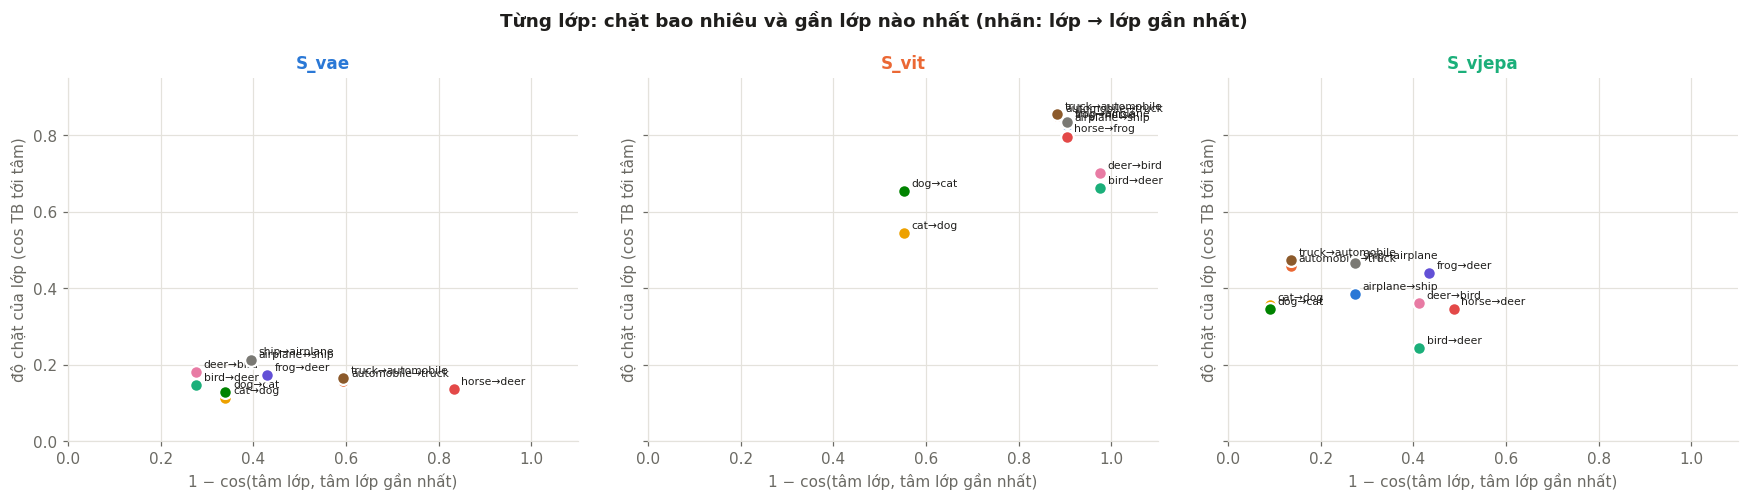

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)      # chung trục để so sánh
for ax, n in zip(axes, NAMES):
    f = F.normalize(S[n] - mean_tr[n], dim=1)
    cent = torch.stack([f[torch.from_numpy(y_vis == c)].mean(0) for c in range(10)])
    centn = F.normalize(cent, dim=1)
    tight = [float((f[torch.from_numpy(y_vis == c)] @ centn[c]).mean()) for c in range(10)]
    cc = centn @ centn.T
    cc.fill_diagonal_(-2)
    near = cc.max(1)
    sep = (1 - near.values).numpy()
    for c in range(10):
        ax.scatter(sep[c], tight[c], s=70, color=CLASS_COLORS[c], edgecolors="white", linewidths=1.5, zorder=3)
        ax.annotate(f"{CLASSES[c]}→{CLASSES[int(near.indices[c])]}", (sep[c], tight[c]), xytext=(5, 3),
                    textcoords="offset points", fontsize=7)
    ax.set_xlabel("1 − cos(tâm lớp, tâm lớp gần nhất)"); ax.set_ylabel("độ chặt của lớp (cos TB tới tâm)")
    ax.set_title(SPACE[n], color=MODEL_COLORS[n]); grid_style(ax)
axes[0].set_xlim(0, 1.1); axes[0].set_ylim(0, 0.95)
fig.suptitle("Từng lớp: chặt bao nhiêu và gần lớp nào nhất (nhãn: lớp → lớp gần nhất)", fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "01g_spaces_class_geometry.png")

**Nhận xét**

- Ba biểu đồ dùng **chung trục**, nên vị trí so được trực tiếp.
- **`S_vit`** nằm cao và xa: hầu hết lớp có độ chặt ~0,8 và cách lớp gần nhất ~0,9. Chỉ cat / dog thấp hơn.
- **`S_vae`** nằm sát đáy (độ chặt ~0,15 cho mọi lớp): ảnh cùng lớp không gần tâm lớp hơn bao nhiêu.
- **`S_vjepa`** ở giữa (độ chặt 0,25–0,47). Các cặp cat↔dog và automobile↔truck gần như **trùng hướng** (1 − cos ≈ 0,1), tức V-JEPA chưa tách được các lớp trong cùng siêu lớp.

### Đọc các hình của mục 1b

- **`S_vae`**: PCA và t-SNE là một đám mây trộn lẫn mọi lớp; ma trận cosine gần như không có khối; độ chặt mỗi lớp chỉ ~0,1–0,2.
  Láng giềng gần nhất giống **màu và bố cục** (tàu trên nền xám trả về máy bay trên trời xám). Đó là hệ quả trực tiếp của mục tiêu tái tạo pixel.
- **`S_vit`**: 10 cụm tách rời, khối vuông đậm trên đường chéo, các tâm lớp gần như **trực giao** (cos ≈ −0,1 giữa hầu hết các cặp).
  Nhãn ép mỗi lớp thành một cụm riêng; chỉ cat–dog còn dính nhau (cos 0,5).
- **`S_vjepa`**: không có nhãn nhưng vẫn có **cấu trúc ngữ nghĩa thô**: t-SNE chia rõ hai vùng động vật và xe cộ / máy bay / tàu,
  và tâm lớp xếp theo **siêu lớp** (automobile–truck 0,9, cat–dog 0,9, airplane–ship 0,7). Các lớp chưa tách hẳn như ViT.
  Láng giềng của nó cũng cho thấy điểm yếu ở mục 9: ảnh xám hỏi thì trả về toàn ảnh xám khác lớp.

## 1c. Ba không gian trên mặt cầu

kNN, cosine và V-JEPA đều chỉ quan tâm **hướng** của vector, không quan tâm độ dài. Vì vậy "hình dạng thật" của mỗi không gian là
tập các điểm trên **mặt cầu đơn vị** sau khi chuẩn hoá L2. Ta làm như sau:

1. trừ trung bình rồi chuẩn hoá L2 (đưa về mặt cầu trong 128 / 192 chiều),
2. chiếu xuống 3 chiều bằng PCA rồi chuẩn hoá lại, để mỗi ảnh là một điểm trên mặt cầu S² thông thường.

Hình dưới gồm hai góc nhìn 3D (mặt trước, mặt sau) và **bản đồ Mollweide** (trải cả mặt cầu ra phẳng như bản đồ thế giới, kinh độ × vĩ độ).
Chấm to có viền = tâm lớp. Không gian "tốt" cho phân loại sẽ có mỗi lớp chiếm một "lục địa" riêng trên quả cầu.

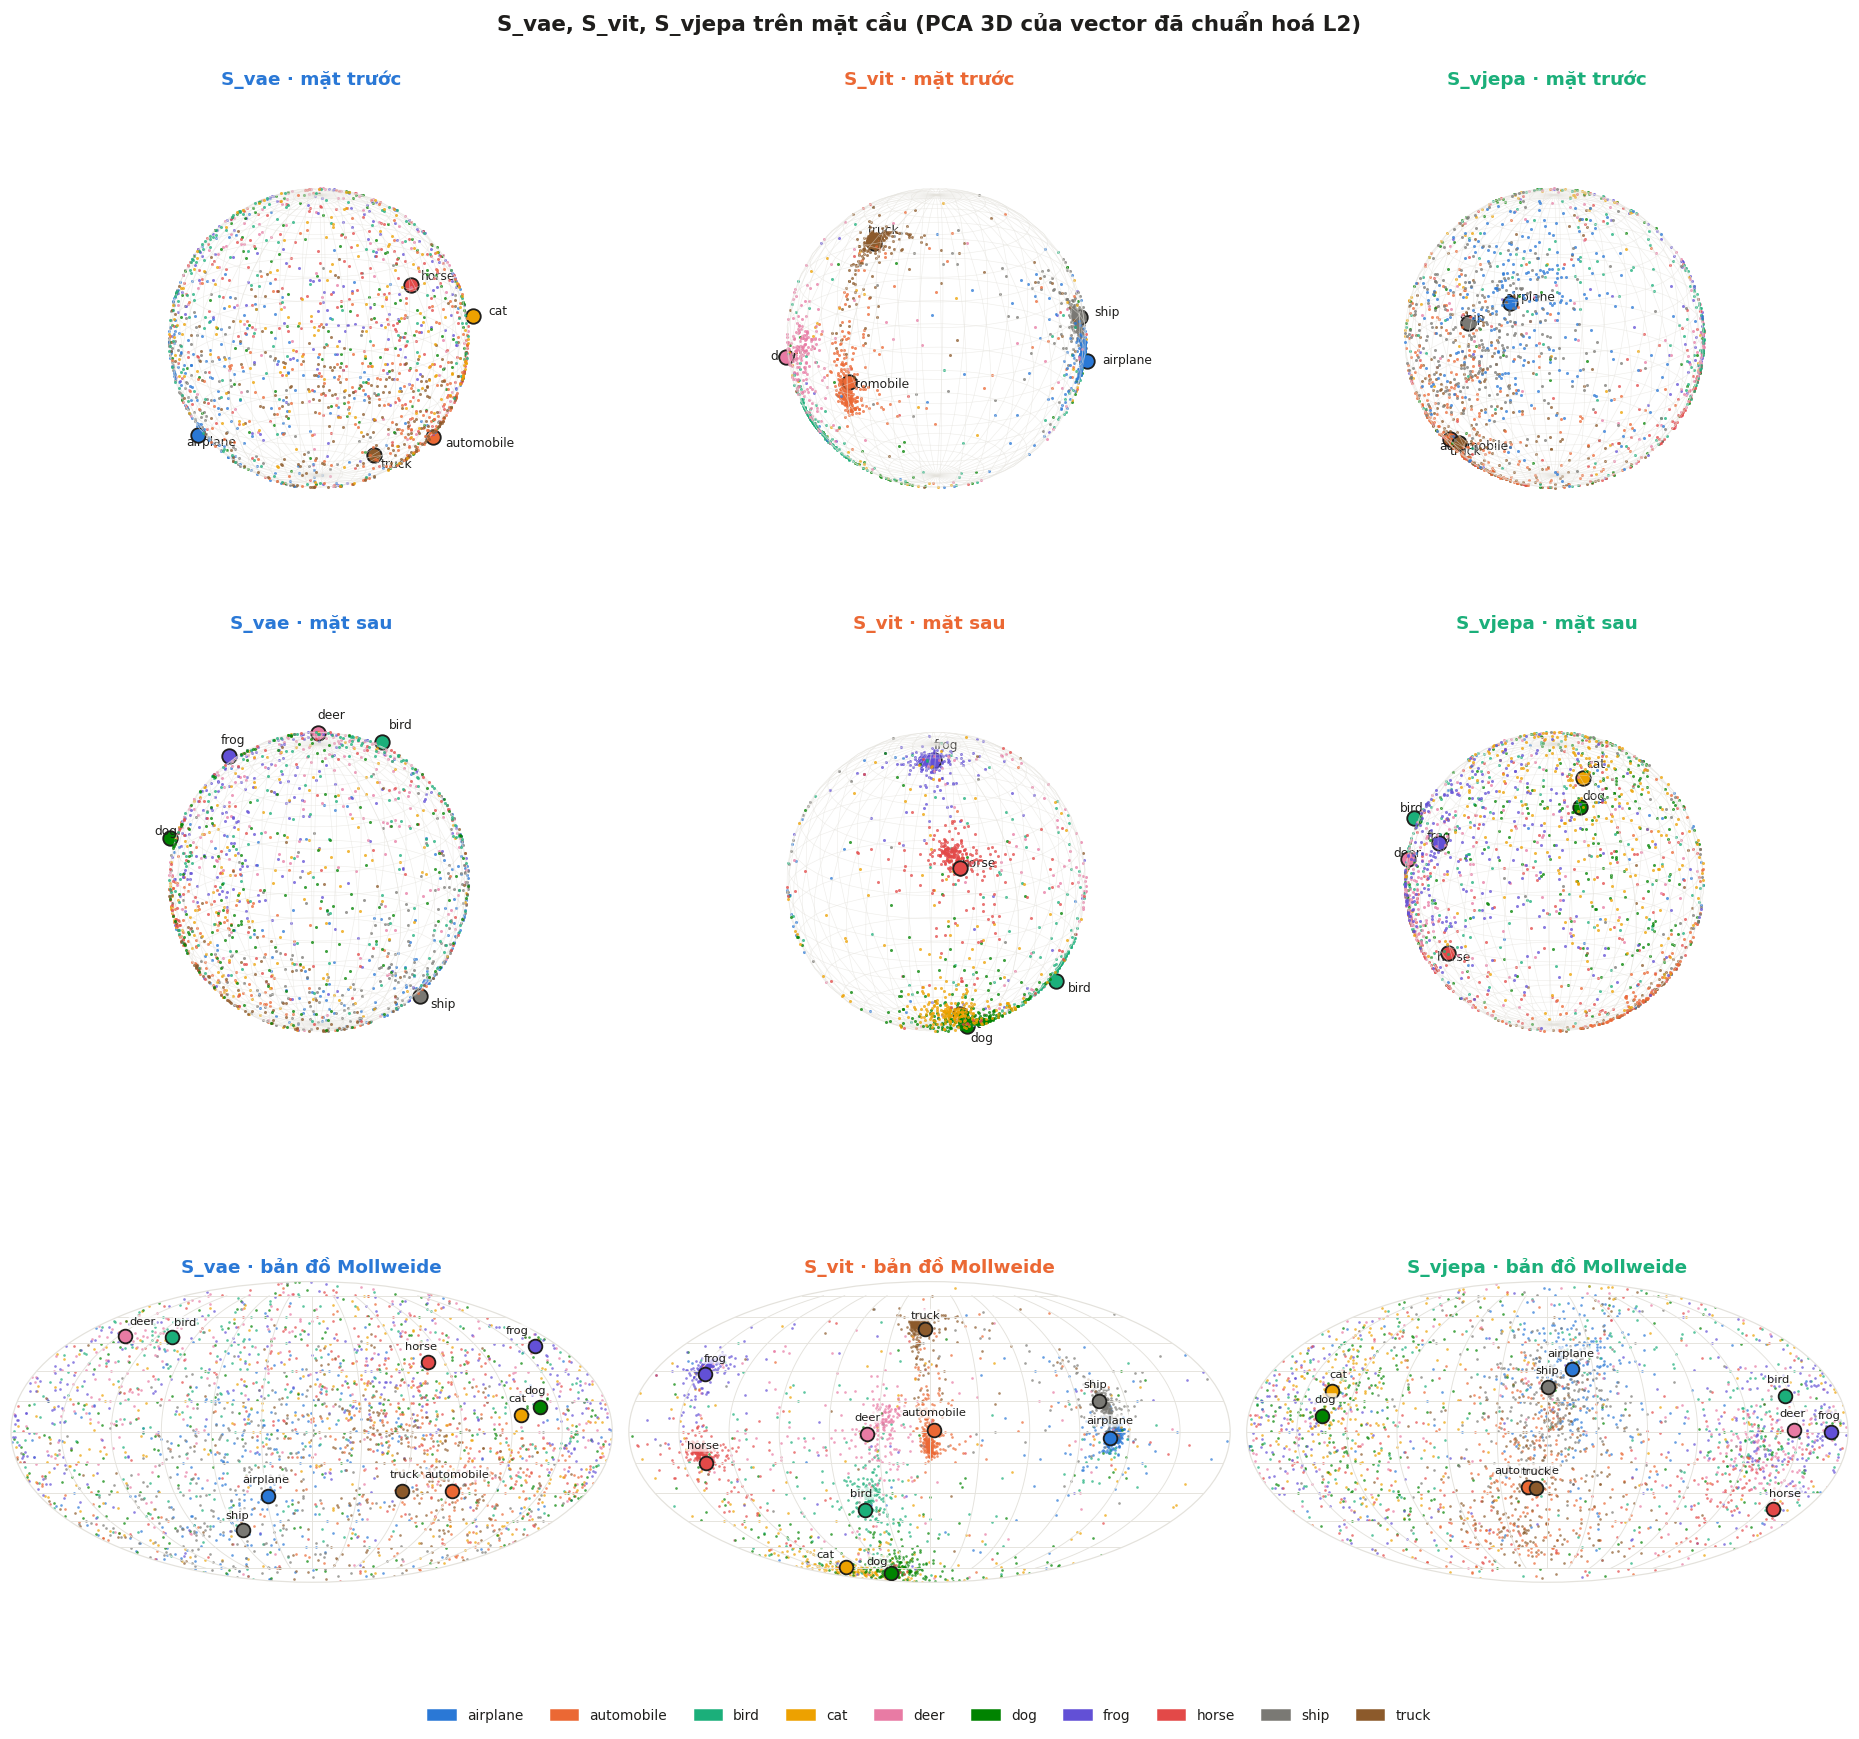

In [ ]:
def to_sphere(f):
    """vector -> mặt cầu cao chiều -> PCA 3D -> mặt cầu S²"""
    f = F.normalize(f - f.mean(0), dim=1).numpy()
    z = PCA(3, random_state=SEED).fit_transform(f)
    return z / np.linalg.norm(z, axis=1, keepdims=True)


SPH = {n: to_sphere(S[n]) for n in NAMES}
SPH_CENT = {n: np.stack([SPH[n][y_vis == c].mean(0) for c in range(10)]) for n in NAMES}
SPH_CENT = {n: c / np.linalg.norm(c, axis=1, keepdims=True) for n, c in SPH_CENT.items()}

u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
wire = (np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v))

fig = plt.figure(figsize=(17, 16))
for j, n in enumerate(NAMES):
    for i, (elev, azim, label) in enumerate([(20, 35, "mặt trước"), (-20, 215, "mặt sau")]):
        ax = fig.add_subplot(3, 3, 1 + i * 3 + j, projection="3d")
        ax.plot_wireframe(*wire, color=GRID, lw=0.4, alpha=0.6)
        z = SPH[n]
        # chỉ vẽ nửa cầu hướng về người xem cho rõ (nửa sau bị che)
        view = np.array([np.cos(np.radians(elev)) * np.cos(np.radians(azim)),
                         np.cos(np.radians(elev)) * np.sin(np.radians(azim)), np.sin(np.radians(elev))])
        front = z @ view > -0.1
        for c in range(10):
            sel = (y_vis == c) & front
            ax.scatter(*z[sel].T, s=4, color=CLASS_COLORS[c], alpha=0.75, depthshade=False, linewidths=0)
        for c in range(10):
            p = SPH_CENT[n][c] * 1.04
            if p @ view > 0:
                ax.scatter(*p, s=90, color=CLASS_COLORS[c], edgecolors=INK, linewidths=1.2, depthshade=False)
                ax.text(*(p * 1.1), CLASSES[c], fontsize=8, color=INK)
        ax.view_init(elev, azim)
        ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_title(f"{SPACE[n]} · {label}", color=MODEL_COLORS[n], fontsize=12)
    ax = fig.add_subplot(3, 3, 7 + j, projection="mollweide")
    z = SPH[n]
    lon, lat = np.arctan2(z[:, 1], z[:, 0]), np.arcsin(np.clip(z[:, 2], -1, 1))
    for c in range(10):
        sel = y_vis == c
        ax.scatter(lon[sel], lat[sel], s=3, color=CLASS_COLORS[c], alpha=0.7, linewidths=0)
    cl = SPH_CENT[n]
    for c in range(10):
        lo_c, la_c = np.arctan2(cl[c, 1], cl[c, 0]), np.arcsin(cl[c, 2])
        ax.scatter(lo_c, la_c, s=80, color=CLASS_COLORS[c], edgecolors=INK, linewidths=1.2, zorder=3)
        ax.text(lo_c, la_c + 0.12, CLASSES[c], fontsize=7.5, ha="center", color=INK,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.grid(color=GRID, lw=0.6)
    ax.set_title(f"{SPACE[n]} · bản đồ Mollweide", color=MODEL_COLORS[n], fontsize=12)
fig.legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASSES[c]) for c in range(10)],
           loc="lower center", ncol=10, fontsize=9, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("S_vae, S_vit, S_vjepa trên mặt cầu (PCA 3D của vector đã chuẩn hoá L2)", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.02, 1, 0.98))
show(fig, "01h_spaces_sphere.png")

# PCA 3D chỉ giữ được một phần cấu trúc: in ra để biết hình trên "trung thực" tới đâu
for n in NAMES:
    f = F.normalize(S[n] - S[n].mean(0), dim=1).numpy()
    print(f"{SPACE[n]:8s} PCA-3 giữ {PCA(3).fit(f).explained_variance_ratio_.sum():.1%} phương sai trên mặt cầu cao chiều")

**Đọc hình mặt cầu**
- `S_vit`: các lớp thành những **"hòn đảo" riêng** trên quả cầu (frog, horse, truck, ship/airplane, cat+dog ở cực dưới). Nhãn ép mỗi lớp vào một vùng.
- `S_vjepa`: quả cầu chia thành **hai bán cầu**: động vật (cat, dog, bird, deer, frog, horse) một phía, xe cộ / máy bay / tàu phía đối diện.
  Trong mỗi bán cầu, các lớp còn chồng lên nhau.
- `S_vae`: điểm rải đều khắp quả cầu, tâm các lớp rơi lung tung. Lưu ý PCA 3D chỉ giữ ~8% cấu trúc của `S_vae` (con số in ở trên),
  vì không gian này dùng rất nhiều chiều gần như ngang nhau. Hình cầu của VAE vì vậy "kém trung thực" hơn hai hình kia.

**Xoay quả cầu bằng chuột** (tuỳ chọn): cell dưới dùng `plotly` nếu đã cài (`pip install plotly`), nếu chưa thì bỏ qua.

In [ ]:
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

    figp = make_subplots(rows=1, cols=3, specs=[[{"type": "scene"}] * 3], subplot_titles=[SPACE[n] for n in NAMES])
    for j, n in enumerate(NAMES):
        for c in range(10):
            sel = y_vis == c
            figp.add_trace(go.Scatter3d(x=SPH[n][sel, 0], y=SPH[n][sel, 1], z=SPH[n][sel, 2], mode="markers",
                                        marker=dict(size=2, color=CLASS_COLORS[c]), name=CLASSES[c],
                                        legendgroup=CLASSES[c], showlegend=j == 0), row=1, col=j + 1)
    figp.update_layout(height=550, margin=dict(l=0, r=0, t=40, b=0))
    figp.show()
except ImportError:
    print("chưa cài plotly -> bỏ qua hình tương tác (pip install plotly)")

## 1d. Vị trí đối tượng: không gian có biết vật nằm **ở đâu** không?

Một vector duy nhất cho cả ảnh có thể giữ hoặc bỏ thông tin vị trí. Để kiểm tra, ta tạo ảnh thử nghiệm:
thu nhỏ một ảnh CIFAR thành **vật 16×16**, dán lên nền xám 32×32 tại **9 ô** của lưới 3×3 (bước 8 px).
Cùng một vật xuất hiện ở 9 vị trí, nên mọi khác biệt giữa 9 vector chỉ có thể đến từ **vị trí**.

> Lưu ý: ảnh kiểu này (vật nhỏ, nền xám) khác dữ liệu train, nên độ chính xác tuyệt đối thấp hơn CIFAR thường; điều đáng xem là **so sánh giữa các không gian**.
> Hàng "pixel" (ảnh thô làm vector) là mốc tham chiếu.

Ta đo ba thứ:
1. **Bản đồ vị trí**: trung bình vector tại mỗi ô (sau khi trừ phần riêng của từng vật), chiếu PCA 2D. Nếu không gian mã hoá vị trí, 9 điểm sẽ hiện thành **lưới 3×3**.
2. **Đoán ô**: từ vector, một bộ phân loại tuyến tính có đoán đúng vật nằm ở ô nào không (đoán bừa = 1/9).
3. **Nhận ra vật ở ô lạ**: train bộ phân loại lớp chỉ với vật ở **ô giữa**, rồi thử ở cả 9 ô. Cao đều = nhận ra vật dù nó nằm đâu.

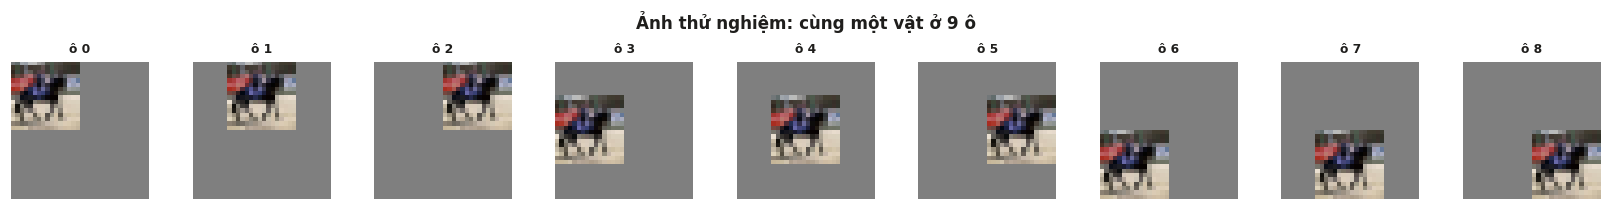

In [ ]:
OBJ_N = 600 if QUICK_TEST else 2000
obj_src = torch.arange(5000, 5000 + OBJ_N)
OBJ = F.interpolate(X_test[obj_src], size=16, mode="area")            # (N, 3, 16, 16) vật thu nhỏ
OBJ_Y = Y_test[obj_src]
CELLS = [(r * 8, c * 8) for r in range(3) for c in range(3)]          # góc trên-trái của 9 ô
half = OBJ_N // 2                                                     # vật 0..half-1 để train probe, còn lại để test


def place(objs, top, left):
    canvas = torch.zeros(len(objs), 3, 32, 32)                        # 0 = xám giữa trong [-1, 1]
    canvas[:, :, top:top + 16, left:left + 16] = objs
    return canvas


POS_X = torch.stack([place(OBJ, t, l) for t, l in CELLS], 1)          # (N, 9, 3, 32, 32)
FEAT_PIX = dict(FEAT, pixel=lambda x: x.flatten(1))
SPACES4 = NAMES + ["pixel"]
COL4 = dict(MODEL_COLORS, pixel="#7a7974")
LAB4 = dict(SPACE, pixel="pixel thô")
POS_F = {n: feats_of(FEAT_PIX[n], POS_X.flatten(0, 1)).reshape(OBJ_N, 9, -1) for n in SPACES4}

fig, axes = plt.subplots(1, 9, figsize=(15, 1.9))
for k, a in enumerate(axes):
    a.imshow(img_np(POS_X[0, k])); a.set_title(f"ô {k}", fontsize=8); noaxis(a)
fig.suptitle("Ảnh thử nghiệm: cùng một vật ở 9 ô", fontsize=11, fontweight="bold")
fig.tight_layout()
show(fig, "01i_position_stimuli.png")

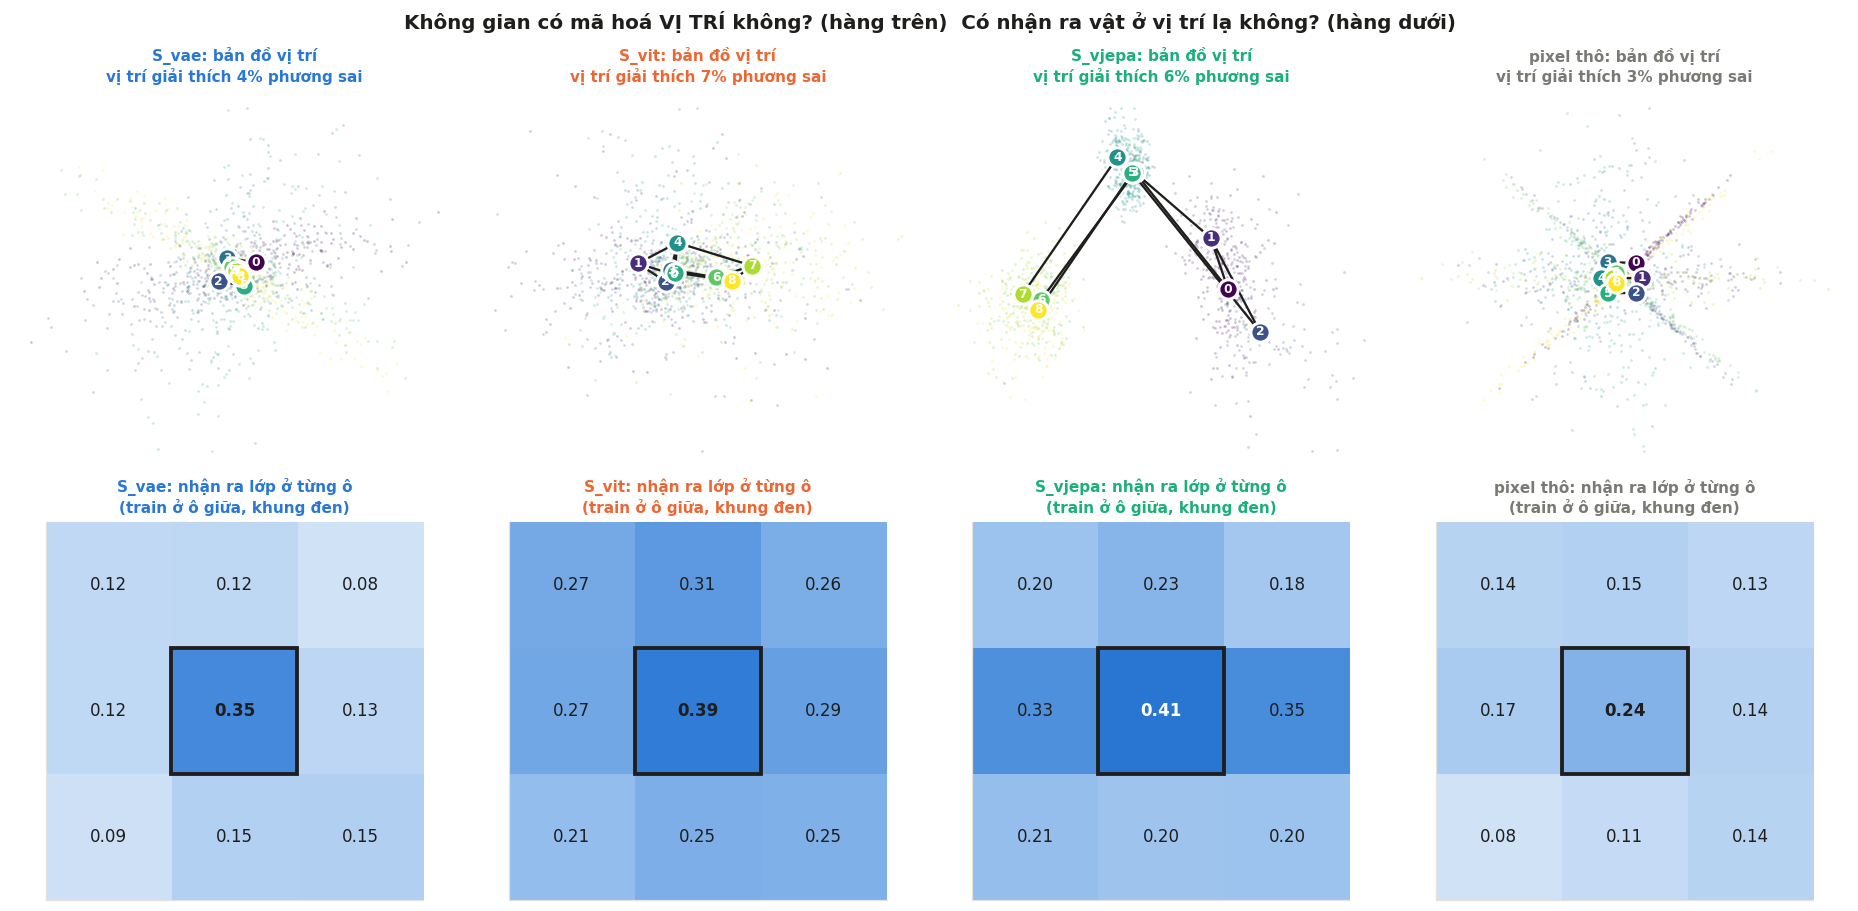

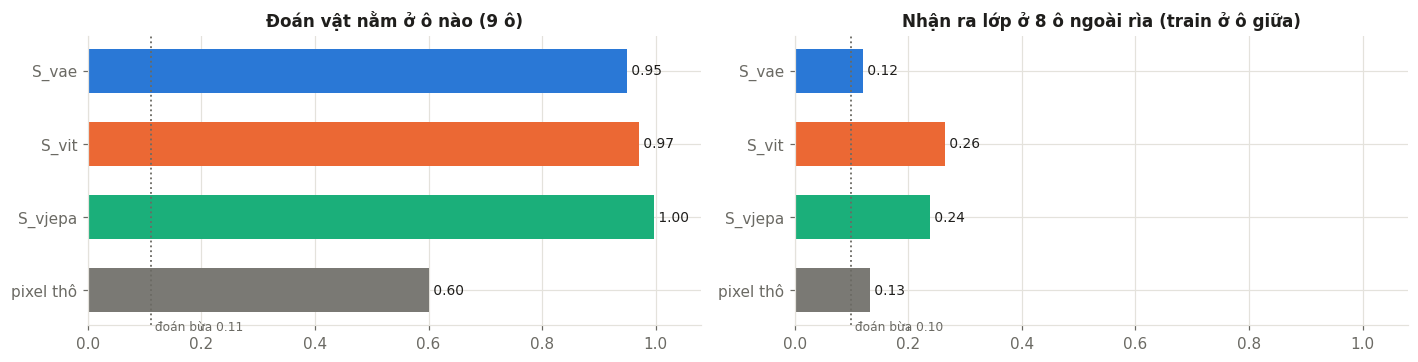

In [ ]:
def fit_probe(Xtr, ytr, Xte, yte):
    sc = StandardScaler().fit(Xtr)
    clf = LogisticRegression(max_iter=2000, C=0.5).fit(sc.transform(Xtr), ytr)
    pred = clf.predict(sc.transform(Xte))
    return float((pred == yte).mean()), pred


POS_RES = {}
fig, axes = plt.subplots(2, 4, figsize=(17, 8.4))
for j, n in enumerate(SPACES4):
    f = POS_F[n]
    # (1) bản đồ vị trí: bỏ phần "đây là vật gì" bằng cách trừ trung bình 9 vị trí của từng vật
    resid = f - f.mean(1, keepdim=True)
    pos_mean = resid.mean(0).numpy()                                   # (9, D)
    var_pos = float((resid.mean(0) ** 2).sum(-1).mean())
    var_tot = float(((f - f.mean((0, 1))) ** 2).sum(-1).mean())
    pca = PCA(2).fit(resid.reshape(-1, f.size(-1)).numpy())
    m2 = pca.transform(pos_mean)
    cloud = pca.transform(resid[:150].reshape(-1, f.size(-1)).numpy()).reshape(150, 9, 2)
    ax = axes[0, j]
    pos_cmap = plt.get_cmap("viridis")
    for k in range(9):
        ax.scatter(cloud[:, k, 0], cloud[:, k, 1], s=3, color=pos_cmap(k / 8), alpha=0.25, linewidths=0)
    for r in range(3):                                                 # nối các ô kề nhau thành lưới
        ax.plot(m2[r * 3:(r + 1) * 3, 0], m2[r * 3:(r + 1) * 3, 1], color=INK, lw=1.5)
        ax.plot(m2[r::3, 0], m2[r::3, 1], color=INK, lw=1.5)
    for k in range(9):
        ax.scatter(*m2[k], s=160, color=pos_cmap(k / 8), edgecolors="white", linewidths=2, zorder=3)
        ax.text(*m2[k], str(k), ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=4)
    noaxis(ax)
    ax.set_title(f"{LAB4[n]}: bản đồ vị trí\nvị trí giải thích {var_pos / var_tot:.0%} phương sai", color=COL4[n], fontsize=10)

    # (2) đoán ô từ vector (vật mới, chưa thấy khi train probe)
    cell_y = np.tile(np.arange(9), OBJ_N)
    Xa = f.reshape(-1, f.size(-1)).numpy()
    tr = np.repeat(np.arange(OBJ_N) < half, 9)
    acc_cell, pred_cell = fit_probe(Xa[tr], cell_y[tr], Xa[~tr], cell_y[~tr])

    # (3) train lớp ở ô giữa (ô 4), thử ở cả 9 ô
    acc_grid = np.zeros(9)
    sc = StandardScaler().fit(f[:half, 4].numpy())
    clf = LogisticRegression(max_iter=2000, C=0.5).fit(sc.transform(f[:half, 4].numpy()), OBJ_Y[:half].numpy())
    for k in range(9):
        acc_grid[k] = (clf.predict(sc.transform(f[half:, k].numpy())) == OBJ_Y[half:].numpy()).mean()
    POS_RES[n] = dict(var_pos=var_pos / var_tot, acc_cell=acc_cell, acc_grid=acc_grid,
                      cm=confusion_matrix(cell_y[~tr], pred_cell, normalize="true"))

    ax = axes[1, j]
    g = acc_grid.reshape(3, 3)
    im = ax.imshow(g, cmap=SEQ, vmin=0, vmax=max(0.6, float(g.max())))
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{g[r, c]:.2f}", ha="center", va="center", fontsize=11,
                    color="white" if g[r, c] > 0.4 else INK, fontweight="bold" if r == c == 1 else "normal")
    ax.add_patch(plt.Rectangle((0.5, 0.5), 1, 1, fill=False, ec=INK, lw=2.5))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{LAB4[n]}: nhận ra lớp ở từng ô\n(train ở ô giữa, khung đen)", color=COL4[n], fontsize=10)
fig.suptitle("Không gian có mã hoá VỊ TRÍ không? (hàng trên)  Có nhận ra vật ở vị trí lạ không? (hàng dưới)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "01j_position_map.png")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, key, t, chance in [(ax1, "acc_cell", "Đoán vật nằm ở ô nào (9 ô)", 1 / 9),
                           (ax2, "gen", "Nhận ra lớp ở 8 ô ngoài rìa (train ở ô giữa)", 0.1)]:
    vals = [POS_RES[n]["acc_cell"] if key == "acc_cell" else float(np.delete(POS_RES[n]["acc_grid"], 4).mean())
            for n in SPACES4]
    b = ax.barh([LAB4[n] for n in SPACES4], vals, color=[COL4[n] for n in SPACES4], height=0.6)
    for r_, v_ in zip(b, vals):
        ax.text(v_, r_.get_y() + r_.get_height() / 2, f" {v_:.2f}", va="center", fontsize=9)
    ax.axvline(chance, color=INK_MUTED, ls=":", lw=1.2)
    ax.text(chance, 3.55, f" đoán bừa {chance:.2f}", fontsize=8, color=INK_MUTED)
    ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.set_title(t); grid_style(ax)
fig.tight_layout()
show(fig, "01k_position_scores.png")

**Đọc hình vị trí**
- **Cả ba không gian đều biết vật nằm ở đâu.** Từ vector, bộ phân loại tuyến tính đoán đúng ô với độ chính xác 0,95 (VAE), 0,97 (ViT) và 1,00 (V-JEPA),
  cao hơn hẳn pixel thô (0,60). Mean-pool hay token `[CLS]` không xoá được vị trí.
- **Cách mã hoá khác nhau.** Ở V-JEPA, bản đồ vị trí tách rõ thành **3 cụm theo hàng** (trên / giữa / dưới), khớp với việc patch token của V-JEPA
  mã hoá vị trí dọc rất mạnh (mục 7). Ở VAE, vị trí nằm ở các hướng có phương sai nhỏ: PCA không thấy, nhưng probe vẫn đọc được.
- **Nhận ra vật ở vị trí lạ.** Đây là điểm yếu nhất của VAE: train ở ô giữa, sang ô khác chỉ còn ~0,12 (gần đoán bừa).
  Tức là cùng một vật đặt ở chỗ khác thì vector VAE trông như một vật khác. ViT và V-JEPA giữ được ~0,25. V-JEPA giữ tốt hơn khi vật dịch **ngang**
  (hàng giữa 0,33–0,35) so với dịch **dọc**.

### Chia khung hình 2×2: một vector có "nhìn thấy" từng góc ảnh không?

Ghép **4 vật khác nhau** (mỗi vật 16×16) vào 4 góc của một ảnh. Với mỗi góc, train một bộ phân loại tuyến tính đọc **lớp của vật ở góc đó**
từ vector của cả ảnh (trên 4 vật chưa từng thấy).
- Đọc được cả 4 góc = vector giữ "**cái gì ở đâu**" (bản đồ không gian).
- Chỉ đọc được lờ mờ = vector đã trộn cả ảnh thành một "tổng thể".

Đoán bừa = 0,10.

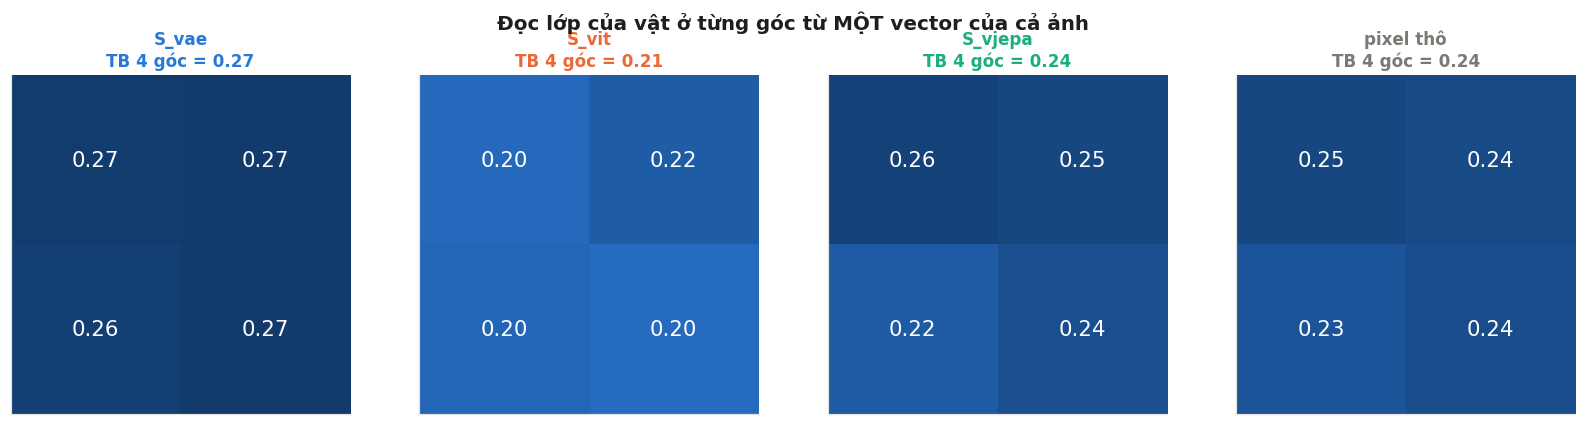

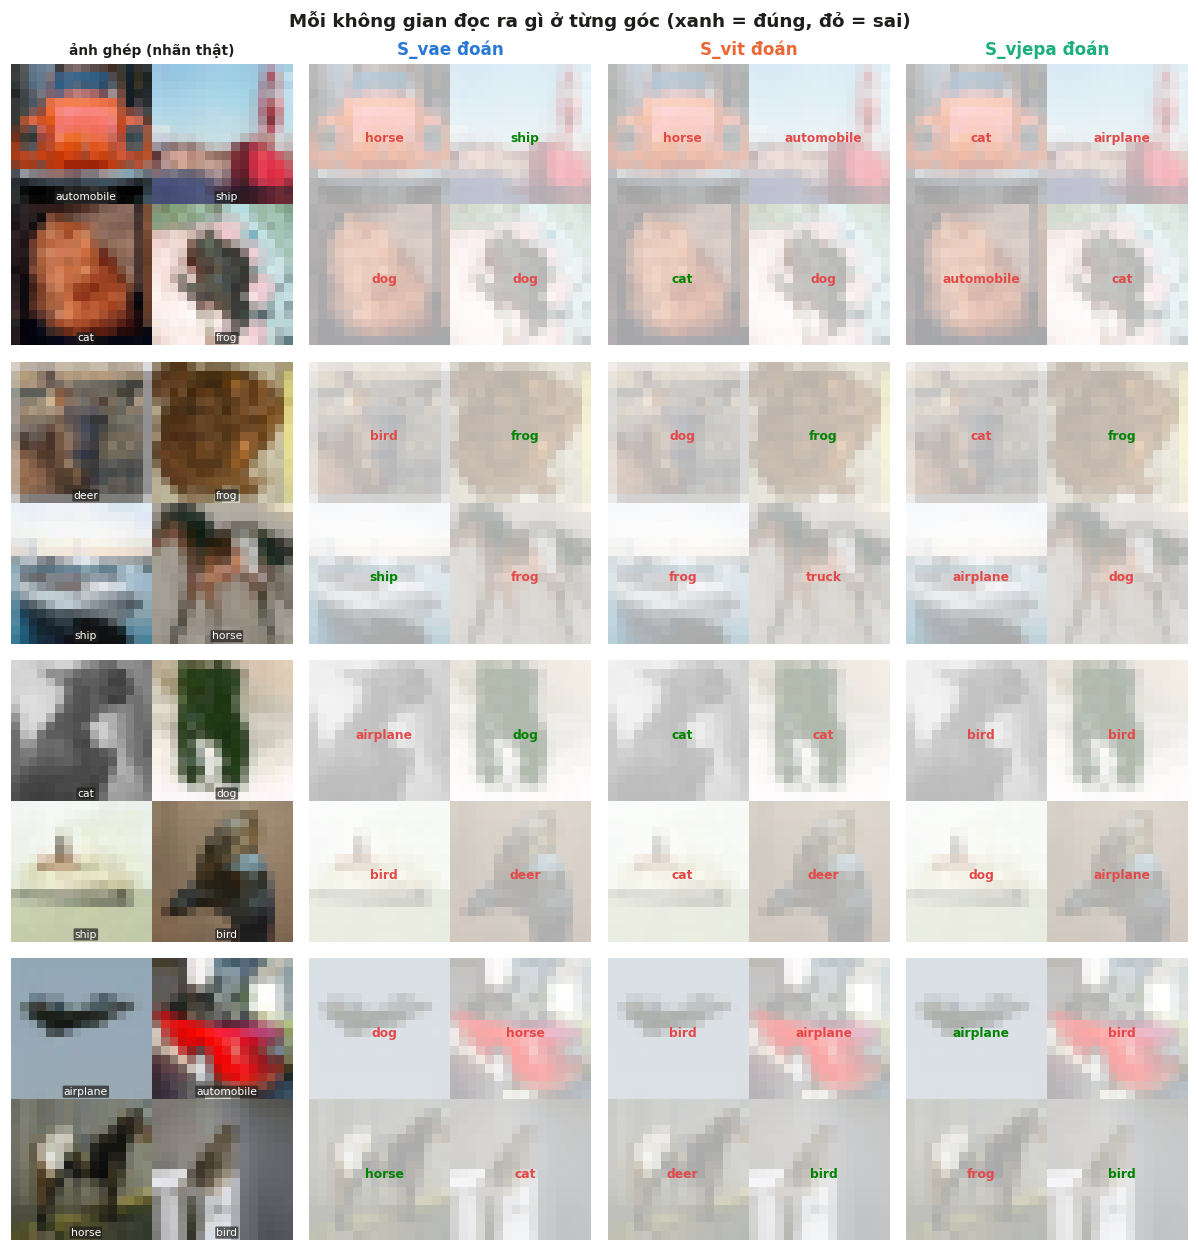

In [ ]:
N_COMP = 1000 if QUICK_TEST else 4000
QUADS = [(0, 0), (0, 16), (16, 0), (16, 16)]
QNAME = ["trên-trái", "trên-phải", "dưới-trái", "dưới-phải"]
rng_c = np.random.default_rng(SEED + 7)
comp_tr = np.arange(N_COMP) < int(0.75 * N_COMP)
# vật cho ảnh train lấy từ nửa đầu OBJ, vật cho ảnh test lấy từ nửa sau -> probe gặp vật mới
pick = np.where(comp_tr[:, None], rng_c.integers(0, half, (N_COMP, 4)), rng_c.integers(half, OBJ_N, (N_COMP, 4)))
COMP_X = torch.zeros(N_COMP, 3, 32, 32)
for q, (t, l) in enumerate(QUADS):
    COMP_X[:, :, t:t + 16, l:l + 16] = OBJ[pick[:, q]]
COMP_Y = OBJ_Y[pick].numpy()                                          # (N, 4) lớp ở từng góc
COMP_F = {n: feats_of(FEAT_PIX[n], COMP_X).numpy() for n in SPACES4}

QUAD_ACC, QUAD_PRED = {}, {}
for n in SPACES4:
    accs, preds = [], []
    for q in range(4):
        a_, p_ = fit_probe(COMP_F[n][comp_tr], COMP_Y[comp_tr, q], COMP_F[n][~comp_tr], COMP_Y[~comp_tr, q])
        accs.append(a_); preds.append(p_)
    QUAD_ACC[n], QUAD_PRED[n] = np.array(accs), np.stack(preds, 1)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
vmax = max(float(a.max()) for a in QUAD_ACC.values())
for ax, n in zip(axes, SPACES4):
    g = QUAD_ACC[n].reshape(2, 2)
    ax.imshow(g, cmap=SEQ, vmin=0, vmax=vmax)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{g[r, c]:.2f}", ha="center", va="center", fontsize=14,
                    color="white" if g[r, c] > 0.55 * vmax else INK)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{LAB4[n]}\nTB 4 góc = {QUAD_ACC[n].mean():.2f}", color=COL4[n])
fig.suptitle("Đọc lớp của vật ở từng góc từ MỘT vector của cả ảnh", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "01l_quadrant_probe.png")

# vài ví dụ: mỗi model đoán gì ở từng góc
test_ids = np.nonzero(~comp_tr)[0][:4]
fig, axes = plt.subplots(len(test_ids), 4, figsize=(11, 2.9 * len(test_ids)))
for i, t_ in enumerate(test_ids):
    test_row = int(np.nonzero(np.nonzero(~comp_tr)[0] == t_)[0][0])
    axes[i, 0].imshow(img_np(COMP_X[t_]))
    for q, (tt, ll) in enumerate(QUADS):
        axes[i, 0].text(ll + 8, tt + 15, CLASSES[COMP_Y[t_, q]], ha="center", fontsize=7, color="white",
                        bbox=dict(boxstyle="round,pad=0.1", fc=INK, ec="none", alpha=0.7))
    axes[i, 0].set_title("ảnh ghép (nhãn thật)" if i == 0 else "", fontsize=9)
    for j, n in enumerate(NAMES):
        a = axes[i, j + 1]
        a.imshow(img_np(COMP_X[t_]) * 0.35 + 0.65)
        for q, (tt, ll) in enumerate(QUADS):
            p_ = QUAD_PRED[n][test_row, q]
            ok = p_ == COMP_Y[t_, q]
            a.text(ll + 8, tt + 8, CLASSES[p_], ha="center", va="center", fontsize=8,
                   color=GOOD if ok else BAD, fontweight="bold")
        if i == 0:
            a.set_title(f"{SPACE[n]} đoán", color=MODEL_COLORS[n])
for a in axes.flat:
    noaxis(a)
fig.suptitle("Mỗi không gian đọc ra gì ở từng góc (xanh = đúng, đỏ = sai)", fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "01m_quadrant_examples.png")

**Đọc hình chia khung 2×2**

Đọc lớp của từng góc từ **một** vector của cả ảnh là bài khó với cả ba không gian (0,21–0,27, đoán bừa 0,10), vì mỗi vật chỉ 16×16 và ảnh ghép
khác hẳn dữ liệu train. Dù vậy, thứ tự vẫn có ý nghĩa:
- **VAE cao nhất (0,27), ngang pixel thô (0,24)**: để vẽ lại được ảnh, `mu` phải nhớ **bố cục** ("góc này màu gì, sáng hay tối"),
  nên phần nào đọc được từng góc.
- **ViT thấp nhất (0,21)**: nó được dạy trả lời **một** nhãn cho cả ảnh, nên trộn 4 vật thành một ấn tượng chung.
  Trong hình ví dụ, ViT hay đoán cùng một loại (cat, dog) cho nhiều góc.
- **V-JEPA ở giữa (0,24)**: giữ một phần thông tin theo vùng, vì mục tiêu của nó là dự đoán từng **vùng** bị che.
  Nhưng sau khi lấy trung bình 64 token thành một vector, chi tiết từng góc bị pha loãng.

## 2. Tín hiệu học trên từng ảnh

Cùng một ảnh, mỗi model bị "chấm điểm" theo một cách khác nhau. Hình dưới vẽ đúng cái mà loss của từng model so sánh:

- **VAE**: ảnh tái tạo `x̂` và **sai số từng pixel** `(x − x̂)²`. Mọi pixel đều đóng góp vào loss.
- **ViT**: phân phối xác suất trên 10 lớp so với nhãn thật. Cả ảnh chỉ cho **một con số** sai số.
- **V-JEPA**: ảnh bị che (chỉ context), token mục tiêu và token dự đoán (chiếu PCA → RGB, chỉ ở ô bị che), và **sai số L1 từng patch**.

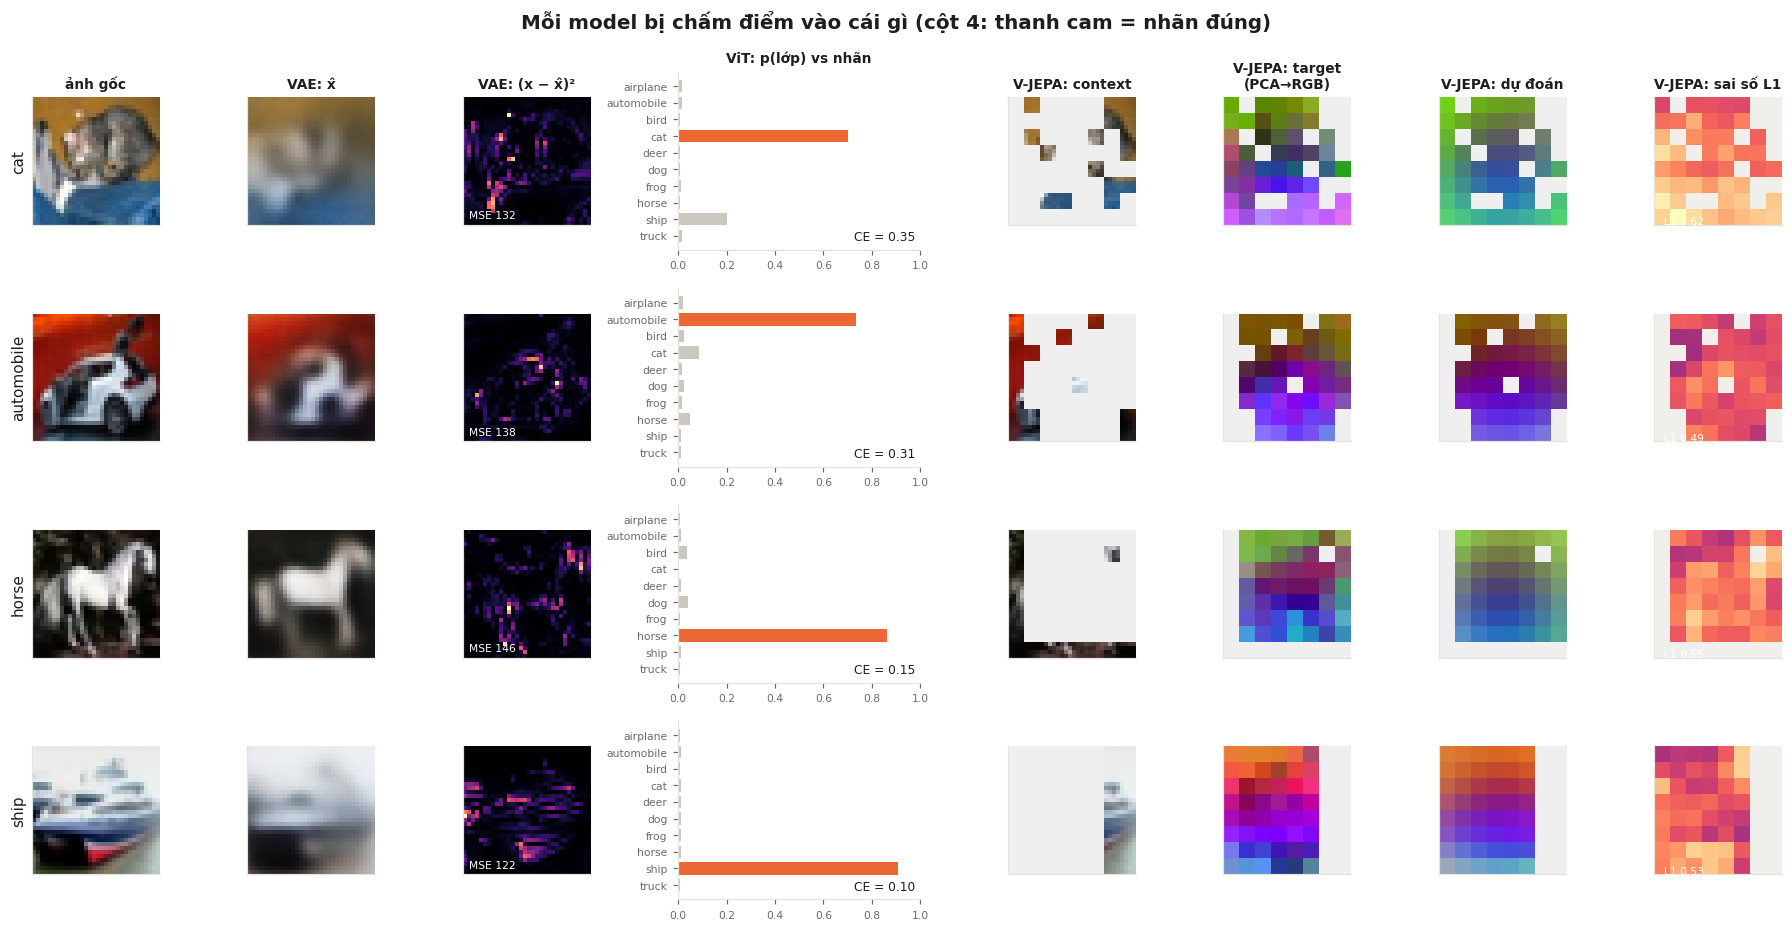

In [ ]:
N_SHOW = 4
show_idx = torch.tensor([int((Y_test == c).nonzero()[0]) for c in [3, 1, 7, 8]])   # ảnh test đầu tiên của: mèo, ô tô, ngựa, tàu
xs, ys = X_test[show_idx].to(device), Y_test[show_idx]
GRID_N = vj_tgt.grid                               # 8x8 patch


def fixed_mask(n, config, seed=0):
    """Mặt nạ V-JEPA tạo bởi MultiBlockMask với một cấu hình cố định (short-range hoặc long-range)."""
    random.seed(seed); torch.manual_seed(seed)
    return MultiBlockMask(GRID_N, configs=(config,))(n, device)


SHORT, LONG = (8, 0.15), (2, 0.7)


@torch.no_grad()
def vjepa_predict(x, keep_idx, mask_idx):
    h = vj_tgt(x)
    h = F.layer_norm(h, (h.size(-1),))
    tgt = gather_tokens(h, mask_idx)
    pred = vj_pred(vj_ctx(x, keep_idx), keep_idx, mask_idx)
    return h, tgt, pred


# PCA(3) của token mục tiêu -> màu RGB (fit trên nhiều ảnh)
with torch.no_grad():
    hh = vj_tgt(X_test[:500].to(device))
    hh = F.layer_norm(hh, (hh.size(-1),)).reshape(-1, hh.size(-1)).cpu().numpy()
tok_pca = PCA(3).fit(hh)
lo, hi = np.percentile(tok_pca.transform(hh), [2, 98], axis=0)


def tok_rgb(t):
    return np.clip((tok_pca.transform(t) - lo) / (hi - lo), 0, 1)


def scatter_tokens(tokens, idx, fill=0.94):
    """đặt token (K,D) vào lưới 8x8 tại vị trí idx; ô trống màu xám nhạt"""
    canvas = np.full((GRID_N * GRID_N, 3), fill)
    canvas[idx] = tok_rgb(tokens)
    return canvas.reshape(GRID_N, GRID_N, 3)


def masked_image(x, mask_idx, fill=0.94):
    im = img_np(x).copy()
    p = 32 // GRID_N
    for k in mask_idx.tolist():
        r, c = divmod(k, GRID_N)
        im[r * p:(r + 1) * p, c * p:(c + 1) * p] = fill
    return im


keep_idx, mask_idx = fixed_mask(N_SHOW, LONG)
with torch.no_grad():
    mu, _ = vae.encode(xs)
    recon = vae.decode(mu)
    probs = vit(xs).softmax(1).cpu()
_, tgt, pred = vjepa_predict(xs, keep_idx, mask_idx)
err_tok = (pred - tgt).abs().mean(-1).cpu()

cols = ["ảnh gốc", "VAE: x̂", "VAE: (x − x̂)²", "ViT: p(lớp) vs nhãn",
        "V-JEPA: context", "V-JEPA: target\n(PCA→RGB)", "V-JEPA: dự đoán", "V-JEPA: sai số L1"]
fig, axes = plt.subplots(N_SHOW, len(cols), figsize=(2.05 * len(cols), 2.15 * N_SHOW),
                         gridspec_kw={"width_ratios": [1, 1, 1, 1.9, 1, 1, 1, 1]})
for i in range(N_SHOW):
    ax = axes[i]
    ax[0].imshow(img_np(xs[i])); ax[0].set_ylabel(CLASSES[ys[i]], color=INK, fontsize=10)
    ax[1].imshow(img_np(recon[i]))
    e = ((xs[i] - recon[i]) ** 2).sum(0).cpu().numpy()
    ax[2].imshow(e, cmap=HEAT); ax[2].text(1, 30, f"MSE {e.sum():.0f}", color="white", fontsize=7)
    bars = ax[3].barh(range(10), probs[i].numpy(), color=[MODEL_COLORS["ViT"] if c == ys[i] else "#c9c7c0" for c in range(10)],
                      height=0.75)
    ax[3].set_yticks(range(10)); ax[3].set_yticklabels(CLASSES, fontsize=7); ax[3].invert_yaxis()
    ax[3].set_xlim(0, 1); ax[3].tick_params(axis="x", labelsize=7)
    ax[3].text(0.98, 9.3, f"CE = {-math.log(max(probs[i, ys[i]].item(), 1e-8)):.2f}", ha="right", fontsize=8)
    ax[4].imshow(masked_image(xs[i], mask_idx[i].cpu()))
    ax[5].imshow(scatter_tokens(tgt[i].cpu().numpy(), mask_idx[i].cpu().numpy()), interpolation="nearest")
    ax[6].imshow(scatter_tokens(pred[i].cpu().numpy(), mask_idx[i].cpu().numpy()), interpolation="nearest")
    em = np.full(GRID_N * GRID_N, np.nan); em[mask_idx[i].cpu().numpy()] = err_tok[i].numpy()
    cm_ = plt.get_cmap(HEAT).copy(); cm_.set_bad("#f0efec")              # ô không bị che: xám nhạt
    ax[7].imshow(np.ma.masked_invalid(em.reshape(GRID_N, GRID_N)), cmap=cm_, vmin=0, vmax=float(err_tok.max()), interpolation="nearest")
    ax[7].text(0.1, 7.5, f"L1 {err_tok[i].mean():.2f}", color="white", fontsize=7)
    for j, a in enumerate(ax):
        if j != 3:
            a.set_xticks([]); a.set_yticks([])
        if i == 0:
            a.set_title(cols[j], fontsize=9)
fig.suptitle("Mỗi model bị chấm điểm vào cái gì (cột 4: thanh cam = nhãn đúng)", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "02_learning_signal.png")

**Nhận xét**

- **VAE**: ảnh tái tạo mờ, MSE 120–146 mỗi ảnh. Sai số tập trung ở **biên và kết cấu** (tần số cao): VAE giữ được màu và hình khối lớn, và trả giá ở chi tiết.
- **ViT**: chắc chắn đúng nhãn (CE 0,10–0,35). Ảnh mèo nằm trên tấm vải xanh vẫn bị gán ~0,2 xác suất **ship**, dấu hiệu ViT dùng cả nền làm bằng chứng.
- **V-JEPA**: với mặt nạ long-range chỉ còn vài patch nhìn thấy, nhưng token dự đoán vẫn khớp **mẫu thô** của token mục tiêu (dải màu theo hàng, tức vị trí và bố cục chung) và mất chi tiết từng ô. Sai số L1 ~0,5–0,6.

**Độ "dày" của tín hiệu học.** Mỗi ảnh cung cấp bao nhiêu con số mục tiêu cho loss?
VAE: 3 072 giá trị pixel (+128 chiều KL). ViT: 1 nhãn (≈ log₂10 = 3,3 bit). V-JEPA: (số patch bị che) × 192 giá trị, và **các giá trị này thay đổi** theo target encoder trong lúc học.

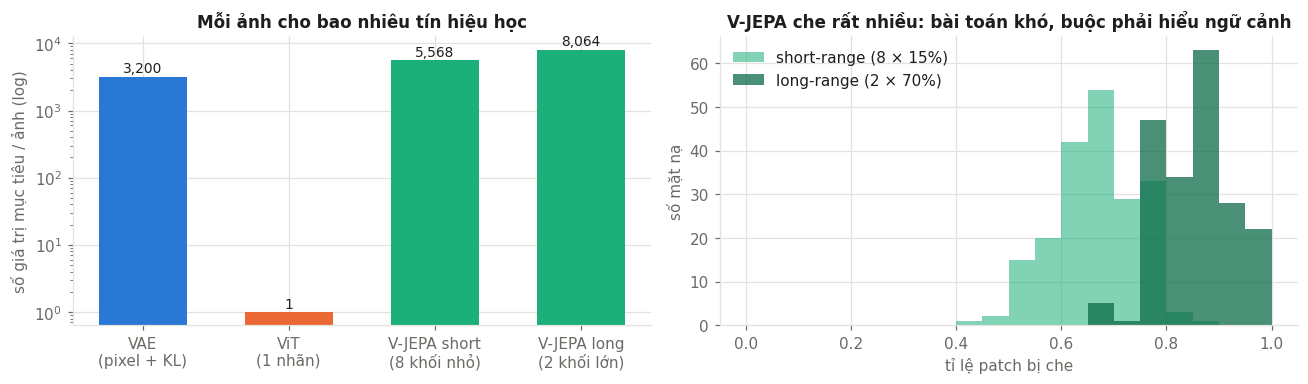

In [ ]:
_, m_short = fixed_mask(256, SHORT)
_, m_long = fixed_mask(256, LONG)
signal = {"VAE\n(pixel + KL)": 3 * 32 * 32 + 128,
          "ViT\n(1 nhãn)": 1,
          "V-JEPA short\n(8 khối nhỏ)": m_short.size(1) * 192,
          "V-JEPA long\n(2 khối lớn)": m_long.size(1) * 192}
cs = [MODEL_COLORS["VAE"], MODEL_COLORS["ViT"], MODEL_COLORS["V-JEPA"], MODEL_COLORS["V-JEPA"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
b = ax1.bar(list(signal), list(signal.values()), color=cs, width=0.6)
ax1.set_yscale("log"); ax1.set_ylabel("số giá trị mục tiêu / ảnh (log)")
for r, v in zip(b, signal.values()):
    ax1.text(r.get_x() + r.get_width() / 2, v * 1.15, f"{v:,}", ha="center", fontsize=9)
ax1.set_title("Mỗi ảnh cho bao nhiêu tín hiệu học"); grid_style(ax1)

ratios = {"short": [], "long": []}
for name, cfg in [("short", SHORT), ("long", LONG)]:
    mk = MultiBlockMask(GRID_N, configs=(cfg,))
    for s in range(200):
        random.seed(s)
        m = torch.zeros(GRID_N, GRID_N, dtype=torch.bool)
        for _ in range(cfg[0]):
            t, l, h, w = mk._block(cfg[1]); m[t:t + h, l:l + w] = True
        ratios[name].append(m.float().mean().item())
ax2.hist(ratios["short"], bins=20, range=(0, 1), color=MODEL_COLORS["V-JEPA"], alpha=0.55, label="short-range (8 × 15%)")
ax2.hist(ratios["long"], bins=20, range=(0, 1), color="#0d6b4a", alpha=0.75, label="long-range (2 × 70%)")
ax2.set_xlabel("tỉ lệ patch bị che"); ax2.set_ylabel("số mặt nạ"); ax2.legend()
ax2.set_title("V-JEPA che rất nhiều: bài toán khó, buộc phải hiểu ngữ cảnh"); grid_style(ax2)
fig.tight_layout()
show(fig, "02b_signal_density.png")

**Nhận xét**

- Mỗi ảnh cho ViT **1** con số mục tiêu, cho VAE **3 200**, cho V-JEPA **5 500–8 000**. ViT nhận ít tín hiệu nhất, nhưng mỗi tín hiệu lại **đúng thứ cần cho phân loại**.
- V-JEPA che **50–80%** (short-range) hoặc **75–100%** (long-range) số patch. Nó không thể "chép" từ hàng xóm như khi che ít, mà phải suy luận từ ngữ cảnh rộng.

## 3. Gradient theo pixel: model nhận tín hiệu học từ đâu?

Ta lấy **loss huấn luyện của chính model đó** trên một ảnh và tính `|∂loss/∂x|` (tổng 3 kênh màu).
Vùng sáng là pixel mà nếu thay đổi sẽ làm loss thay đổi nhiều, tức là nơi model đang "học" từ đó.

- VAE: loss tái tạo, nên gradient trải đều khắp ảnh, kể cả nền.
- ViT: cross-entropy với nhãn đúng, nên gradient tập trung ở vật thể phân biệt lớp.
- V-JEPA: loss dự đoán token bị che; gradient **chỉ** đến được các patch context (phần bị che đi qua target encoder có stop-grad). Viền xanh = vùng bị che.

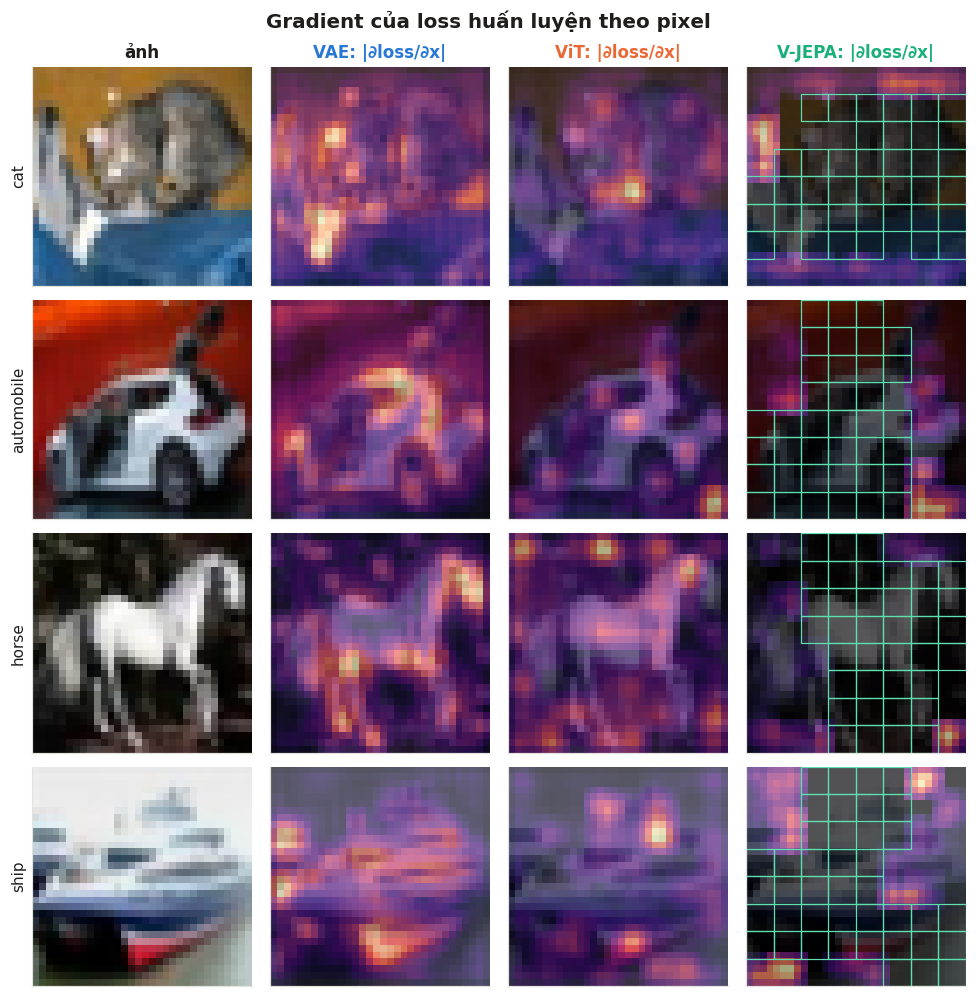

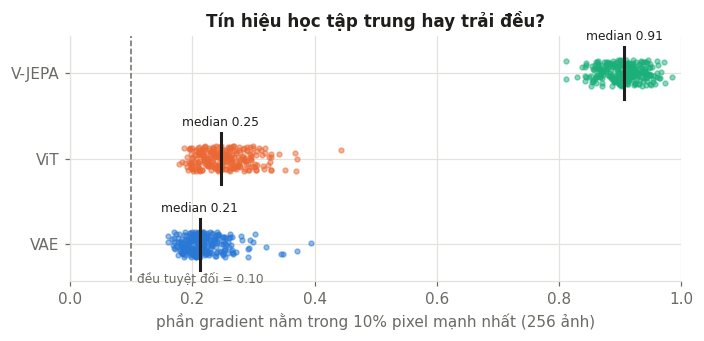

In [ ]:
def smooth(m, k=3):
    w = torch.ones(1, 1, k, k, device=m.device) / k ** 2
    return F.conv2d(m[:, None], w, padding=k // 2)[:, 0]


def saliency(name, x, y, keep_idx=None, mask_idx=None):
    x = x.clone().requires_grad_(True)
    if name == "VAE":
        mu, logvar = vae.encode(x)
        rec, kl = vae_loss(x, vae.decode(mu), mu, logvar)
        loss = rec + kl
    elif name == "ViT":
        loss = F.cross_entropy(vit(x), y.to(device), reduction="sum")
    else:
        with torch.no_grad():
            h = vj_tgt(x)
            tgt = gather_tokens(F.layer_norm(h, (h.size(-1),)), mask_idx)
        loss = F.l1_loss(vj_pred(vj_ctx(x, keep_idx), keep_idx, mask_idx), tgt, reduction="sum")
    g, = torch.autograd.grad(loss, x)
    s = smooth(g.abs().sum(1))
    return (s / s.flatten(1).amax(1)[:, None, None]).cpu().numpy()


keep_idx, mask_idx = fixed_mask(N_SHOW, SHORT, seed=3)
sal = {n: saliency(n, xs, ys, keep_idx, mask_idx) for n in NAMES}

fig, axes = plt.subplots(N_SHOW, 4, figsize=(9, 2.3 * N_SHOW))
for i in range(N_SHOW):
    axes[i, 0].imshow(img_np(xs[i])); axes[i, 0].set_ylabel(CLASSES[ys[i]], color=INK)
    for j, n in enumerate(NAMES):
        a = axes[i, j + 1]
        a.imshow(img_np(xs[i]) * 0.35 + 0.65 * plt.get_cmap(HEAT)(sal[n][i])[..., :3])
        if n == "V-JEPA":
            p = 32 // GRID_N
            for k in mask_idx[i].tolist():
                r, c = divmod(k, GRID_N)
                a.add_patch(plt.Rectangle((c * p - .5, r * p - .5), p, p, fill=False, ec="#5ee0b0", lw=0.8))
        if i == 0:
            a.set_title(f"{n}: |∂loss/∂x|", color=MODEL_COLORS[n])
    axes[i, 0].set_title("ảnh" if i == 0 else "")
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Gradient của loss huấn luyện theo pixel", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "03_saliency.png")

# định lượng: gradient tập trung tới đâu? (phần năng lượng nằm trong 10% pixel mạnh nhất)
sal_big = {}
xb, yb = X_test[:256].to(device), Y_test[:256]
kb, mb = fixed_mask(256, SHORT, seed=4)
for n in NAMES:
    s = torch.tensor(saliency(n, xb, yb, kb, mb)).flatten(1)
    s = s / s.sum(1, keepdim=True)
    sal_big[n] = s.sort(1, descending=True).values[:, : int(0.1 * s.size(1))].sum(1).numpy()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for k, n in enumerate(NAMES):
    v = sal_big[n]
    ax.scatter(v, np.full_like(v, k) + np.random.uniform(-0.15, 0.15, len(v)), s=10, color=MODEL_COLORS[n], alpha=0.5)
    ax.plot([np.median(v)] * 2, [k - 0.3, k + 0.3], color=INK, lw=2)
    ax.text(np.median(v), k + 0.38, f"median {np.median(v):.2f}", ha="center", fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels(NAMES); ax.set_xlim(0, 1)
ax.axvline(0.1, color=INK_MUTED, ls="--", lw=1); ax.text(0.11, -0.45, "đều tuyệt đối = 0.10", fontsize=8, color=INK_MUTED)
ax.set_xlabel("phần gradient nằm trong 10% pixel mạnh nhất (256 ảnh)")
ax.set_title("Tín hiệu học tập trung hay trải đều?"); grid_style(ax)
fig.tight_layout()
show(fig, "03b_saliency_concentration.png")

**Nhận xét**

- **Hình trên**: gradient của VAE trải dọc **mọi biên** trong ảnh, cả vật lẫn nền. ViT tập trung vào **vài điểm trên vật** (mặt mèo, thân ngựa, cabin tàu). V-JEPA chỉ có gradient ở các patch context, thường sát mép vùng bị che.
- **Hình dưới**: VAE (0,21) và ViT (0,25) đều khá dàn trải. V-JEPA rất tập trung (0,91), nhưng phần lớn là **do cách học**: chỉ 10–50% pixel (phần context) có thể nhận gradient, phần bị che luôn bằng 0.
- Trên 256 ảnh, ViT tập trung hơn VAE một chút và ổn định: nhãn chỉ cần vài vùng phân biệt, còn tái tạo cần mọi pixel.

## 4. Huấn luyện từ đầu, song song

Để thấy **quá trình** học (checkpoint chỉ cho kết quả cuối), ta train cả ba model từ khởi tạo ngẫu nhiên với **cùng dữ liệu, cùng batch, cùng số bước**
(`MINI` ở cell cấu hình: mặc định 20 000 ảnh × 25 epoch). 25 epoch đủ để thấy V-JEPA bắt đầu học và loss của nó đổi chiều. Kiến trúc và loss lấy đúng từ các script; augmentation là flip + dịch ±4 px làm trên GPU cho nhanh.

Trong lúc train ta ghi lại:
- loss của từng model (đơn vị khác nhau nên mỗi model một biểu đồ riêng),
- **kNN accuracy** của biểu diễn (VAE: `mu`, ViT: `[CLS]`, V-JEPA: target encoder), dù chỉ ViT được thấy nhãn,
- **effective rank** và **cos trung bình giữa hai ảnh khác nhau** (gần 1 = collapse),
- **norm gradient từng tầng** và **mức thay đổi trọng số so với khởi tạo**,
- ảnh chụp PCA của không gian ở vài thời điểm.

Mục 5 thêm một biến thể **V-JEPA không EMA**: target encoder là chính encoder và gradient chảy qua cả hai nhánh.

In [ ]:
def gpu_aug(x):
    B = x.size(0)
    x = torch.where((torch.rand(B, device=x.device) < 0.5)[:, None, None, None], x.flip(3), x)
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = theta[:, 1, 1] = 1
    theta[:, :, 2] = torch.randint(-4, 5, (B, 2), device=x.device).float() * 2 / 32
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode="nearest", padding_mode="reflection", align_corners=False)


def vit_groups(enc, extra_name, extra):
    return ([("patch embed", [enc.patch_embed])] +
            [(f"block {i + 1}", [b]) for i, b in enumerate(enc.blocks)] + [(extra_name, extra)])


def make_runner(kind, total_steps):
    r = dict(kind=kind, clip=None, post=None)
    if kind == "VAE":
        m = ConvVAE(32, 128).to(device)
        r.update(lr=1e-3, wd=0.0, modules=[m], feat=lambda x: m.encode(x)[0],
                 groups=[("enc conv1", [m.encoder[0]]), ("enc conv2", [m.encoder[1]]), ("enc conv3", [m.encoder[2]]),
                         ("mu / logvar", [m.fc_mu, m.fc_logvar]), ("dec fc", [m.fc_dec]),
                         ("dec up1", [m.decoder[0]]), ("dec up2", [m.decoder[1]]), ("dec out", [m.decoder[2]])])
        kl_warm = total_steps // MINI["epochs"]          # beta: 0 -> 1 trong epoch đầu (như script)

        def step(x, y, s):
            recon, mu, logvar = m(x)
            rec, kl = vae_loss(x, recon, mu, logvar)
            return rec + min(1.0, s / kl_warm) * kl, {"rec": rec.item(), "kl": kl.item()}
    elif kind == "ViT":
        m = ViTClassifier(10).to(device)
        r.update(lr=1e-3, wd=0.05, clip=1.0, modules=[m], feat=m.features,
                 groups=vit_groups(m.encoder, "norm + head", [m.encoder.norm, m.head]))

        def step(x, y, s):
            logits = m(x)
            return F.cross_entropy(logits, y, label_smoothing=0.1), {"acc": (logits.argmax(1) == y).float().mean().item()}
    else:   # "V-JEPA" hoặc "V-JEPA (no EMA)"
        enc = ViTEncoder(32, 4, 3, 192, 6, 3).to(device)
        pred = Predictor(enc.grid, 192).to(device)
        masker = MultiBlockMask(enc.grid)
        no_ema = kind != "V-JEPA"
        tgt = enc if no_ema else copy.deepcopy(enc).requires_grad_(False)
        r.update(lr=5e-4, wd=0.05, clip=1.0, modules=[enc, pred] if no_ema else [enc, pred, tgt],
                 feat=lambda x: tgt(x).mean(1),
                 groups=vit_groups(enc, "predictor", [pred]))

        def step(x, y, s):
            keep_idx, mask_idx = masker(x.size(0), device)
            with torch.set_grad_enabled(no_ema):        # bản chuẩn: stop-gradient ở nhánh target
                h = tgt(x)
                h = F.layer_norm(h, (h.size(-1),))
                t = gather_tokens(h, mask_idx)
            p = pred(enc(x, keep_idx), keep_idx, mask_idx)
            return F.l1_loss(p, t), {"mask_ratio": mask_idx.size(1) / enc.num_patches}

        if not no_ema:
            def post(s):
                mom = 0.996 + (1.0 - 0.996) * s / total_steps
                with torch.no_grad():
                    for pt, pc in zip(tgt.parameters(), enc.parameters()):
                        pt.mul_(mom).add_(pc.detach(), alpha=1 - mom)
            r["post"] = post
    r["step"] = step
    r["params"] = [p for mod in r["modules"] for p in mod.parameters() if p.requires_grad]
    r["opt"] = torch.optim.AdamW(r["params"], lr=r["lr"], weight_decay=r["wd"])
    return r


def group_params(groups):
    return [[p for mod in mods for p in mod.parameters()] for _, mods in groups]


def run_mini(kind, X, Y):
    set_seed(SEED)
    bs, E = MINI["batch_size"], MINI["epochs"]
    spe = len(X) // bs
    total = spe * E
    r = make_runner(kind, total)
    gparams = group_params(r["groups"])
    w0 = [[p.detach().clone() for p in ps] for ps in gparams]
    # đo dày ở epoch đầu (thay đổi nhanh nhất), sau đó cuối mỗi epoch
    eval_steps = sorted({0, *np.round(np.geomspace(1, spe, 5)).astype(int).tolist(), *[spe * e for e in range(1, E + 1)]})
    log = dict(kind=kind, total=total, spe=spe, groups=[n for n, _ in r["groups"]],
               step=[], loss=[], extra=[], grad=[], wchg=[], ev_step=[], knn=[], erank=[], mcos=[], snaps={})

    def evaluate(s):
        for mod in r["modules"]:
            mod.eval()
        ftr, fte = feats_of(r["feat"], Xm_ptr), feats_of(r["feat"], Xm_pte)
        log["ev_step"].append(s); log["knn"].append(knn(ftr, Ym_ptr, fte, Ym_pte))
        log["erank"].append(eff_rank(fte)); log["mcos"].append(mean_cos(fte))
        log["snaps"][s] = fte[:1000].numpy()
        for mod in r["modules"]:
            mod.train()

    evaluate(0)
    run_loss, run_n, t_train, s = 0.0, 0, 0.0, 0
    for ep in range(E):
        perm = torch.randperm(len(X), device=X.device)
        for i in range(spe):
            idx = perm[i * bs:(i + 1) * bs]
            x, y = gpu_aug(X[idx]), Y[idx]
            torch.cuda.synchronize() if device.type == "cuda" else None
            t0 = time.perf_counter()
            set_lr(r["opt"], cosine_lr(s, total, spe, r["lr"]))
            loss, extra = r["step"](x, y, s)
            r["opt"].zero_grad(set_to_none=True)
            loss.backward()
            logging = (s + 1) % MINI["log_every"] == 0
            if logging:
                gn = [math.sqrt(sum(float(p.grad.pow(2).sum()) for p in ps if p.grad is not None)) for ps in gparams]
            if r["clip"]:
                torch.nn.utils.clip_grad_norm_(r["params"], r["clip"])
            r["opt"].step()
            if r["post"]:
                r["post"](s)
            torch.cuda.synchronize() if device.type == "cuda" else None
            t_train += time.perf_counter() - t0
            run_loss += loss.item(); run_n += 1
            s += 1
            if logging:
                with torch.no_grad():
                    wc = [math.sqrt(sum(float((p - q).pow(2).sum()) for p, q in zip(ps, qs))) /
                          math.sqrt(sum(float(q.pow(2).sum()) for q in qs) + 1e-12) for ps, qs in zip(gparams, w0)]
                log["step"].append(s); log["loss"].append(run_loss / run_n); log["extra"].append(extra)
                log["grad"].append(gn); log["wchg"].append(wc)
                run_loss, run_n = 0.0, 0
            if s in eval_steps:
                evaluate(s)
        print(f"  [{kind}] epoch {ep + 1}/{E}  loss {log['loss'][-1]:.4f}  kNN {log['knn'][-1]:.3f}  "
              f"rank {log['erank'][-1]:.1f}  cos {log['mcos'][-1]:.3f}")
    log["ms_per_step"] = 1000 * t_train / total
    log["n_params"] = sum(p.numel() for p in r["params"])
    return log


# dữ liệu train nhỏ (trên GPU) + probe nhỏ để đo nhanh trong lúc train
mini_idx = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(1))[:MINI["n_train"]]
Xm, Ym = X_train[mini_idx].to(device), Y_train[mini_idx].to(device)
Xm_ptr, Ym_ptr = X_train[mini_idx[:5000]], Y_train[mini_idx[:5000]]     # bộ nhớ kNN (ảnh đã thấy, không aug)
Xm_pte, Ym_pte = X_test[:2000], Y_test[:2000]

In [ ]:
RUNS = ["VAE", "ViT", "V-JEPA", "V-JEPA (no EMA)"]
logs = {}
for k in RUNS:
    t0 = time.time()
    print(f"train {k} ...")
    logs[k] = run_mini(k, Xm, Ym)
    print(f"  -> {time.time() - t0:.0f}s, {logs[k]['ms_per_step']:.1f} ms/step, {logs[k]['n_params']/1e6:.2f}M tham số học")

### 4.1 Loss và chất lượng biểu diễn theo thời gian

Hàng trên: loss của từng model (mỗi model một trục vì đơn vị khác nhau). Hàng dưới: ba thước đo **chung** cho mọi model.
Chú ý: loss giảm **không** có nghĩa biểu diễn tốt hơn. Bản V-JEPA không EMA có loss tiến về 0 nhưng kNN thì tụt;
ngược lại, loss của V-JEPA chuẩn lại **tăng** trong khi kNN tăng.

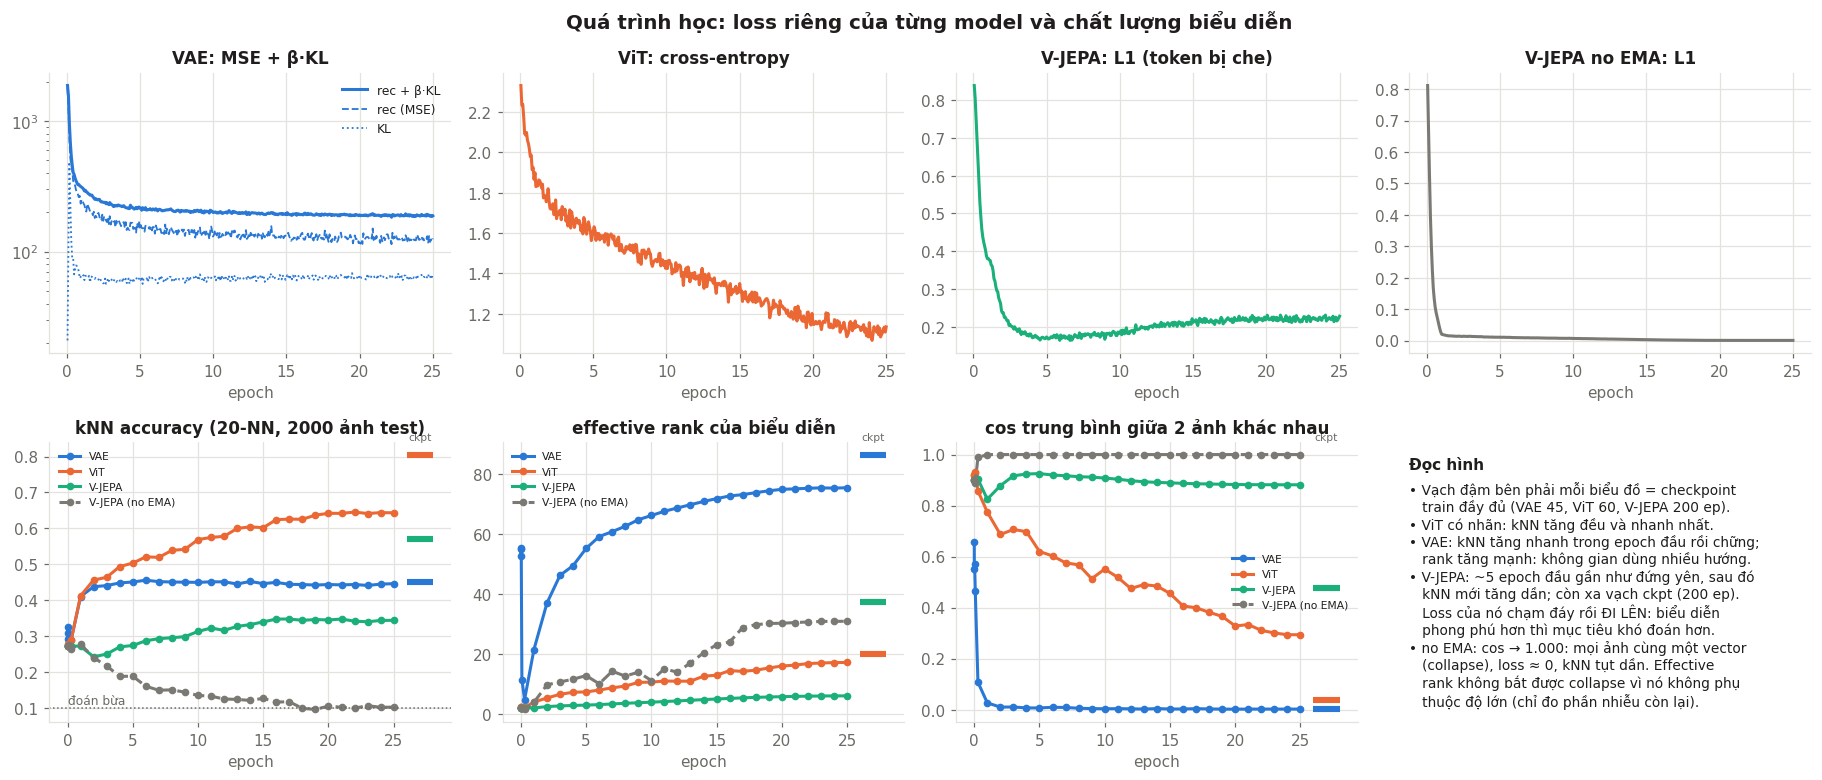

In [ ]:
def ep(log, steps):
    return np.asarray(steps) / log["spe"]


fig, axes = plt.subplots(2, 4, figsize=(17, 7.2))
for ax, k in zip(axes[0], RUNS):
    L = logs[k]
    ax.plot(ep(L, L["step"]), L["loss"], color=MODEL_COLORS[k], lw=2)
    if k == "VAE":
        rec = [e["rec"] for e in L["extra"]]; kl = [e["kl"] for e in L["extra"]]
        ax.plot(ep(L, L["step"]), rec, color=MODEL_COLORS[k], lw=1.2, ls="--")
        ax.plot(ep(L, L["step"]), kl, color=MODEL_COLORS[k], lw=1.2, ls=":")
        ax.legend(handles=[Line2D([], [], color=MODEL_COLORS[k], lw=2, label="rec + β·KL"),
                           Line2D([], [], color=MODEL_COLORS[k], lw=1.2, ls="--", label="rec (MSE)"),
                           Line2D([], [], color=MODEL_COLORS[k], lw=1.2, ls=":", label="KL")], fontsize=8)
        ax.set_yscale("log")
    ax.set_title({"VAE": "VAE: MSE + β·KL", "ViT": "ViT: cross-entropy",
                  "V-JEPA": "V-JEPA: L1 (token bị che)", "V-JEPA (no EMA)": "V-JEPA no EMA: L1"}[k], color=INK)
    ax.set_xlabel("epoch"); grid_style(ax)

# mức của checkpoint đã train đầy đủ, đo trên đúng probe này -> "đích" để so sánh
ref = {}
for n in NAMES:
    ftr, fte = feats_of(FEAT[n], Xm_ptr), feats_of(FEAT[n], Xm_pte)
    ref[n] = {"knn": knn(ftr, Ym_ptr, fte, Ym_pte), "erank": eff_rank(fte), "mcos": mean_cos(fte)}

titles = [("knn", "kNN accuracy (20-NN, 2000 ảnh test)"), ("erank", "effective rank của biểu diễn"),
          ("mcos", "cos trung bình giữa 2 ảnh khác nhau")]
for ax, (key, t) in zip(axes[1], titles):
    for k in RUNS:
        L = logs[k]
        ax.plot(ep(L, L["ev_step"]), L[key], color=MODEL_COLORS[k], lw=2, marker="o", ms=4,
                ls="--" if "no EMA" in k else "-", label=k)
    for n in NAMES:   # vạch đậm bên phải = giá trị của checkpoint đã train đầy đủ
        ax.plot([MINI["epochs"] * 1.04, MINI["epochs"] * 1.12], [ref[n][key]] * 2, color=MODEL_COLORS[n], lw=4,
                solid_capstyle="butt")
    ax.text(MINI["epochs"] * 1.08, ax.get_ylim()[1], "ckpt", ha="center", va="bottom", fontsize=7, color=INK_MUTED)
    if key == "knn":
        ax.axhline(0.1, color=INK_MUTED, lw=1, ls=":"); ax.text(0, 0.11, "đoán bừa", fontsize=8, color=INK_MUTED)
    ax.set_title(t, color=INK); ax.set_xlabel("epoch"); grid_style(ax)
for ax in axes[1, :3]:
    ax.legend(fontsize=7, loc="best")
axes[1, 3].axis("off")
axes[1, 3].text(0, 0.95, "Đọc hình", fontweight="bold", va="top")
axes[1, 3].text(0, 0.86, "• Vạch đậm bên phải mỗi biểu đồ = checkpoint\n   train đầy đủ (VAE 45, ViT 60, V-JEPA 200 ep).\n"
                "• ViT có nhãn: kNN tăng đều và nhanh nhất.\n"
                "• VAE: kNN tăng nhanh trong epoch đầu rồi chững;\n   rank tăng mạnh: không gian dùng nhiều hướng.\n"
                "• V-JEPA: ~5 epoch đầu gần như đứng yên, sau đó\n   kNN mới tăng dần; còn xa vạch ckpt (200 ep).\n"
                "   Loss của nó chạm đáy rồi ĐI LÊN: biểu diễn\n   phong phú hơn thì mục tiêu khó đoán hơn.\n"
                "• no EMA: cos → 1.000: mọi ảnh cùng một vector\n   (collapse), loss ≈ 0, kNN tụt dần. Effective\n   rank không bắt được collapse vì nó không phụ\n   thuộc độ lớn (chỉ đo phần nhiễu còn lại).",
                va="top", fontsize=9, color=INK)
fig.suptitle("Quá trình học: loss riêng của từng model và chất lượng biểu diễn", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "04_training_curves.png")

**Nhận xét**

- **VAE**: loss giảm nhanh trong 2 epoch đầu rồi giảm chậm tới cuối, nhưng **kNN chạm trần ~0,45 từ epoch 2** và không nhích nữa. Effective rank thì tăng đều lên ~75. VAE tiếp tục học, nhưng thứ nó học thêm là **chi tiết để vẽ lại ảnh**, không phải thông tin lớp. Mức này đã bằng checkpoint 45 epoch (vạch xanh).
- **ViT**: CE giảm đều từ 2,3 xuống ~1,13, kNN tăng đều lên **0,64** và bắt đầu phẳng từ epoch 20 khi learning rate giảm về 0. Rank tăng chậm (~17) và cos giữa các ảnh giảm mạnh (0,9 → 0,3): không gian **tách ra theo lớp** nhưng chỉ dùng ít hướng.
- **V-JEPA**: kNN **giảm nhẹ trong 2–3 epoch đầu** (0,27 → 0,24), rồi tăng đều tới **0,35** ở epoch 16 và phẳng từ đó. Loss chạm đáy ~0,17 ở epoch 5 rồi **đi lên** ~0,22. Rank chỉ ~6, cos giữa các ảnh còn ~0,88: biểu diễn mới bắt đầu "nở ra", còn rất xa checkpoint 200 epoch (kNN 0,57).
- **no EMA**: loss về gần 0, cos = 1,000, kNN tụt về 0,10. Effective rank lại **tăng** (~31) vì nó không phụ thuộc độ lớn, nên chỉ đo phần nhiễu cực nhỏ còn lại. Cần nhìn cos hoặc phương sai tuyệt đối (mục 5) mới thấy collapse.
- Tổng kết: sau cùng một ngân sách 25 epoch, thứ tự kNN là **ViT 0,64 > VAE 0,45 > V-JEPA 0,34**. Nhãn cho tín hiệu ngữ nghĩa nhanh nhất; tái tạo pixel cho một mức ngữ nghĩa "miễn phí" nhưng có trần thấp; V-JEPA là cách chậm nhất, nhưng là cách duy nhất về lâu dài vượt được VAE mà không cần nhãn.

### 4.2 Gradient chảy vào tầng nào, trọng số tầng nào thay đổi nhiều?

Mỗi hàng là một nhóm tham số (tầng), mỗi cột là một thời điểm. Màu = log₁₀ của norm gradient (trước khi clip).
- **VAE**: gradient lớn nhất ở decoder (gần pixel); encoder chỉ nhận tín hiệu gián tiếp qua decoder.
- **ViT**: gradient đến từ head, đi ngược qua các block.
- **V-JEPA**: predictor và encoder cùng học; tín hiệu đến từ việc khớp token, không phải pixel hay nhãn.

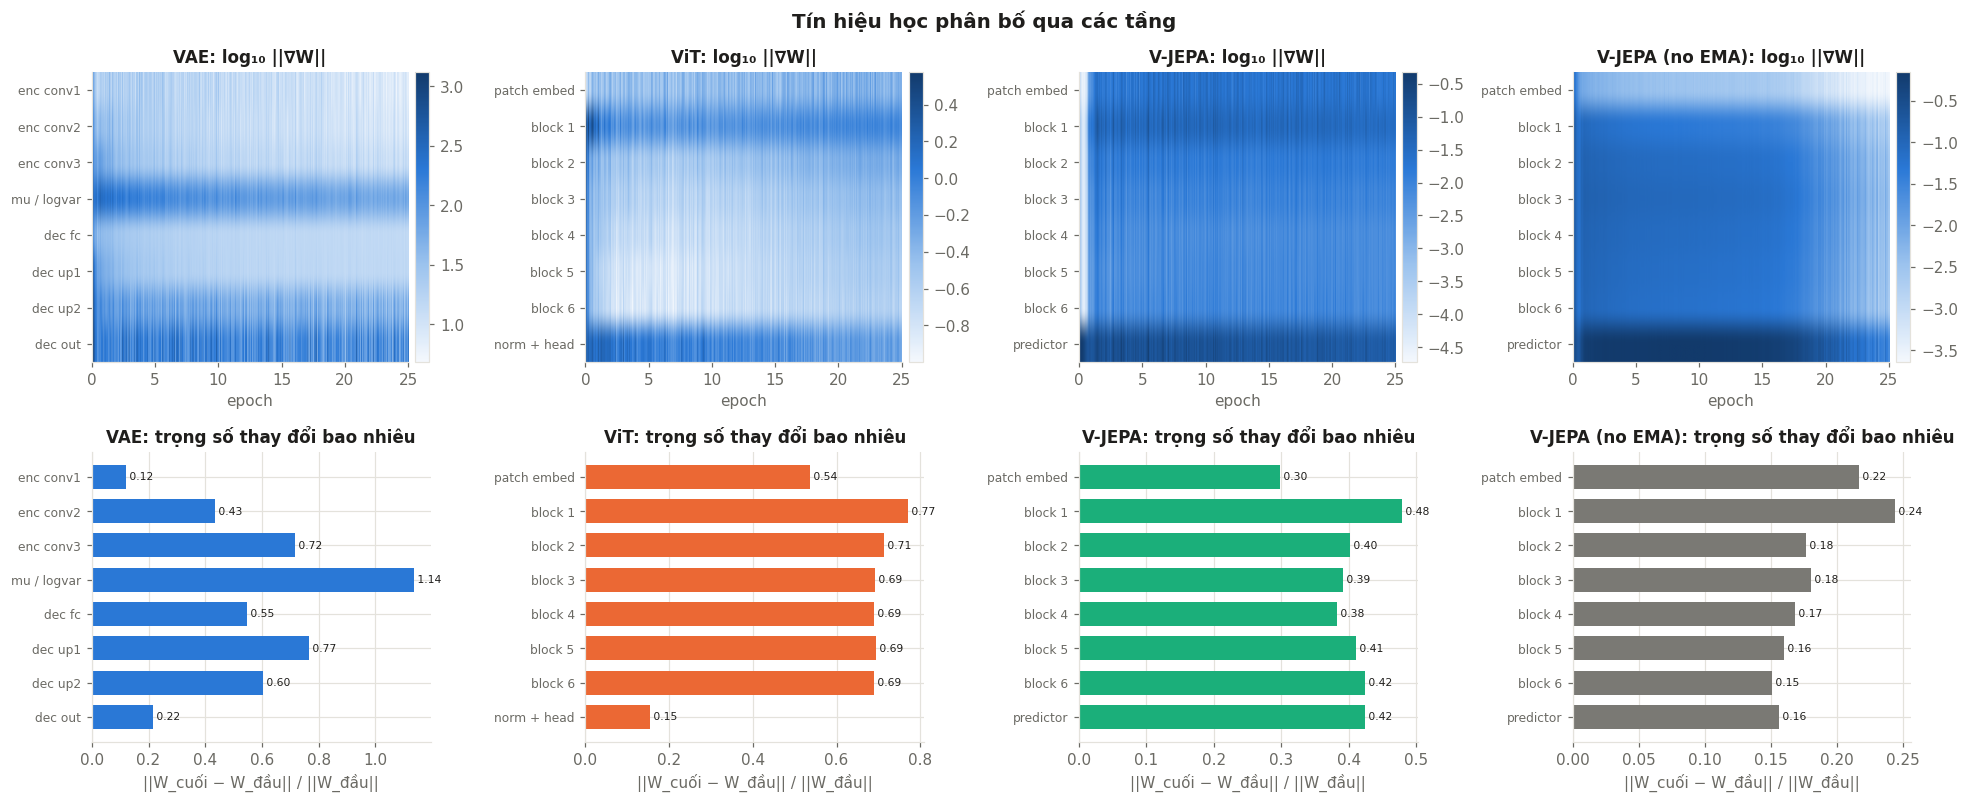

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.4), gridspec_kw={"height_ratios": [1, 1]})
for j, k in enumerate(RUNS):
    L = logs[k]
    G = np.log10(np.array(L["grad"]).T + 1e-12)
    ax = axes[0, j]
    im = ax.imshow(G, aspect="auto", cmap=SEQ, extent=[0, L["step"][-1] / L["spe"], len(L["groups"]) - 0.5, -0.5])
    ax.set_yticks(range(len(L["groups"]))); ax.set_yticklabels(L["groups"], fontsize=8)
    ax.set_title(f"{k}: log₁₀ ||∇W||", color=INK); ax.set_xlabel("epoch")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

    W = np.array(L["wchg"])[-1]
    ax = axes[1, j]
    ax.barh(range(len(W)), W, color=MODEL_COLORS[k], height=0.7)
    ax.set_yticks(range(len(W))); ax.set_yticklabels(L["groups"], fontsize=8); ax.invert_yaxis()
    for i, v in enumerate(W):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=7)
    ax.set_xlabel("||W_cuối − W_đầu|| / ||W_đầu||"); ax.set_title(f"{k}: trọng số thay đổi bao nhiêu", color=INK)
    grid_style(ax)
fig.suptitle("Tín hiệu học phân bố qua các tầng", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "04b_gradients_per_layer.png")

**Nhận xét**

- **VAE**: gradient lớn nhất ở `mu / logvar` (điểm thắt cổ chai, nơi cả MSE lẫn KL cùng tác động) và ở decoder. Trọng số `mu / logvar` đổi nhiều nhất (1,14 lần độ lớn ban đầu), còn `enc conv1` đổi ít nhất (0,12): **VAE học chủ yếu ở nút thắt và decoder**, tầng đầu của encoder gần như giữ nguyên.
- **ViT**: gradient mạnh ở head và block 1 suốt quá trình. Mọi block đổi gần **đều nhau** (0,69–0,77), head đổi ít (0,15): tín hiệu nhãn lan ngược đều qua toàn bộ encoder.
- **V-JEPA**: ở đầu quá trình, gradient vào encoder **rất nhỏ** (warmup, và target ≈ encoder nên chưa có gì để khớp), sau đó tăng và giữ ổn định. Block 1 (0,48) và predictor (0,42) đổi nhiều nhất; nhìn chung trọng số đổi ít hơn ViT khoảng 40%.
- **V-JEPA no EMA**: trọng số đổi **ít nhất** trong bốn model (0,15–0,24). Model tìm ra lời giải tầm thường (mọi ảnh → một vector) rất sớm, nên gần như không còn gì để học.

### 4.3 Không gian biểu diễn tiến hoá

PCA 2D của 1 000 ảnh test tại vài thời điểm, tô màu theo lớp (model không dùng màu này khi học, trừ ViT).

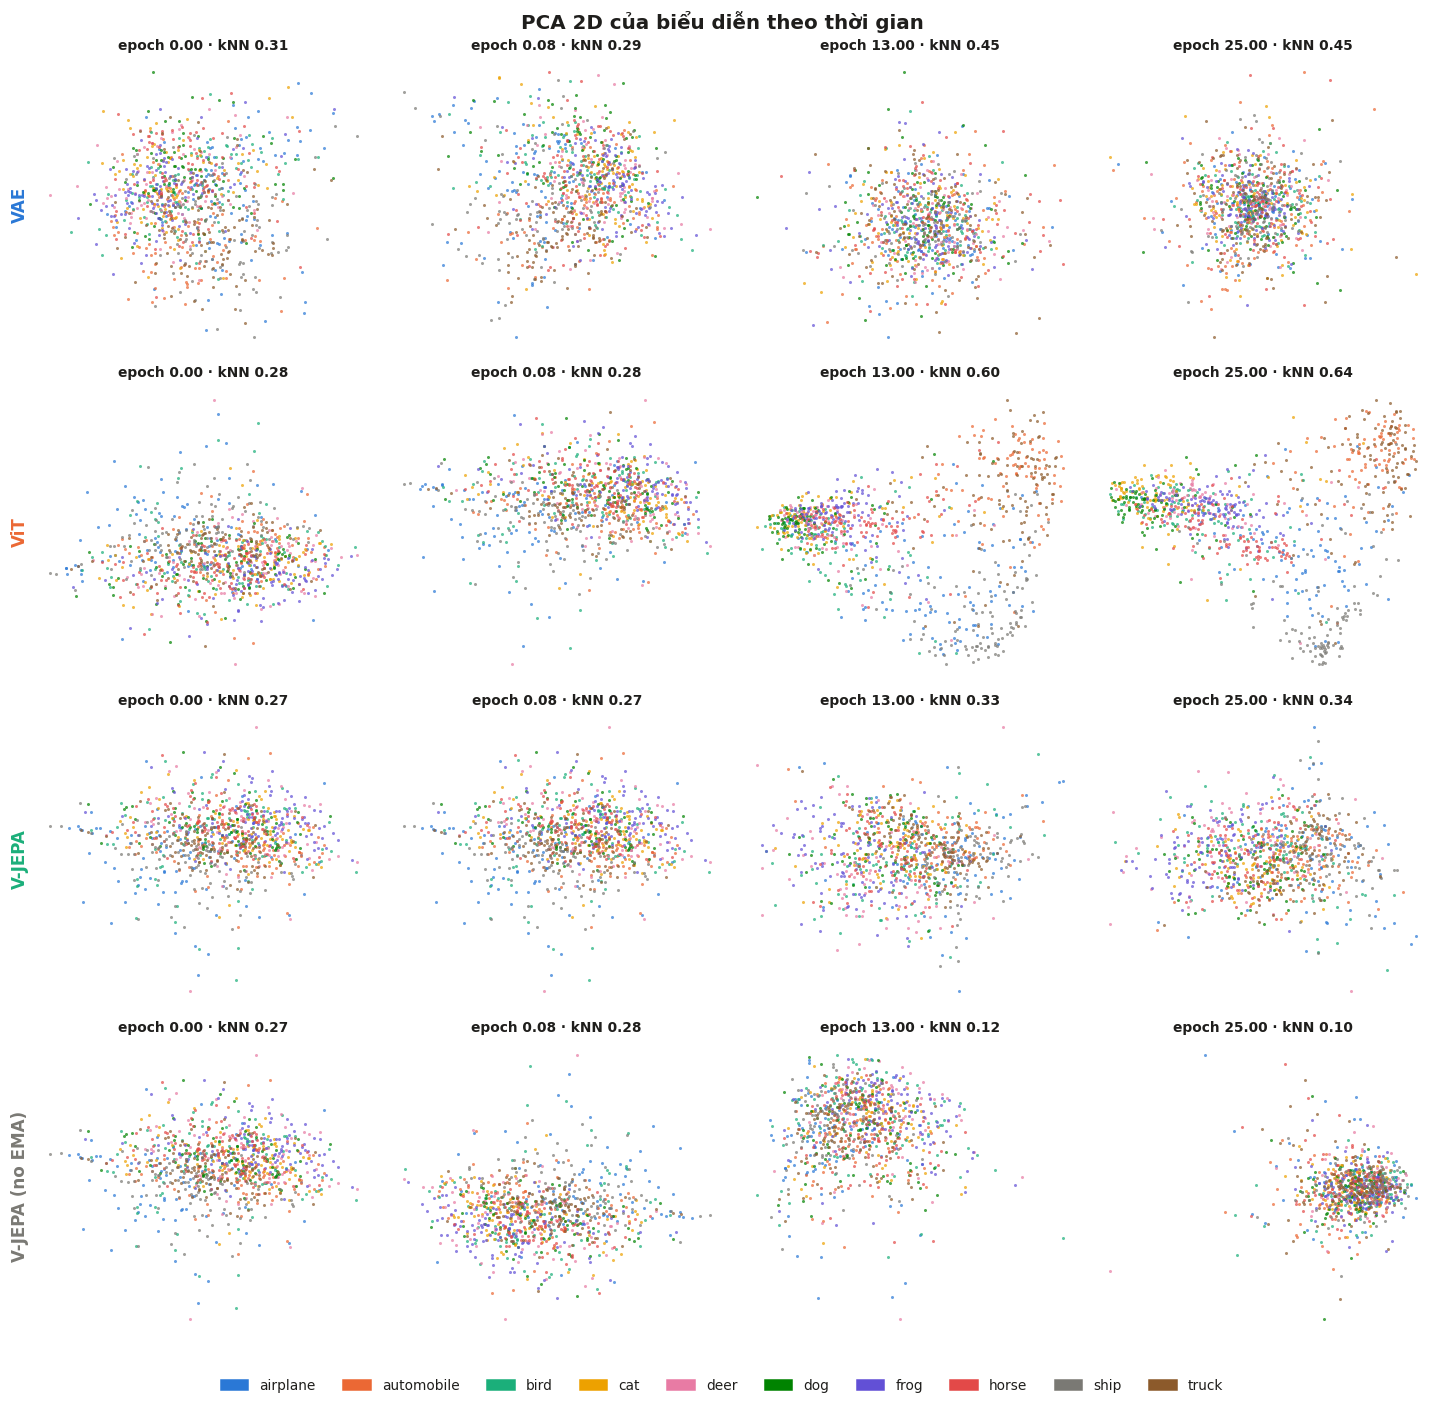

In [ ]:
snap_runs = RUNS
ev = logs["ViT"]["ev_step"]
pick = sorted({ev[0], ev[min(3, len(ev) - 1)], ev[-1 - MINI["epochs"] // 2], ev[-1]})   # đầu, giữa epoch 1, giữa, cuối
y_snap = Ym_pte[:1000].numpy()
fig, axes = plt.subplots(len(snap_runs), len(pick), figsize=(3.3 * len(pick), 3.2 * len(snap_runs)))
for i, k in enumerate(snap_runs):
    L = logs[k]
    for j, s in enumerate(pick):
        ax = axes[i, j]
        f = L["snaps"][s]
        if np.allclose(f.std(0), 0):
            z = np.zeros((len(f), 2))
        else:
            z = PCA(2).fit_transform(StandardScaler().fit_transform(f))
        for c in range(10):
            sel = y_snap == c
            ax.scatter(z[sel, 0], z[sel, 1], s=4, color=CLASS_COLORS[c], alpha=0.7, linewidths=0)
        noaxis(ax)
        kn = L["knn"][L["ev_step"].index(s)]
        ax.set_title(f"epoch {s / L['spe']:.2f} · kNN {kn:.2f}", fontsize=9, color=INK)
        if j == 0:
            ax.set_ylabel(k, color=MODEL_COLORS[k], fontsize=11, fontweight="bold")
fig.legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASSES[c]) for c in range(10)],
           loc="lower center", ncol=10, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("PCA 2D của biểu diễn theo thời gian", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 1))
show(fig, "04c_space_evolution.png")

**Nhận xét**

- **ViT**: ở epoch 13 không gian đã tách thành **hai khối lớn**: động vật (dog, cat, frog, deer) dồn về một phía, xe cộ (truck, automobile) ở góc đối diện, ship tách xuống dưới. Tới epoch 25 các khối này sắc nét hơn (kNN 0,60 → 0,64).
- **VAE**: co lại thành một đám tròn rồi giữ nguyên hình dạng; kNN đứng ở 0,45 từ epoch 13 tới cuối dù loss vẫn giảm.
- **V-JEPA**: vẫn là một đám mây trộn lớp (kNN 0,33 → 0,34). Hai hướng PCA đầu chưa phải hướng ngữ nghĩa; phần cải thiện của nó nằm ở các hướng nhỏ hơn mà kNN đo được.
- **no EMA**: đám điểm co dần và kNN về 0,10. Mỗi khung PCA đã chuẩn hoá thang đo nên kích thước nhìn tương đương, nhưng thực tế phương sai nhỏ hơn hàng trăm triệu lần (mục 5).

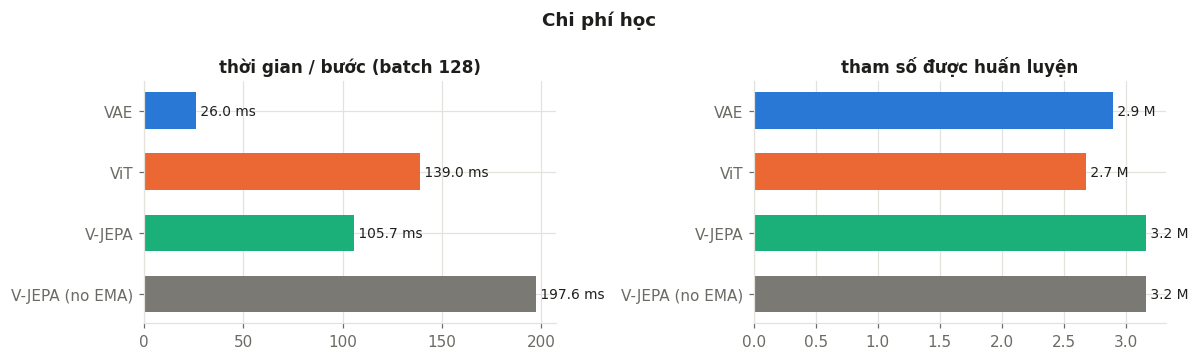

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.3))
ms = [logs[k]["ms_per_step"] for k in RUNS]
npar = [logs[k]["n_params"] / 1e6 for k in RUNS]
for ax, vals, t, unit in [(ax1, ms, "thời gian / bước (batch 128)", "ms"), (ax2, npar, "tham số được huấn luyện", "M")]:
    b = ax.barh(RUNS, vals, color=[MODEL_COLORS[k] for k in RUNS], height=0.6)
    for r_, v in zip(b, vals):
        ax.text(v, r_.get_y() + r_.get_height() / 2, f" {v:.1f} {unit}", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set_title(t); grid_style(ax)
fig.suptitle("Chi phí học", fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "04d_cost.png")

**Nhận xét**

- **VAE rẻ nhất** (26 ms/bước): CNN nhỏ, không có attention.
- **V-JEPA (106 ms) rẻ hơn ViT (139 ms)** dù có 3 mạng, vì context encoder chỉ xử lý **phần không bị che** (10–50% token), còn target encoder chạy không cần gradient.
- **no EMA đắt nhất** (198 ms): phải lan truyền ngược qua cả nhánh target.
- Số tham số gần như bằng nhau (2,7–3,2M), nên mọi khác biệt về biểu diễn **không** đến từ kích thước model.

## 5. Thí nghiệm collapse: vì sao V-JEPA cần EMA + stop-gradient

V-JEPA tự tạo mục tiêu cho chính nó. Nếu gradient được phép chảy vào nhánh target, model có lời giải "gian lận":
**cho mọi ảnh cùng một vector**, khi đó dự đoán luôn đúng và loss = 0. VAE (mục tiêu là pixel cố định) và ViT (mục tiêu là nhãn cố định) không có lối tắt này.

Hình dưới so sánh trực tiếp hai bản V-JEPA đã train ở mục 4: loss, cos giữa các ảnh, kNN, và **phương sai tuyệt đối** của biểu diễn (đã chuẩn hoá L2) theo từng hướng chính.
Bản collapse có phương sai nhỏ hơn nhiều bậc: các ảnh chỉ còn khác nhau ở phần nhiễu rất nhỏ.

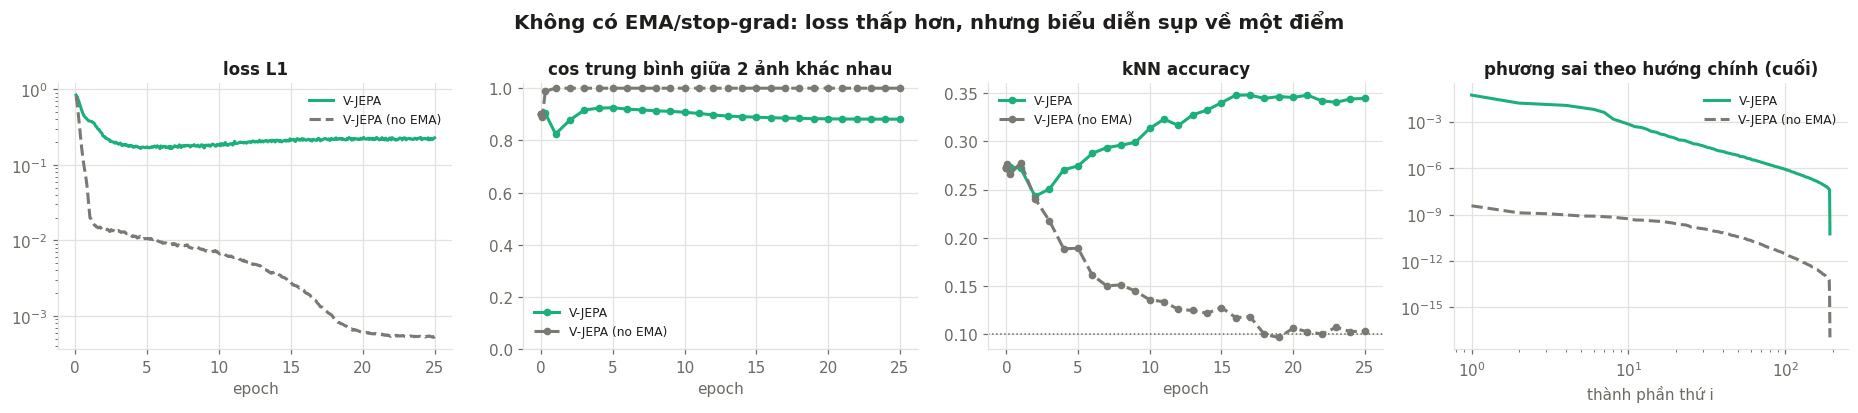

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
pair = ["V-JEPA", "V-JEPA (no EMA)"]
for k in pair:
    L = logs[k]; ls = "--" if "no EMA" in k else "-"
    axes[0].plot(ep(L, L["step"]), L["loss"], color=MODEL_COLORS[k], lw=2, ls=ls, label=k)
    axes[1].plot(ep(L, L["ev_step"]), L["mcos"], color=MODEL_COLORS[k], lw=2, ls=ls, marker="o", ms=4, label=k)
    axes[2].plot(ep(L, L["ev_step"]), L["knn"], color=MODEL_COLORS[k], lw=2, ls=ls, marker="o", ms=4, label=k)
    f = L["snaps"][L["ev_step"][-1]]
    f = f / np.linalg.norm(f, axis=1, keepdims=True)
    f = f - f.mean(0)
    ev_ = np.linalg.svd(f, compute_uv=False) ** 2 / len(f)
    axes[3].plot(np.arange(1, len(ev_) + 1), ev_, color=MODEL_COLORS[k], lw=2, ls=ls, label=k)
axes[0].set_title("loss L1"); axes[0].set_yscale("log")
axes[1].set_title("cos trung bình giữa 2 ảnh khác nhau"); axes[1].set_ylim(0, 1.02)
axes[2].set_title("kNN accuracy"); axes[2].axhline(0.1, color=INK_MUTED, ls=":", lw=1)
axes[3].set_title("phương sai theo hướng chính (cuối)"); axes[3].set_yscale("log"); axes[3].set_xscale("log")
axes[3].set_xlabel("thành phần thứ i")
for a in axes[:3]:
    a.set_xlabel("epoch")
for a in axes:
    grid_style(a); a.legend(fontsize=8)
fig.suptitle("Không có EMA/stop-grad: loss thấp hơn, nhưng biểu diễn sụp về một điểm", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "05_collapse.png")

**Nhận xét**

- Loss của bản no EMA xuống tới ~5·10⁻⁴, **thấp hơn ~400 lần** bản chuẩn (~0,22). Nhưng cos giữa hai ảnh bất kỳ lên **1,000** ngay trong epoch đầu, và kNN tụt dần về **0,10 = đoán bừa** (chạm đáy khoảng epoch 18).
- Ở bản chuẩn, loss **chạm đáy ở epoch 5 (~0,17) rồi tăng lên ~0,22** và giữ ở đó. Cùng lúc, cos giữa các ảnh giảm (0,92 → 0,88) và kNN tăng (0,24 → 0,35). Biểu diễn đa dạng hơn làm mục tiêu khó đoán hơn.
- Phương sai theo hướng chính của bản collapse nhỏ hơn bản chuẩn **khoảng 8 bậc độ lớn** (~10⁻⁹ so với ~10⁻¹): mọi ảnh gần như cùng một điểm.
- Bài học: với học tự giám sát trong không gian biểu diễn, **loss không phải thước đo chất lượng**. EMA + stop-gradient chính là thứ ngăn lời giải tầm thường.

## 6. Attention: ViT và V-JEPA nhìn vào đâu?

ViT và V-JEPA có **cùng kiến trúc**, nên khác biệt trong attention đến hoàn toàn từ mục tiêu học.
Ta chạy lại encoder, tự tính ma trận attention ở mỗi block (code gốc dùng `scaled_dot_product_attention` nên không trả ra trọng số).

- ViT: attention của token `[CLS]` (thứ quyết định nhãn) lên 64 patch, ở block cuối và gộp qua mọi block (attention rollout).
- V-JEPA: không có `[CLS]`; ta vẽ lượng attention mà **mỗi patch nhận được** từ mọi patch khác (block cuối và rollout).

Lưu ý khi đọc: rollout của V-JEPA thường dồn vào vài patch ở **góc / nền**. Đó là các token "hút" attention (giống *attention sink* /
*register token* được báo cáo ở các ViT tự giám sát lớn), không có nghĩa là model coi góc ảnh là quan trọng.
Không có token tổng hợp như `[CLS]`, V-JEPA tự dùng vài patch ít thông tin làm chỗ "gom" thông tin toàn cục.

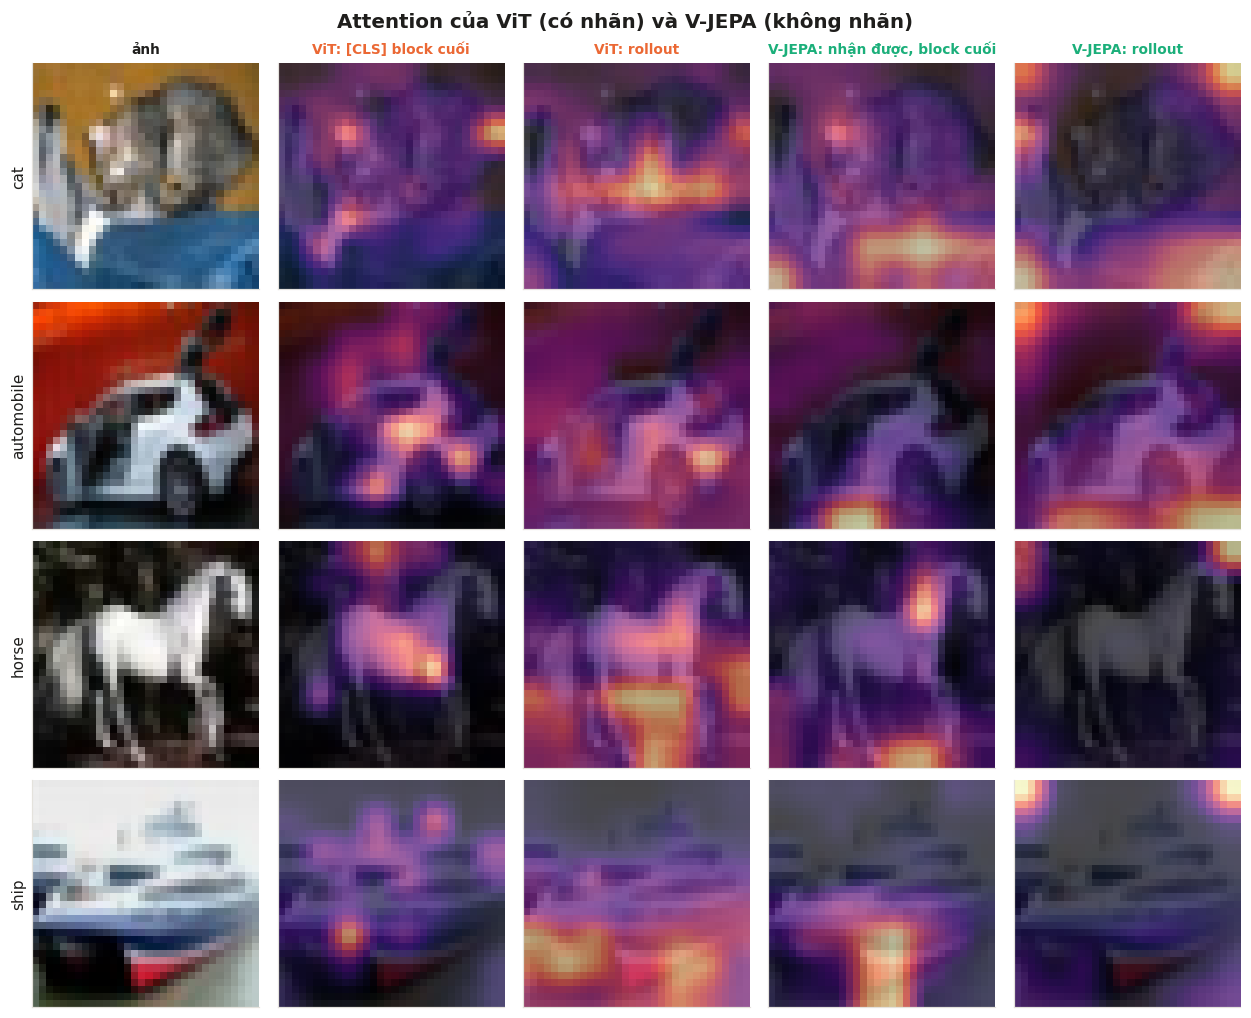

In [ ]:
@torch.no_grad()
def vit_forward_attn(enc, x):
    """Giống hệt ViTEncoder.forward, nhưng trả thêm output từng block và ma trận attention (B, heads, N, N)."""
    h = enc.patch_embed(x) + enc.pos_embed
    if enc.cls_token is not None:
        h = torch.cat([enc.cls_token.expand(x.size(0), -1, -1), h], dim=1)
    hs, attns = [], []
    for blk in enc.blocks:
        a = blk.attn
        y = blk.norm1(h)
        B, N, D = y.shape
        q, k, v = a.qkv(y).view(B, N, 3, a.heads, D // a.heads).permute(2, 0, 3, 1, 4)
        w = ((q @ k.transpose(-2, -1)) / math.sqrt(D // a.heads)).softmax(-1)
        attns.append(w)
        h = h + a.proj((w @ v).transpose(1, 2).reshape(B, N, D))
        h = h + blk.mlp(blk.norm2(h))
        hs.append(h)
    return enc.norm(h), hs, attns


# kiểm tra: kết quả khớp với forward gốc
_o, _, _ = vit_forward_attn(vit.encoder, xs)
assert torch.allclose(_o, vit.encoder(xs), atol=1e-4)
_o, _, _ = vit_forward_attn(vj_tgt, xs)
assert torch.allclose(_o, vj_tgt(xs), atol=1e-4)


def rollout(attns, has_cls):
    A = None
    for w in attns:
        a = w.mean(1)
        a = a + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        A = a if A is None else a @ A
    return A[:, 0, 1:] if has_cls else A.mean(1)


def norm01(m):
    m = m - m.amin(-1, keepdim=True)
    return m / (m.amax(-1, keepdim=True) + 1e-12)


_, _, att_vit = vit_forward_attn(vit.encoder, xs)
_, _, att_vj = vit_forward_attn(vj_tgt, xs)
maps = {
    "ViT: [CLS] block cuối": att_vit[-1].mean(1)[:, 0, 1:],
    "ViT: rollout": rollout(att_vit, True),
    "V-JEPA: nhận được, block cuối": att_vj[-1].mean(1).mean(1),
    "V-JEPA: rollout": rollout(att_vj, False),
}
fig, axes = plt.subplots(N_SHOW, 5, figsize=(11.5, 2.35 * N_SHOW))
for i in range(N_SHOW):
    axes[i, 0].imshow(img_np(xs[i])); axes[i, 0].set_ylabel(CLASSES[ys[i]], color=INK)
    for j, (t, m) in enumerate(maps.items()):
        mm = norm01(m[i]).reshape(1, 1, GRID_N, GRID_N)
        up = F.interpolate(mm, size=32, mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
        axes[i, j + 1].imshow(img_np(xs[i]) * 0.3 + 0.7 * plt.get_cmap(HEAT)(up)[..., :3])
        if i == 0:
            axes[i, j + 1].set_title(t, fontsize=9, color=MODEL_COLORS["ViT" if t.startswith("ViT") else "V-JEPA"])
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_title("ảnh", fontsize=9)
fig.suptitle("Attention của ViT (có nhãn) và V-JEPA (không nhãn)", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "06_attention_maps.png")

**Nhận xét**

- **ViT `[CLS]` block cuối** chú ý vào **thân vật** (thân xe, thân ngựa, đầu mèo). Rollout gộp mọi block thì lan rộng hơn nhưng vẫn quanh vật.
- **V-JEPA block cuối** dồn attention vào vài patch ở **mép dưới / nền** của ảnh, và rollout của nó dồn vào **các góc**. Đây là các token "sink" giải thích ở trên, không phải vùng quan trọng về ngữ nghĩa.
- V-JEPA không có token tổng hợp, nên không có một "điểm nhìn" duy nhất như `[CLS]`. Muốn biết V-JEPA dùng vùng nào, hình che ảnh ở mục 9.1 đáng tin hơn hình attention.

### 6.1 Nhìn gần hay nhìn xa? (mean attention distance)

Với mỗi head ở mỗi block: khoảng cách trung bình (pixel) giữa patch truy vấn và patch nó chú ý, có trọng số theo attention
(như hình 7 của bài báo ViT). Giá trị nhỏ = head "cục bộ" (giống convolution), lớn = head "toàn cục".
Đường xám = khoảng cách trung bình nếu attention đều tuyệt đối.

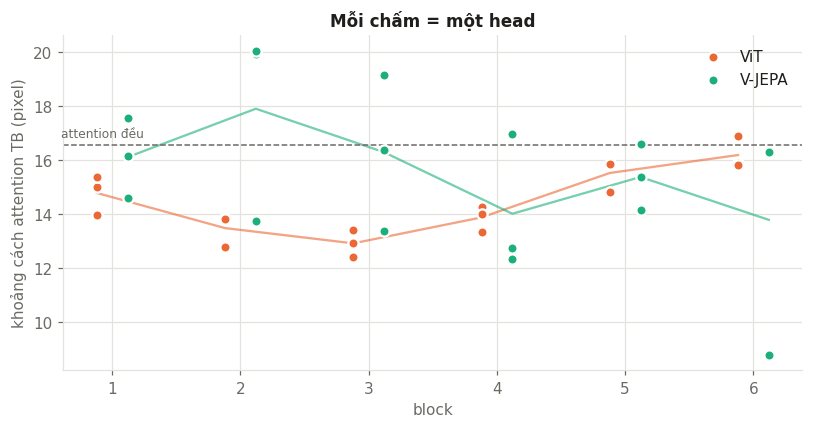

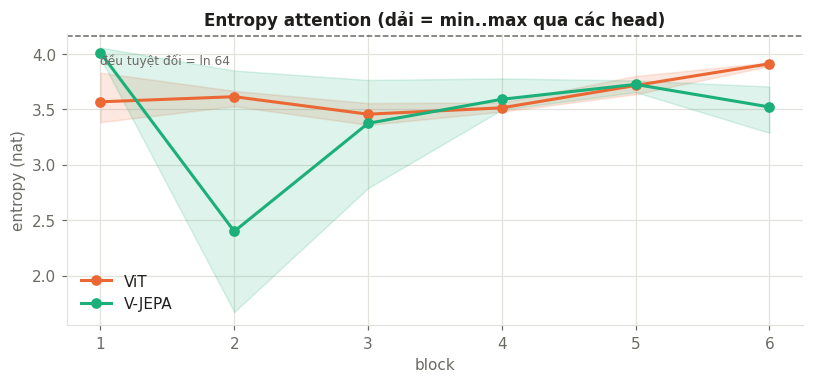

In [ ]:
ys_, xs_ = np.divmod(np.arange(GRID_N * GRID_N), GRID_N)
P = 32 // GRID_N
D_pix = torch.tensor(np.sqrt((ys_[:, None] - ys_[None]) ** 2 + (xs_[:, None] - xs_[None]) ** 2) * P,
                     dtype=torch.float32, device=device)


@torch.no_grad()
def mean_attn_distance(enc, X, has_cls, bs=250):
    tot = None
    for i in range(0, len(X), bs):
        _, _, att = vit_forward_attn(enc, X[i:i + bs].to(device))
        d = []
        for w in att:
            if has_cls:
                w = w[:, :, 1:, 1:]
                w = w / w.sum(-1, keepdim=True)
            d.append((w * D_pix).sum(-1).mean(-1).sum(0))       # (heads,)
        d = torch.stack(d)
        tot = d if tot is None else tot + d
    return (tot / len(X)).cpu().numpy()                         # (depth, heads)


mad = {"ViT": mean_attn_distance(vit.encoder, X_test[:1000], True),
       "V-JEPA": mean_attn_distance(vj_tgt, X_test[:1000], False)}
uniform = float(D_pix.mean())
fig, ax = plt.subplots(figsize=(7.5, 4))
for off, n in [(-0.12, "ViT"), (0.12, "V-JEPA")]:
    m = mad[n]
    for l in range(m.shape[0]):
        ax.scatter(np.full(m.shape[1], l + 1 + off), m[l], color=MODEL_COLORS[n], s=45,
                   edgecolors="white", linewidths=1.5, label=n if l == 0 else None, zorder=3)
    ax.plot(np.arange(1, m.shape[0] + 1) + off, m.mean(1), color=MODEL_COLORS[n], lw=1.5, alpha=0.6)
ax.axhline(uniform, color=INK_MUTED, ls="--", lw=1)
ax.text(0.6, uniform + 0.3, "attention đều", fontsize=8, color=INK_MUTED)
ax.set_xlabel("block"); ax.set_ylabel("khoảng cách attention TB (pixel)")
ax.set_xticks(range(1, m.shape[0] + 1)); ax.legend()
ax.set_title("Mỗi chấm = một head"); grid_style(ax)
fig.tight_layout()
show(fig, "06b_attention_distance.png")

# entropy attention: head tập trung (thấp) hay dàn trải (cao)
@torch.no_grad()
def attn_entropy(enc, X, has_cls):
    _, _, att = vit_forward_attn(enc, X.to(device))
    out = []
    for w in att:
        if has_cls:
            w = w[:, :, 1:, 1:]; w = w / w.sum(-1, keepdim=True)
        out.append((-(w * (w + 1e-12).log()).sum(-1)).mean((0, 2)).cpu().numpy())
    return np.stack(out)


ent = {"ViT": attn_entropy(vit.encoder, X_test[:500], True), "V-JEPA": attn_entropy(vj_tgt, X_test[:500], False)}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for n in ["ViT", "V-JEPA"]:
    e = ent[n]
    ax.plot(range(1, len(e) + 1), e.mean(1), color=MODEL_COLORS[n], lw=2, marker="o", label=n)
    ax.fill_between(range(1, len(e) + 1), e.min(1), e.max(1), color=MODEL_COLORS[n], alpha=0.15)
ax.axhline(math.log(GRID_N * GRID_N), color=INK_MUTED, ls="--", lw=1)
ax.text(1, math.log(64) - 0.25, "đều tuyệt đối = ln 64", fontsize=8, color=INK_MUTED)
ax.set_xlabel("block"); ax.set_ylabel("entropy (nat)"); ax.legend()
ax.set_title("Entropy attention (dải = min..max qua các head)"); grid_style(ax)
fig.tight_layout()
show(fig, "06c_attention_entropy.png")

**Nhận xét**

- **Hình trên (khoảng cách)**: ViT nhìn **gần hơn ở các block giữa** (~13 px) rồi xa dần ở cuối (~16 px). V-JEPA có head **đa dạng hơn hẳn**: block 2 có head nhìn rất xa (~20 px), block 6 có một head rất cục bộ (~9 px).
- **Hình dưới (entropy)**: ViT ổn định quanh 3,4–3,9 nat ở mọi block. V-JEPA có **block 2 tập trung bất thường** (entropy xuống ~1,7–2,4), khớp với việc vài token "sink" hút phần lớn attention từ sớm.

### 6.2 VAE không có attention: feature map của encoder CNN

VAE "nhìn" bằng convolution: mỗi tầng chỉ thấy một vùng cục bộ, và vùng này lớn dần. Hình dưới là độ lớn kích hoạt trung bình theo kênh.

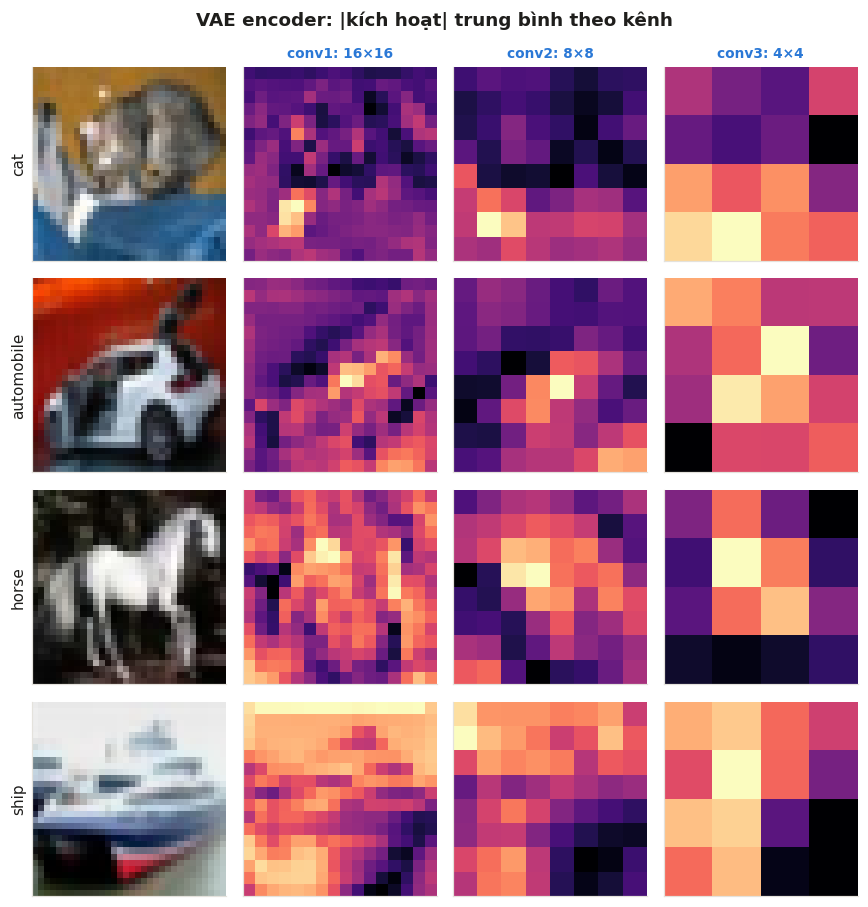

In [ ]:
with torch.no_grad():
    acts, h = [], xs
    for layer in list(vae.encoder)[:3]:
        h = layer(h); acts.append(h.abs().mean(1))
fig, axes = plt.subplots(N_SHOW, 4, figsize=(8, 2.1 * N_SHOW))
for i in range(N_SHOW):
    axes[i, 0].imshow(img_np(xs[i])); axes[i, 0].set_ylabel(CLASSES[ys[i]], color=INK)
    for j, a in enumerate(acts):
        axes[i, j + 1].imshow(a[i].cpu().numpy(), cmap=HEAT, interpolation="nearest")
        if i == 0:
            axes[i, j + 1].set_title(f"conv{j + 1}: {a.shape[-1]}×{a.shape[-1]}", fontsize=9, color=MODEL_COLORS["VAE"])
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("VAE encoder: |kích hoạt| trung bình theo kênh", fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "06d_vae_feature_maps.png")

**Nhận xét**

- **conv1 (16×16)** phản ứng với **biên và kết cấu** cục bộ (mép tấm vải, viền xe).
- **conv3 (4×4)** chỉ còn bản đồ thô "vùng nào sáng / có vật". Ở thân ngựa và thân xe kích hoạt mạnh, nhưng ở ảnh tàu thì nền sáng cũng mạnh không kém.
- Trước tầng fully-connected cuối, VAE **không có tương tác toàn cục** nào. Mọi "hiểu biết" về cả ảnh chỉ hình thành ở `mu`, khớp với probe từng tầng ở mục 8 (conv1–conv3 kém hơn cả pixel).

## 7. Cấu trúc không gian của patch token (PCA → RGB)

Mỗi model có một lưới 8×8 đặc trưng cục bộ: VAE = output conv2 (8×8×128), ViT và V-JEPA = 64 patch token ở block cuối.
Ta chiếu 3 thành phần chính (fit trên 1 000 ảnh, riêng từng model) thành màu RGB. Patch có màu giống nhau = model coi là giống nhau.
- Hàng thứ nhất của mỗi model: PCA trực tiếp. Với V-JEPA, màu chuyển đều từ trên xuống dưới ở mọi ảnh: các **hướng chính đầu tiên**
  chủ yếu mã hoá **vị trí** (predictor cần biết "token ở ô này thường trông thế nào", và mục tiêu của nó chính là các token này).
- Hàng thứ hai ("− TB vị trí"): trừ token trung bình tại mỗi ô, chỉ còn phần phụ thuộc **nội dung ảnh**.
- VAE (conv, không có positional embedding) tô theo màu / độ sáng / biên vật thể. ViT: token patch không được loss dùng trực tiếp
  (chỉ `[CLS]` đi vào head), nên ít bị ràng buộc hơn.

Biểu đồ cột sau hình đo phần phương sai **tổng** của token giải thích bởi vị trí patch. Vị trí chỉ chiếm một phần nhỏ tổng phương sai,
nhưng với V-JEPA phần đó lại nằm gọn trong vài hướng mạnh nhất, nên PCA(3) bị nó chi phối.

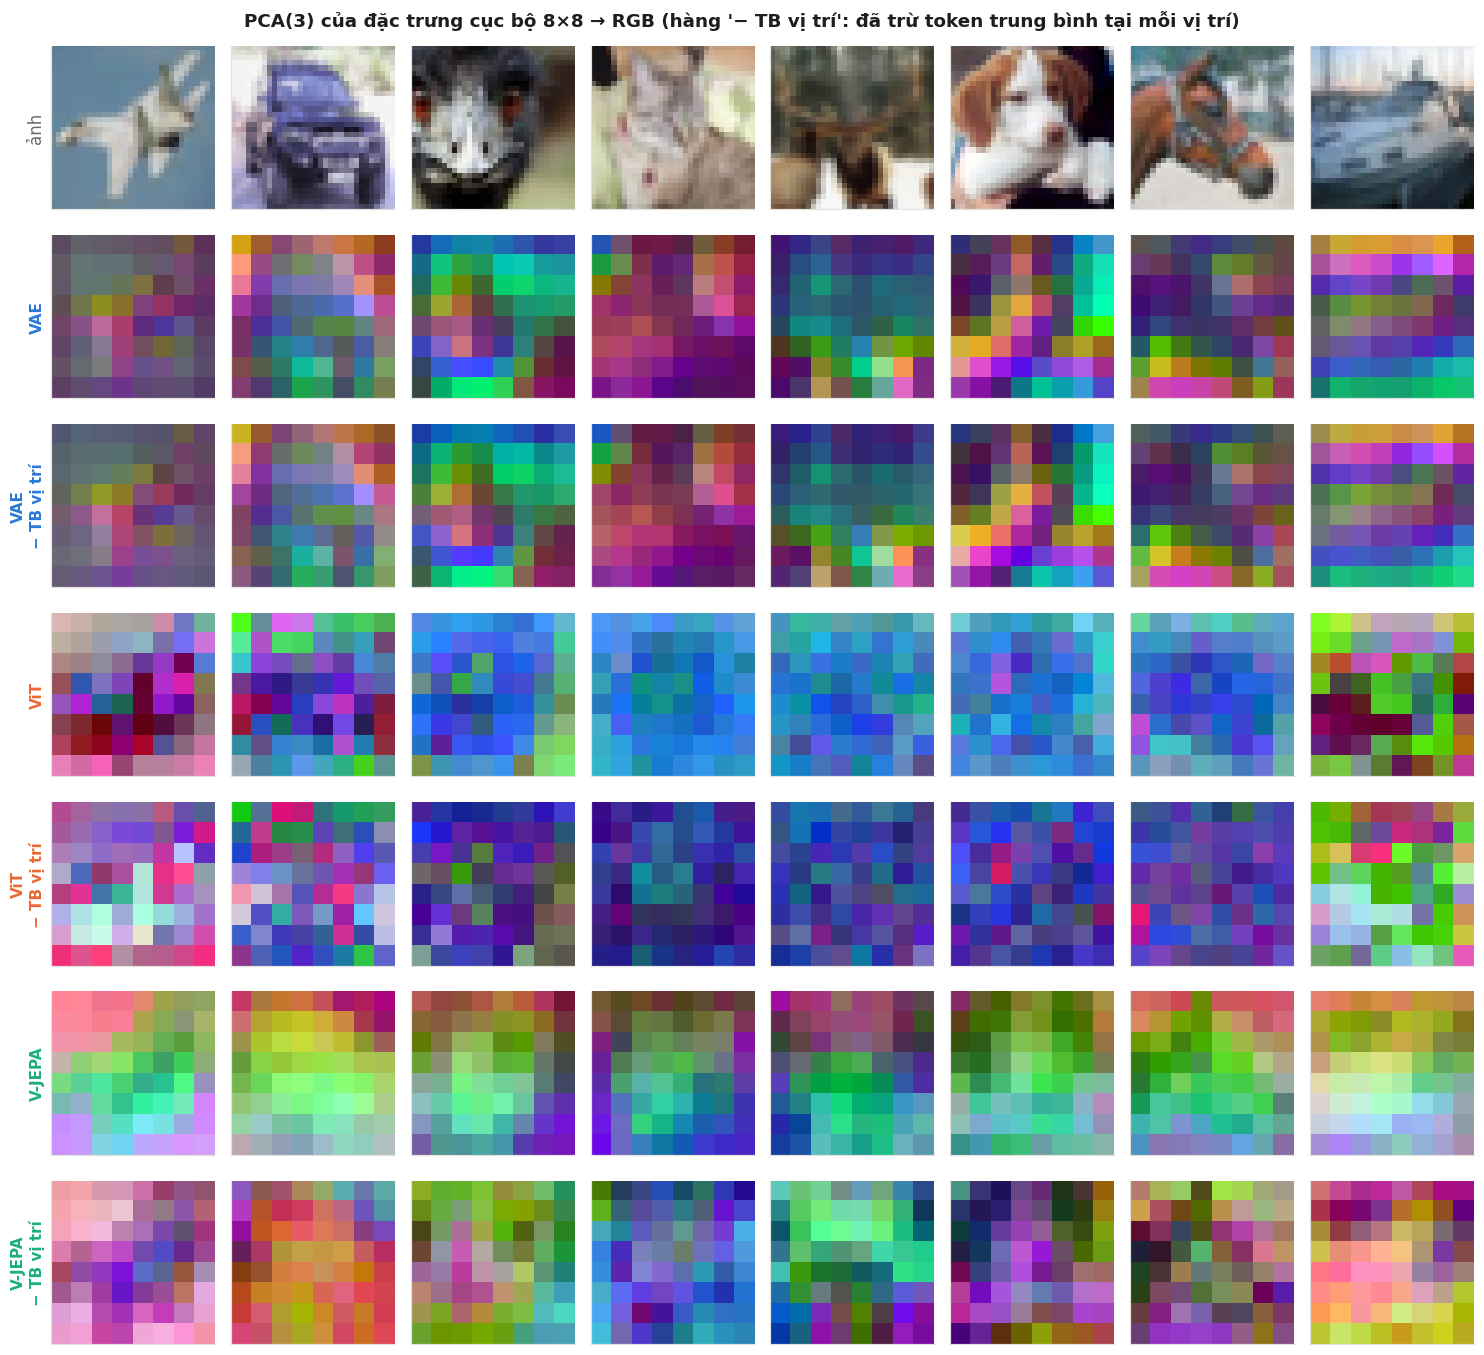

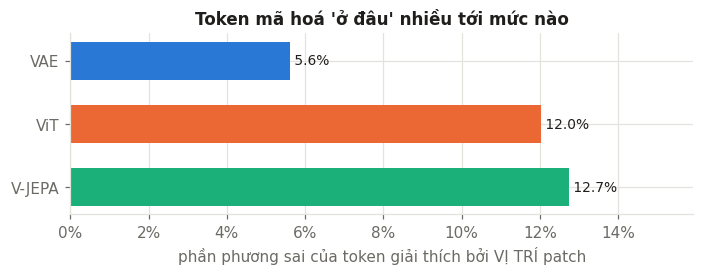

In [ ]:
@torch.no_grad()
def patch_tokens(name, X):
    X = X.to(device)
    if name == "VAE":
        h = vae.encoder[1](vae.encoder[0](X))                    # (B,128,8,8)
        return h.flatten(2).transpose(1, 2)
    if name == "ViT":
        return vit.encoder(X)[:, 1:]
    return vj_tgt(X)


def pca_rgb(t_fit, t_show):
    pca = PCA(3).fit(t_fit)
    lo_, hi_ = np.percentile(pca.transform(t_fit), [1, 99], axis=0)
    return np.clip((pca.transform(t_show) - lo_) / (hi_ - lo_), 0, 1)


fit_X = X_test[1000:2000]
n_img = 8
show_X = X_test[torch.tensor([int((Y_test == c).nonzero()[1]) for c in [0, 1, 2, 3, 4, 5, 7, 8]])]
pos_share = {}
fig, axes = plt.subplots(7, n_img, figsize=(1.7 * n_img, 12.6))
for j in range(n_img):
    axes[0, j].imshow(img_np(show_X[j]))
for i, n in enumerate(NAMES):
    t = torch.cat([patch_tokens(n, fit_X[k:k + 250]) for k in range(0, len(fit_X), 250)]).cpu()   # (B, 64, D)
    ts = patch_tokens(n, show_X).cpu()
    pos_mean = t.mean(0, keepdim=True)                                       # token trung bình tại mỗi vị trí
    pos_share[n] = float(((pos_mean - t.mean((0, 1))) ** 2).sum(-1).mean() / ((t - t.mean((0, 1))) ** 2).sum(-1).mean())
    for row, (tf, tsh, lab) in enumerate([(t, ts, n), (t - pos_mean, ts - pos_mean, f"{n}\n− TB vị trí")]):
        z = pca_rgb(tf.reshape(-1, t.size(-1)).numpy(), tsh.reshape(-1, t.size(-1)).numpy())
        z = z.reshape(n_img, GRID_N, GRID_N, 3)
        for j in range(n_img):
            axes[1 + 2 * i + row, j].imshow(z[j], interpolation="nearest")
        axes[1 + 2 * i + row, 0].set_ylabel(lab, color=MODEL_COLORS[n], fontweight="bold", fontsize=10)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("ảnh", fontsize=11)
fig.suptitle("PCA(3) của đặc trưng cục bộ 8×8 → RGB (hàng '− TB vị trí': đã trừ token trung bình tại mỗi vị trí)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "07_patch_pca.png")

fig, ax = plt.subplots(figsize=(6.5, 2.6))
b = ax.barh(NAMES, [pos_share[n] for n in NAMES], color=[MODEL_COLORS[n] for n in NAMES], height=0.6)
for r_, n in zip(b, NAMES):
    ax.text(pos_share[n], r_.get_y() + r_.get_height() / 2, f" {pos_share[n]:.1%}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, max(pos_share.values()) * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("phần phương sai của token giải thích bởi VỊ TRÍ patch")
ax.set_title("Token mã hoá 'ở đâu' nhiều tới mức nào"); grid_style(ax)
fig.tight_layout()
show(fig, "07b_position_share.png")

**Nhận xét**

- **Sau khi trừ vị trí** (hàng thứ hai của mỗi model), token V-JEPA bắt đầu tách **vật và nền** (đầu chim, thân ngựa, thân xe có màu khác nền). Token ViT lốm đốm hơn, ít vùng liền mạch.
- Hàng của VAE gần như **không đổi** khi trừ vị trí: conv không có positional embedding, và vị trí chỉ chiếm 5,6% phương sai.
- ViT và V-JEPA mã hoá vị trí ở mức gần nhau (12–13% phương sai). Khác biệt là ở V-JEPA phần vị trí **chiếm các hướng mạnh nhất**, nên lấn át PCA(3).

## 8. Ngữ nghĩa xuất hiện ở tầng nào? (probe từng tầng + CKA)

Lấy đặc trưng ở **từng tầng** (pool trung bình qua không gian / token), chạy kNN. Đường ngang = kNN trên **pixel thô**.
- VAE: conv1 → conv3 → `mu`. ViT: block 1..6, cả `[CLS]` và trung bình patch. V-JEPA: block 1..6 (target encoder).

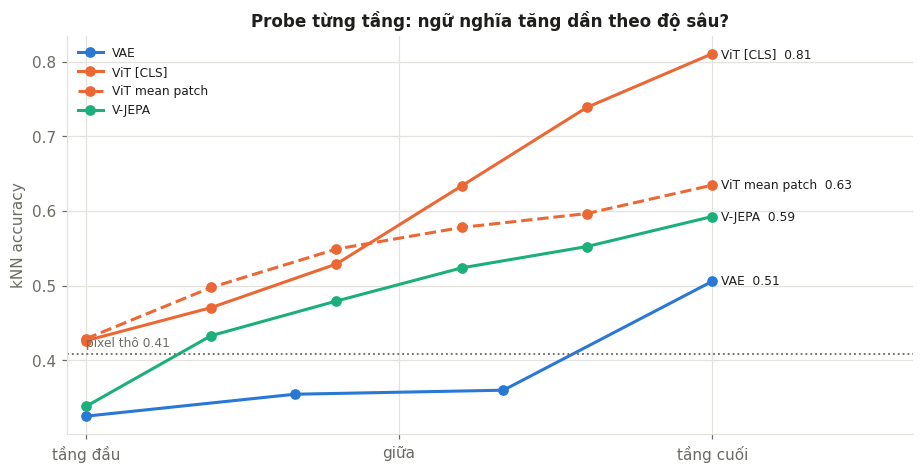

In [ ]:
@torch.no_grad()
def layer_feats(name, X, bs=500):
    out = None
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(device)
        if name == "VAE":
            fs, h = [], x
            for layer in list(vae.encoder)[:3]:
                h = layer(h); fs.append(h.mean((2, 3)))
            fs.append(vae.encode(x)[0])
        elif name == "ViT":
            _, hs, _ = vit_forward_attn(vit.encoder, x)
            fs = [h[:, 0] for h in hs[:-1]] + [vit.features(x)] + [h[:, 1:].mean(1) for h in hs]
        else:
            _, hs, _ = vit_forward_attn(vj_tgt, x)
            fs = [h.mean(1) for h in hs[:-1]] + [vj_tgt(x).mean(1)]
        fs = [f.float().cpu() for f in fs]
        out = fs if out is None else [torch.cat([a, b]) for a, b in zip(out, fs)]
    return out


LF_tr = {n: layer_feats(n, Xp_tr) for n in NAMES}
LF_te = {n: layer_feats(n, Xp_te) for n in NAMES}
pix_knn = knn(Xp_tr.flatten(1), Yp_tr, Xp_te.flatten(1), Yp_te)
D = vit.encoder.blocks.__len__()
series = {
    "VAE": (["conv1", "conv2", "conv3", "mu"], list(range(4))),
    "ViT [CLS]": ([f"B{i + 1}" for i in range(D)], list(range(D))),
    "ViT mean patch": ([f"B{i + 1}" for i in range(D)], list(range(D, 2 * D))),
    "V-JEPA": ([f"B{i + 1}" for i in range(D)], list(range(D))),
}
layer_knn = {}
for s, (labels_, idxs) in series.items():
    n = s.split()[0]
    layer_knn[s] = [knn(LF_tr[n][i], Yp_tr, LF_te[n][i], Yp_te) for i in idxs]

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for s, accs in layer_knn.items():
    n = s.split()[0]
    xr = np.linspace(0, 1, len(accs))
    ax.plot(xr, accs, color=MODEL_COLORS[n], lw=2, marker="o", ls="--" if "mean patch" in s else "-", label=s)
    ax.annotate(f"{s}  {accs[-1]:.2f}", (1, accs[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8)
ax.axhline(pix_knn, color=INK_MUTED, ls=":", lw=1.2)
ax.text(0, pix_knn + 0.01, f"pixel thô {pix_knn:.2f}", fontsize=8, color=INK_MUTED)
ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["tầng đầu", "giữa", "tầng cuối"])
ax.set_xlim(-0.03, 1.32); ax.set_ylabel("kNN accuracy"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Probe từng tầng: ngữ nghĩa tăng dần theo độ sâu?"); grid_style(ax)
fig.tight_layout()
show(fig, "08_layer_probe.png")

**Nhận xét**

- **ViT `[CLS]`**: tăng **vọt ở hai block cuối** (0,61 → 0,80). Ngữ nghĩa hình thành muộn, ngay sát lớp phân loại, đúng nơi gradient nhãn mạnh nhất.
- **ViT mean patch** chỉ đạt 0,61: thông tin lớp được gom **vào `[CLS]`**, không rải đều trên patch token.
- **V-JEPA** tăng **đều** qua các block (0,30 → 0,55), không có bước nhảy: ngữ nghĩa tích luỹ dần, không bị một head kéo về cuối.
- **VAE**: conv1–conv3 còn **thấp hơn pixel thô** (~0,30 so với 0,34), chỉ tới `mu` mới nhảy lên 0,45. Encoder CNN của VAE không xây dần ngữ nghĩa; nó nén ảnh để decoder vẽ lại.

### 8.1 CKA: hai biểu diễn giống nhau tới đâu?

Linear CKA ∈ [0, 1] đo hai tập đặc trưng (trên cùng ảnh) có cùng "hình học" hay không, bất kể số chiều.
Trái: từng block của ViT vs từng block của V-JEPA (cùng kiến trúc, khác mục tiêu). Phải: giữa ba không gian cuối và pixel thô.

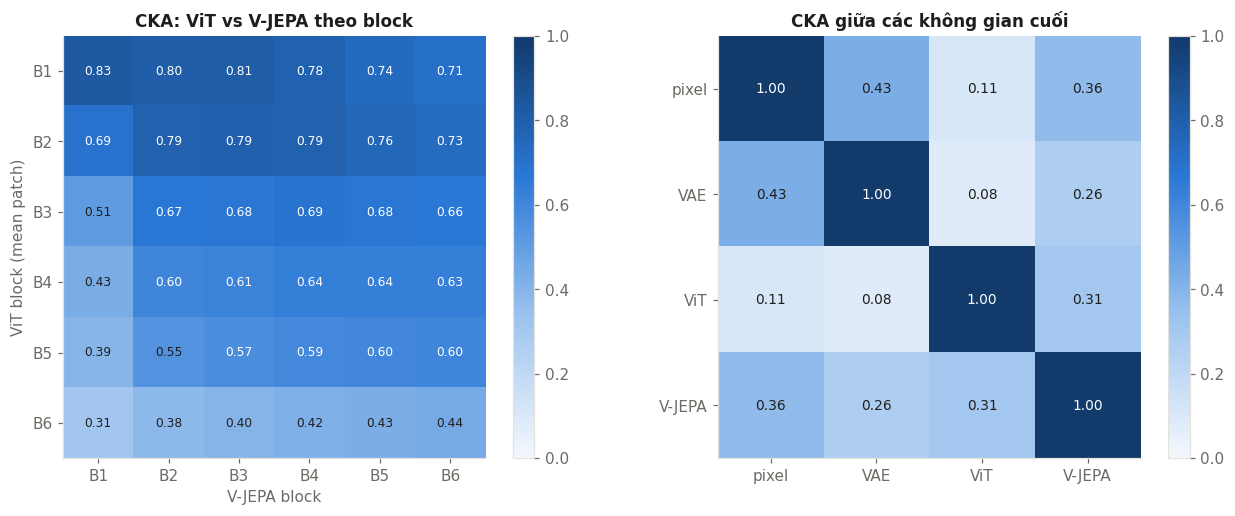

In [ ]:
def linear_cka(a, b):
    a = a.double() - a.double().mean(0); b = b.double() - b.double().mean(0)
    return float((a.T @ b).norm() ** 2 / ((a.T @ a).norm() * (b.T @ b).norm()))


Xc = LF_te
vit_mean = Xc["ViT"][D:2 * D]
vj_layers = Xc["V-JEPA"]
M = np.array([[linear_cka(vit_mean[i], vj_layers[j]) for j in range(D)] for i in range(D)])
final = {"pixel": Xp_te.flatten(1), "VAE": F_te["VAE"], "ViT": F_te["ViT"], "V-JEPA": F_te["V-JEPA"]}
keys = list(final)
C = np.array([[linear_cka(final[a], final[b]) for b in keys] for a in keys])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
im = ax1.imshow(M, cmap=SEQ, vmin=0, vmax=1)
for i in range(D):
    for j in range(D):
        ax1.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.55 else INK)
ax1.set_xticks(range(D)); ax1.set_xticklabels([f"B{j + 1}" for j in range(D)])
ax1.set_yticks(range(D)); ax1.set_yticklabels([f"B{i + 1}" for i in range(D)])
ax1.set_xlabel("V-JEPA block"); ax1.set_ylabel("ViT block (mean patch)")
ax1.set_title("CKA: ViT vs V-JEPA theo block")
fig.colorbar(im, ax=ax1, fraction=0.046)
im = ax2.imshow(C, cmap=SEQ, vmin=0, vmax=1)
for i in range(len(keys)):
    for j in range(len(keys)):
        ax2.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if C[i, j] > 0.55 else INK)
ax2.set_xticks(range(len(keys))); ax2.set_xticklabels(keys); ax2.set_yticks(range(len(keys))); ax2.set_yticklabels(keys)
ax2.set_title("CKA giữa các không gian cuối")
fig.colorbar(im, ax=ax2, fraction=0.046)
fig.tight_layout()
show(fig, "08b_cka.png")

**Nhận xét**

- **Trái**: ở các **block đầu**, ViT và V-JEPA rất giống nhau (CKA ~0,8): cùng kiến trúc, nên đặc trưng cấp thấp gần như giống nhau bất kể mục tiêu. Càng về cuối càng khác (0,44 ở B6 vs B6): **mục tiêu học tác động mạnh nhất lên các tầng sâu**.
- **Phải**: `S_vae` gần pixel nhất (0,43), `S_vit` xa pixel nhất (0,11), `S_vjepa` ở giữa (0,36).
- Ba không gian cuối ít giống nhau (0,08–0,31). Gần nhau nhất là ViT–V-JEPA (0,31); VAE–ViT gần như không liên quan (0,08).

## 9. Bất biến và nhạy cảm: model "bỏ qua" biến đổi nào?

Áp một biến đổi T lên 1 000 ảnh test và đo biểu diễn còn giống bản gốc bao nhiêu:

$$\text{invariance} = \frac{\cos(f(x), f(Tx)) - \overline{\cos}_{\text{ảnh ngẫu nhiên}}}{1 - \overline{\cos}_{\text{ảnh ngẫu nhiên}}}$$

(cos tính sau khi trừ trung bình). 1 = biểu diễn không đổi, 0 = khác như hai ảnh ngẫu nhiên.
Mô hình học để **giữ pixel** (VAE) phải nhạy với mọi biến đổi màu/vị trí; mô hình học **nhãn** (ViT) được khuyến khích bỏ qua mọi thứ không đổi lớp.

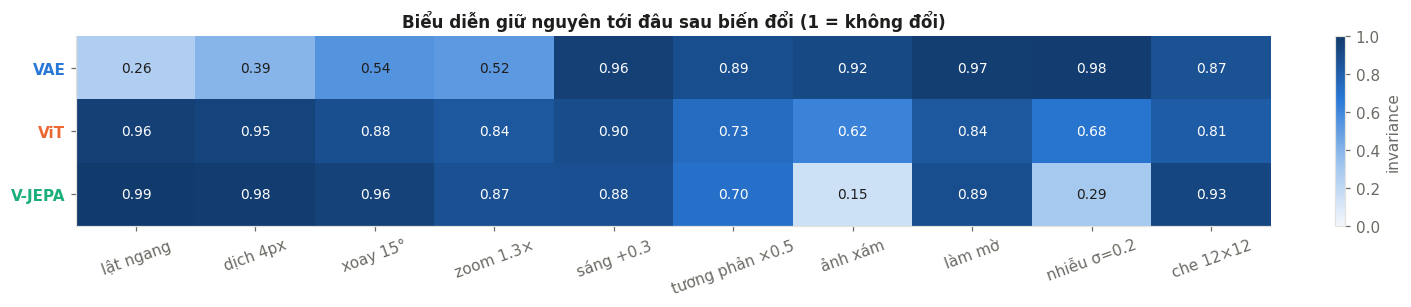

In [ ]:
def gauss_blur(x, s=1.0):
    k = torch.arange(-2, 3, device=x.device, dtype=torch.float32)
    k = torch.exp(-k ** 2 / (2 * s ** 2)); k = k / k.sum()
    w = (k[:, None] * k[None])[None, None].repeat(3, 1, 1, 1)
    return F.conv2d(F.pad(x, (2, 2, 2, 2), mode="reflect"), w, groups=3)


def affine(x, angle=0.0, tx=0.0, scale=1.0):
    B = x.size(0); a = math.radians(angle)
    theta = torch.tensor([[math.cos(a) / scale, -math.sin(a) / scale, tx], [math.sin(a) / scale, math.cos(a) / scale, 0.0]],
                         device=x.device).repeat(B, 1, 1)
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="reflection", align_corners=False)


def occlude(x, size=12, seed=0):
    g_ = torch.Generator().manual_seed(seed)
    x = x.clone()
    for i in range(len(x)):
        t, l = torch.randint(0, 33 - size, (2,), generator=g_).tolist()
        x[i, :, t:t + size, l:l + size] = 0
    return x


gray = lambda x: (0.299 * x[:, :1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:]).expand(-1, 3, -1, -1)
TRANSFORMS = {
    "lật ngang": lambda x: x.flip(3),
    "dịch 4px": lambda x: affine(x, tx=8 / 32),
    "xoay 15°": lambda x: affine(x, angle=15),
    "zoom 1.3×": lambda x: affine(x, scale=1.3),
    "sáng +0.3": lambda x: (x + 0.3).clamp(-1, 1),
    "tương phản ×0.5": lambda x: x * 0.5,
    "ảnh xám": gray,
    "làm mờ": gauss_blur,
    "nhiễu σ=0.2": lambda x: (x + 0.2 * torch.randn_like(x)).clamp(-1, 1),
    "che 12×12": occlude,
}
X_inv = X_test[2000:3000]


def cos_c(a, b, n):
    return F.cosine_similarity(a - mean_tr[n], b - mean_tr[n], dim=1)


torch.manual_seed(SEED)
f0 = {n: feats_of(FEAT[n], X_inv) for n in NAMES}
rand_cos = {n: float(cos_c(f0[n], f0[n].roll(1, 0), n).mean()) for n in NAMES}
INV = np.zeros((len(NAMES), len(TRANSFORMS)))
for j, (tn, T) in enumerate(TRANSFORMS.items()):
    XT = torch.cat([T(X_inv[i:i + 500].to(device)).cpu() for i in range(0, len(X_inv), 500)])
    for i, n in enumerate(NAMES):
        c = float(cos_c(f0[n], feats_of(FEAT[n], XT), n).mean())
        INV[i, j] = (c - rand_cos[n]) / (1 - rand_cos[n])

fig, ax = plt.subplots(figsize=(13, 2.9))
im = ax.imshow(INV, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(len(NAMES)):
    for j in range(len(TRANSFORMS)):
        ax.text(j, i, f"{INV[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if INV[i, j] > 0.55 else INK)
ax.set_xticks(range(len(TRANSFORMS))); ax.set_xticklabels(list(TRANSFORMS), rotation=20)
ax.set_yticks(range(3)); ax.set_yticklabels(NAMES)
for t, n in zip(ax.get_yticklabels(), NAMES):
    t.set_color(MODEL_COLORS[n]); t.set_fontweight("bold")
fig.colorbar(im, ax=ax, fraction=0.02, label="invariance")
ax.set_title("Biểu diễn giữ nguyên tới đâu sau biến đổi (1 = không đổi)")
fig.tight_layout()
show(fig, "09_invariance.png")

**Nhận xét**

- **VAE**: rất nhạy với **biến đổi hình học** (lật 0,26, dịch 0,39, xoay 0,54), nhưng gần như bất biến với **độ sáng, nhiễu, làm mờ** (0,92–0,98). Lý do: vẽ lại ảnh lật thì cần vector khác, còn chi tiết tần số cao (nhiễu) thì VAE vốn đã bỏ.
- **V-JEPA**: bất biến hình học **tốt nhất** (lật 0,99, dịch 0,98, xoay 0,96), nhưng **nhạy nhất với ảnh xám (0,15) và nhiễu (0,30)**. Màu và kết cấu là manh mối quan trọng để nó đoán token bị che.
- **ViT**: bất biến khá đều với mọi biến đổi (0,62–0,96). Nhãn không đổi dưới các biến đổi này, nên CE dạy nó bỏ qua tất cả một cách tương đối.

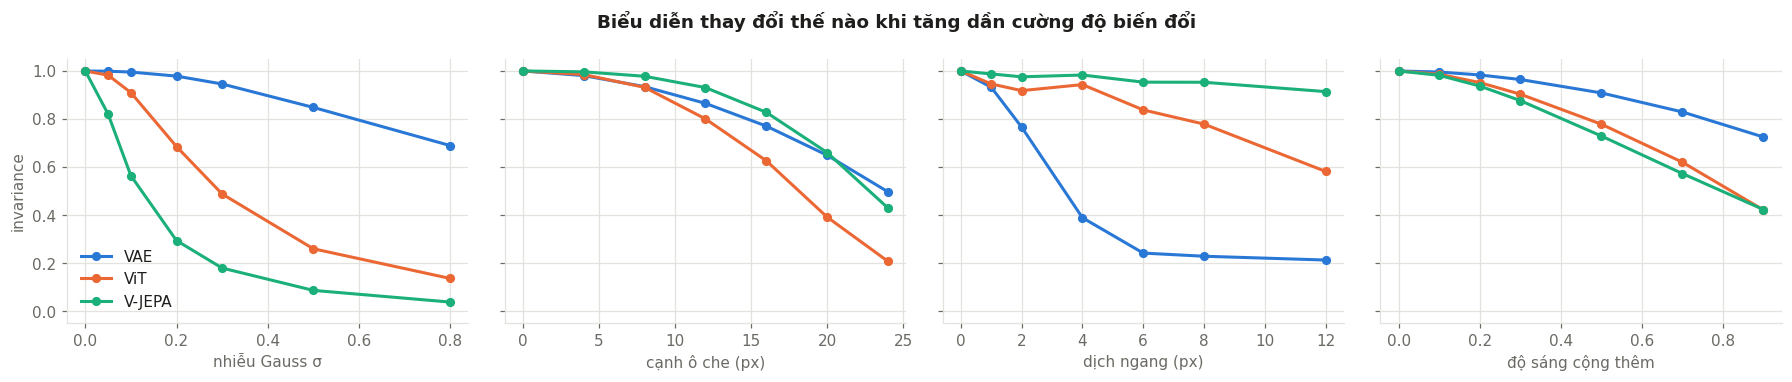

In [ ]:
sev = {
    "nhiễu Gauss σ": ([0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.8], lambda x, v: (x + v * torch.randn_like(x)).clamp(-1, 1)),
    "cạnh ô che (px)": ([0, 4, 8, 12, 16, 20, 24], lambda x, v: occlude(x, int(v)) if v else x),
    "dịch ngang (px)": ([0, 1, 2, 4, 6, 8, 12], lambda x, v: affine(x, tx=2 * v / 32)),
    "độ sáng cộng thêm": ([0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9], lambda x, v: (x + v).clamp(-1, 1)),
}
X_sev = X_inv[:500]
fig, axes = plt.subplots(1, len(sev), figsize=(4.1 * len(sev), 3.5), sharey=True)
for ax, (t, (vals, T)) in zip(axes, sev.items()):
    for n in NAMES:
        ys_ = []
        for v in vals:
            torch.manual_seed(0)
            XT = T(X_sev.to(device), v).cpu()
            c = float(cos_c(f0[n][:500], feats_of(FEAT[n], XT), n).mean())
            ys_.append((c - rand_cos[n]) / (1 - rand_cos[n]))
        ax.plot(vals, ys_, color=MODEL_COLORS[n], lw=2, marker="o", ms=5, label=n)
    ax.set_xlabel(t); ax.set_ylim(-0.05, 1.05); grid_style(ax)
axes[0].set_ylabel("invariance"); axes[0].legend()
fig.suptitle("Biểu diễn thay đổi thế nào khi tăng dần cường độ biến đổi", fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "09b_invariance_curves.png")

**Nhận xét**

- **Nhiễu**: V-JEPA sụt nhanh nhất (σ = 0,1 đã còn ~0,56), VAE bền nhất (σ = 0,8 vẫn ~0,69).
- **Dịch ngang**: VAE sụp ngay ở 4 px (~0,39) rồi về ~0,22; V-JEPA giữ ~0,9 kể cả khi dịch 12 px.
- **Che ô** và **độ sáng**: ba model giảm gần như nhau, ViT sụt mạnh hơn khi ô che lớn.
- Mỗi model "bỏ qua" đúng loại biến đổi mà mục tiêu của nó không cần quan tâm.

### 9.1 Bản đồ nhạy cảm khi che (occlusion sensitivity)

Trượt một ô xám 8×8 (bước 4 px) trên ảnh; màu tại mỗi vị trí = `1 − cos(f(x), f(x bị che))`. Vùng sáng = che chỗ đó làm biểu diễn thay đổi nhiều nhất.

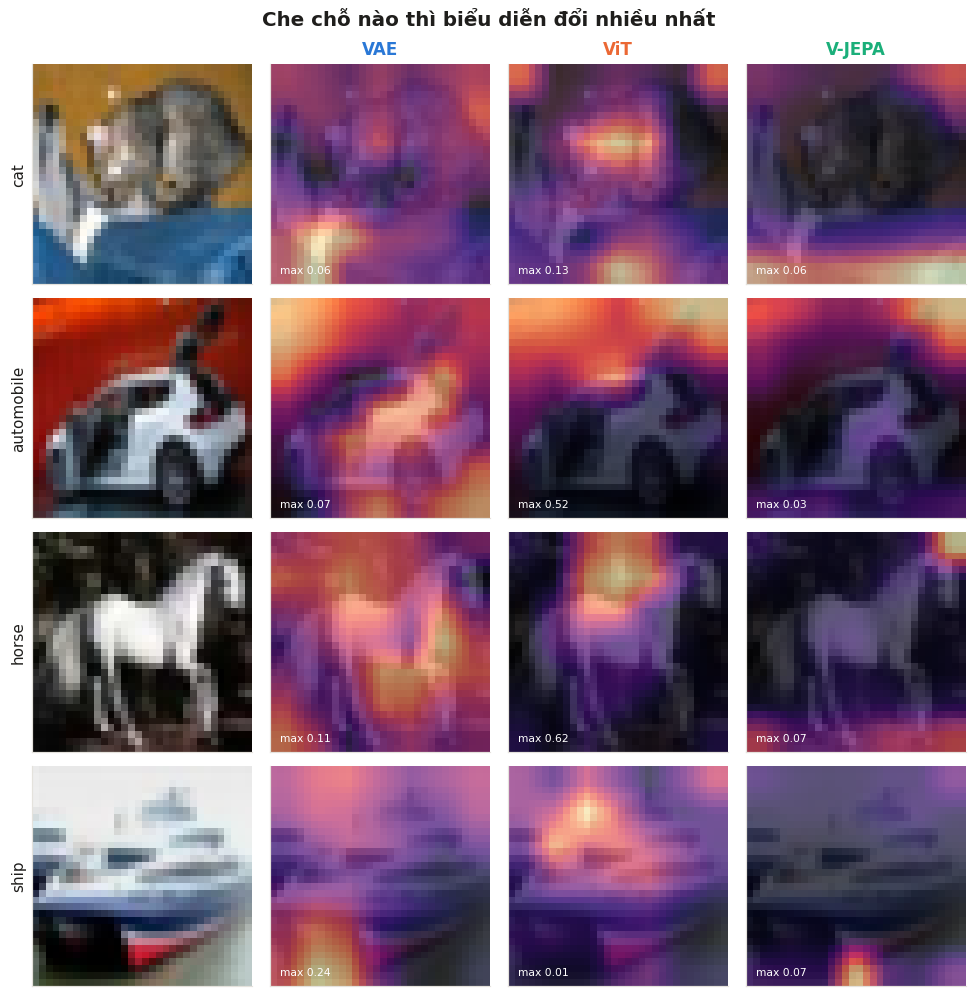

In [ ]:
@torch.no_grad()
def occlusion_map(n, x, size=8, stride=4):
    pos = list(range(0, 32 - size + 1, stride))
    batch = []
    for t in pos:
        for l in pos:
            xo = x.clone(); xo[:, t:t + size, l:l + size] = 0; batch.append(xo)
    batch = torch.stack(batch).to(device)
    f = FEAT[n](batch).float().cpu()
    base = FEAT[n](x[None].to(device)).float().cpu()
    d = 1 - F.cosine_similarity(f - mean_tr[n], base - mean_tr[n], dim=1)
    return d.reshape(len(pos), len(pos))


fig, axes = plt.subplots(N_SHOW, 4, figsize=(9, 2.3 * N_SHOW))
for i in range(N_SHOW):
    x = X_test[show_idx[i]]
    axes[i, 0].imshow(img_np(x)); axes[i, 0].set_ylabel(CLASSES[ys[i]], color=INK)
    for j, n in enumerate(NAMES):
        m = occlusion_map(n, x)
        up = F.interpolate(norm01(m.flatten())[None, None].reshape(1, 1, *m.shape), size=32, mode="bilinear",
                           align_corners=False)[0, 0].numpy()
        axes[i, j + 1].imshow(img_np(x) * 0.3 + 0.7 * plt.get_cmap(HEAT)(up)[..., :3])
        axes[i, j + 1].text(1, 30, f"max {float(m.max()):.2f}", color="white", fontsize=7)
        if i == 0:
            axes[i, j + 1].set_title(n, color=MODEL_COLORS[n])
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Che chỗ nào thì biểu diễn đổi nhiều nhất", fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "09c_occlusion_maps.png")

**Nhận xét**

- **ViT** đổi biểu diễn **rất mạnh** khi che đúng phần quan trọng của vật (thân ngựa, nóc xe: tối đa 0,5–0,6). Che ở chỗ khác thì gần như không đổi: quyết định phụ thuộc vào vài vùng then chốt.
- **V-JEPA** gần như không đổi dù che ở đâu (tối đa 0,03–0,07). Nó đã quen "nhìn thiếu" vì luôn học với phần lớn ảnh bị che.
- **VAE** đổi ở mức vừa và trải trên các **vùng sáng / tương phản lớn**, kể cả nền (ảnh tàu: 0,24).

## 10. Nội suy: biểu diễn thay đổi liên tục hay nhảy bậc?

Trộn pixel hai ảnh khác lớp: `x_α = (1−α)·A + α·B`. Đo vị trí của `f(x_α)` trên đoạn thẳng từ `f(A)` tới `f(B)`:
`t(α) = ⟨f(x_α) − f(A), f(B) − f(A)⟩ / ||f(B) − f(A)||²`.
Đường chéo = biểu diễn thay đổi tuyến tính theo pixel; đường hình chữ S = biểu diễn "giữ" một lớp rồi nhảy sang lớp kia.

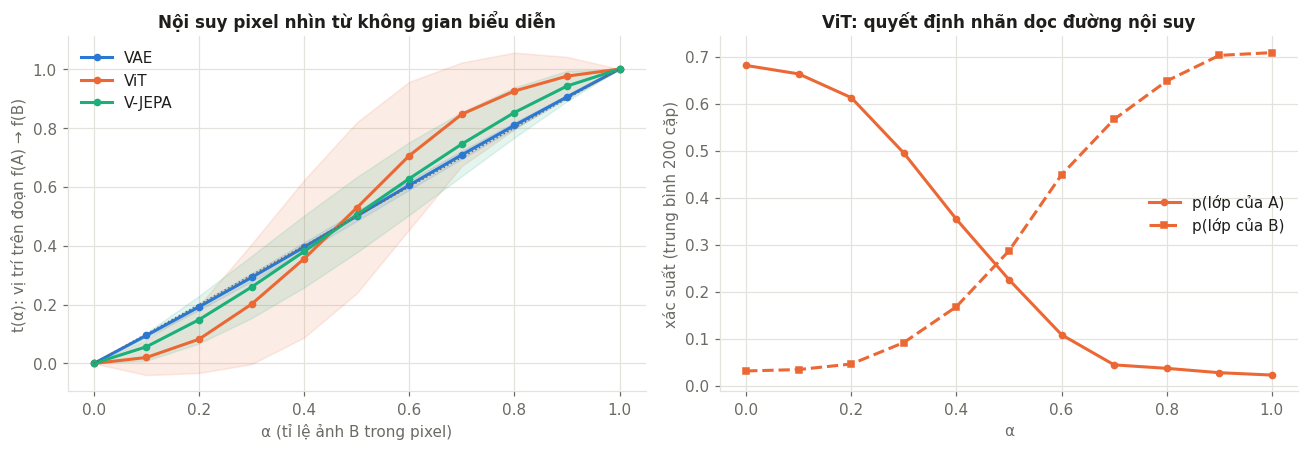

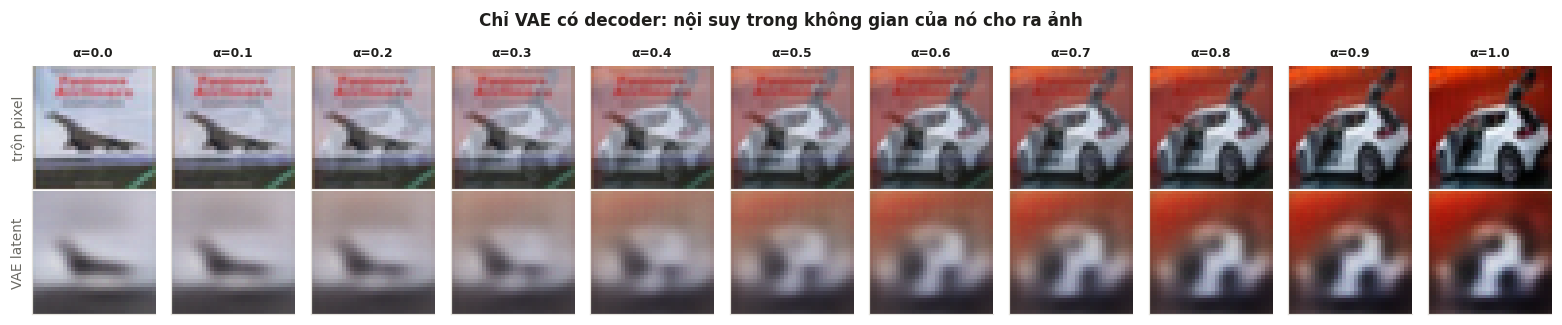

In [ ]:
alphas = torch.linspace(0, 1, 11)
rng = np.random.default_rng(SEED)
pairs = []
while len(pairs) < 200:
    a_, b_ = rng.choice(len(X_test), 2, replace=False)
    if Y_test[a_] != Y_test[b_]:
        pairs.append((a_, b_))
A = X_test[[p[0] for p in pairs]]; B = X_test[[p[1] for p in pairs]]
mix = torch.stack([(1 - a) * A + a * B for a in alphas], 1).flatten(0, 1)    # (pairs*11, 3, 32, 32)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for n in NAMES:
    f = feats_of(FEAT[n], mix).reshape(len(pairs), len(alphas), -1)
    fa, fb = f[:, :1], f[:, -1:]
    t = ((f - fa) * (fb - fa)).sum(-1) / ((fb - fa) ** 2).sum(-1)
    m, sd = t.mean(0).numpy(), t.std(0).numpy()
    ax1.plot(alphas, m, color=MODEL_COLORS[n], lw=2, marker="o", ms=4, label=n)
    ax1.fill_between(alphas, m - sd, m + sd, color=MODEL_COLORS[n], alpha=0.12)
ax1.plot([0, 1], [0, 1], color=INK_MUTED, ls=":", lw=1)
ax1.set_xlabel("α (tỉ lệ ảnh B trong pixel)"); ax1.set_ylabel("t(α): vị trí trên đoạn f(A) → f(B)")
ax1.set_title("Nội suy pixel nhìn từ không gian biểu diễn"); ax1.legend(); grid_style(ax1)

with torch.no_grad():
    pr = torch.cat([vit(mix[i:i + 500].to(device)).softmax(1).cpu() for i in range(0, len(mix), 500)]).reshape(len(pairs), len(alphas), 10)
yA = Y_test[[p[0] for p in pairs]]; yB = Y_test[[p[1] for p in pairs]]
pA = pr[torch.arange(len(pairs)), :, yA].mean(0); pB = pr[torch.arange(len(pairs)), :, yB].mean(0)
ax2.plot(alphas, pA, color=MODEL_COLORS["ViT"], lw=2, marker="o", ms=4, label="p(lớp của A)")
ax2.plot(alphas, pB, color=MODEL_COLORS["ViT"], lw=2, ls="--", marker="s", ms=4, label="p(lớp của B)")
ax2.set_xlabel("α"); ax2.set_ylabel("xác suất (trung bình 200 cặp)")
ax2.set_title("ViT: quyết định nhãn dọc đường nội suy"); ax2.legend(); grid_style(ax2)
fig.tight_layout()
show(fig, "10_interpolation.png")

# VAE: nội suy trong pixel vs nội suy trong latent (decode)
pa, pb = X_test[3], X_test[6]
with torch.no_grad():
    za, zb = vae.encode(torch.stack([pa, pb]).to(device))[0]
    lat = vae.decode(torch.stack([(1 - a) * za + a * zb for a in alphas.to(device)]))
fig, axes = plt.subplots(2, len(alphas), figsize=(1.3 * len(alphas), 3))
for j, a in enumerate(alphas):
    axes[0, j].imshow(img_np((1 - a) * pa + a * pb)); axes[1, j].imshow(img_np(lat[j]))
    axes[0, j].set_title(f"α={a:.1f}", fontsize=8)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("trộn pixel", fontsize=9); axes[1, 0].set_ylabel("VAE latent", fontsize=9)
fig.suptitle("Chỉ VAE có decoder: nội suy trong không gian của nó cho ra ảnh", fontsize=11, fontweight="bold")
fig.tight_layout()
show(fig, "10b_vae_interp.png")

**Nhận xét**

- **Hình trên**: `S_vae` đi **đúng đường chéo** (t(α) ≈ α), tức gần như tuyến tính theo pixel. `S_vit` có dạng **chữ S**: giữ lớp A tới α ≈ 0,3 rồi chuyển nhanh, hai xác suất cắt nhau ở α ≈ 0,48. `S_vjepa` cong nhẹ, ở giữa.
- **Hình dưới**: trộn pixel cho ra hai ảnh chồng lên nhau, còn nội suy trong latent của VAE cho ra các ảnh **chuyển dần** (máy bay mờ dần, nền chuyển sang đỏ, xe hiện ra). Ảnh mờ nhưng hợp lý: không gian VAE **liên tục**, nhưng chủ yếu theo màu và bố cục.

## 11. Dấu vết riêng của từng mục tiêu

### 11.1 VAE: KL từng chiều, "chiều nào đang được dùng"

KL ép mỗi chiều `z_i` về N(0,1). Chiều nào không đáng để mang thông tin thì KL ≈ 0 (chiều "chết", posterior collapse cục bộ).
Ta vẽ KL trung bình từng chiều và thay đổi lần lượt 3 chiều có KL lớn nhất (latent traversal).

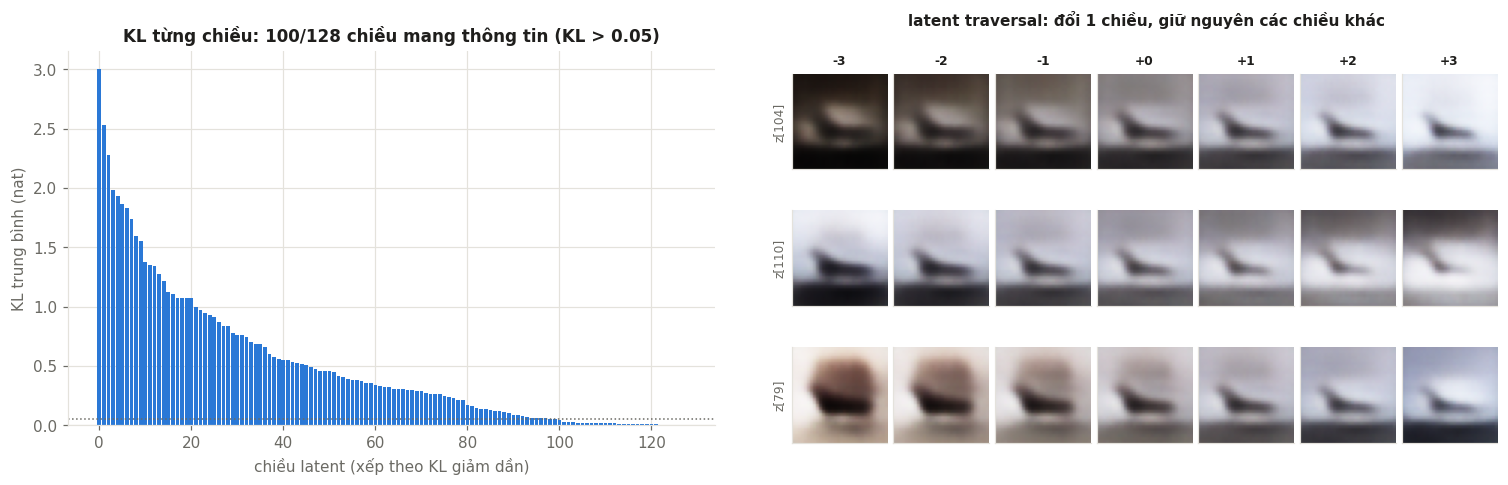

In [ ]:
with torch.no_grad():
    mus, lvs = [], []
    for i in range(0, 5000, 500):
        m_, l_ = vae.encode(X_test[i:i + 500].to(device)); mus.append(m_.cpu()); lvs.append(l_.cpu())
    mus, lvs = torch.cat(mus), torch.cat(lvs)
kl_dim = (-0.5 * (1 + lvs - mus ** 2 - lvs.exp())).mean(0).numpy()
order = np.argsort(-kl_dim)

fig = plt.figure(figsize=(14, 4.6))
ax = fig.add_axes([0.05, 0.14, 0.42, 0.74])
ax.bar(np.arange(len(kl_dim)), kl_dim[order], color=MODEL_COLORS["VAE"], width=0.8)
active = int((kl_dim > 0.05).sum())
ax.axhline(0.05, color=INK_MUTED, ls=":", lw=1)
ax.set_xlabel("chiều latent (xếp theo KL giảm dần)"); ax.set_ylabel("KL trung bình (nat)")
ax.set_title(f"KL từng chiều: {active}/{len(kl_dim)} chiều mang thông tin (KL > 0.05)"); grid_style(ax)

steps_ = torch.linspace(-3, 3, 7)
base = mus[3:4].to(device)
for r, d in enumerate(order[:3]):
    zs = base.repeat(len(steps_), 1)
    zs[:, d] = steps_.to(device)
    with torch.no_grad():
        ims = vae.decode(zs)
    for c in range(len(steps_)):
        a = fig.add_axes([0.52 + c * 0.066, 0.62 - r * 0.27, 0.062, 0.24])
        a.imshow(img_np(ims[c])); a.set_xticks([]); a.set_yticks([])
        if r == 0:
            a.set_title(f"{steps_[c]:+.0f}", fontsize=8)
        if c == 0:
            a.set_ylabel(f"z[{d}]", fontsize=8)
fig.text(0.75, 0.93, "latent traversal: đổi 1 chiều, giữ nguyên các chiều khác", ha="center", fontweight="bold")
show(fig, "11_vae_kl.png")

**Nhận xét**

- **100/128 chiều** có KL > 0,05: VAE dùng gần hết latent, khớp với effective rank cao (~88).
- KL giảm dần đều chứ không có vài chiều vượt trội: thông tin được **chia nhỏ** cho nhiều chiều.
- Đổi 3 chiều mạnh nhất chỉ làm đổi **độ sáng / màu nền / độ tương phản** toàn ảnh, không biến máy bay thành vật khác. Các hướng "đắt" nhất của VAE là màu và bố cục, không phải lớp.

### 11.2 V-JEPA: predictor đoán tốt tới đâu, và khó nhất ở đâu?

Với 2 000 ảnh test và hai loại mặt nạ, ta đo cos giữa token dự đoán và token mục tiêu tại mỗi ô bị che, theo **khoảng cách tới patch context gần nhất**.
So với ba mức tham chiếu không cần predictor:
- "TB dataset": một token trung bình duy nhất (không nhìn ảnh, không biết vị trí),
- "TB theo vị trí": token trung bình của dataset **tại đúng vị trí đó** (biết vị trí, không nhìn ảnh),
- "TB của ảnh": trung bình mọi token mục tiêu của chính ảnh đó (gian lận một phần: dùng cả token bị che, nhưng không biết vị trí).

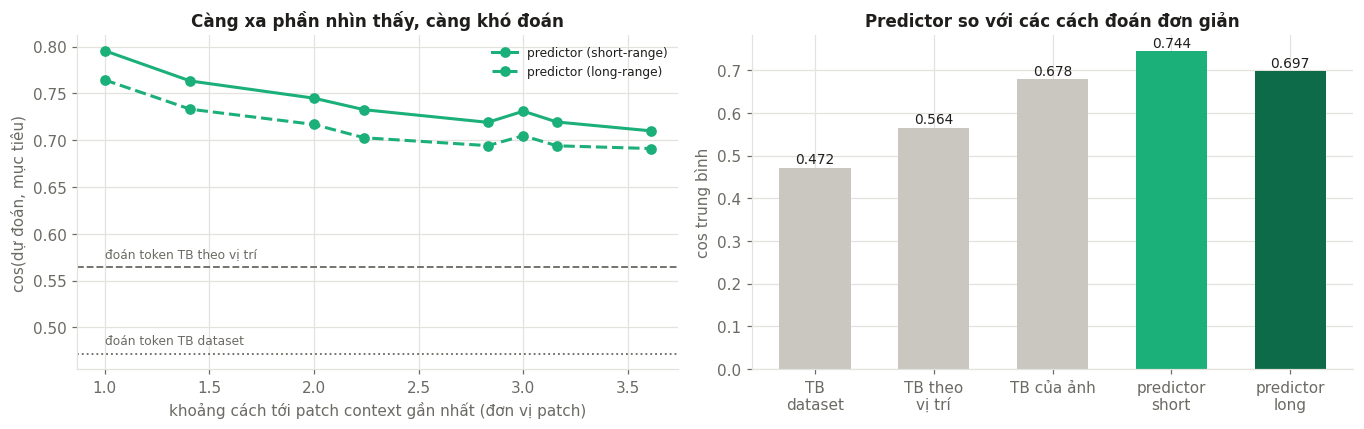

In [ ]:
@torch.no_grad()
def vjepa_eval(cfg, X, seed):
    out = dict(cos=[], dist=[], cos_mean=[], cos_pos=[], cos_img=[])
    for i in range(0, len(X), 250):
        x = X[i:i + 250].to(device)
        k_, m_ = fixed_mask(len(x), cfg, seed=seed + i)
        h, t, p = vjepa_predict(x, k_, m_)
        out["cos"].append(F.cosine_similarity(p, t, dim=-1).flatten().cpu())
        gm = tok_mean.to(device).expand_as(t)
        out["cos_mean"].append(F.cosine_similarity(gm, t, dim=-1).flatten().cpu())
        pt = gather_tokens(pos_tok.expand(len(x), -1, -1), m_)
        out["cos_pos"].append(F.cosine_similarity(pt, t, dim=-1).flatten().cpu())
        im_mean = h.mean(1, keepdim=True).expand_as(t)
        out["cos_img"].append(F.cosine_similarity(im_mean, t, dim=-1).flatten().cpu())
        ky, kx = k_ // GRID_N, k_ % GRID_N; my, mx = m_ // GRID_N, m_ % GRID_N
        d = ((my[:, :, None] - ky[:, None]) ** 2 + (mx[:, :, None] - kx[:, None]) ** 2).float().sqrt().amin(-1)
        out["dist"].append(d.flatten().cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items()}


with torch.no_grad():
    hh_ = vj_tgt(X_test[:1000].to(device))
    hh_ = F.layer_norm(hh_, (hh_.size(-1),))
    tok_mean, pos_tok = hh_.mean((0, 1)), hh_.mean(0, keepdim=True)     # (D,), (1, 64, D)
res = {"short-range": vjepa_eval(SHORT, X_test[3000:5000], 10), "long-range": vjepa_eval(LONG, X_test[3000:5000], 20)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4))
for name, r_, ls in [("short-range", res["short-range"], "-"), ("long-range", res["long-range"], "--")]:
    dvals = np.unique(np.round(r_["dist"], 2))
    bins = [d for d in dvals if (np.round(r_["dist"], 2) == d).sum() > 200][:8]
    mc = [r_["cos"][np.round(r_["dist"], 2) == d].mean() for d in bins]
    ax1.plot(bins, mc, color=MODEL_COLORS["V-JEPA"], lw=2, ls=ls, marker="o", label=f"predictor ({name})")
ax1.axhline(res["long-range"]["cos_mean"].mean(), color=INK_MUTED, ls=":", lw=1.2)
ax1.text(1, res["long-range"]["cos_mean"].mean() + 0.01, "đoán token TB dataset", fontsize=8, color=INK_MUTED)
ax1.axhline(res["long-range"]["cos_pos"].mean(), color=INK_MUTED, ls="--", lw=1.2)
ax1.text(1, res["long-range"]["cos_pos"].mean() + 0.01, "đoán token TB theo vị trí", fontsize=8, color=INK_MUTED)
ax1.set_xlabel("khoảng cách tới patch context gần nhất (đơn vị patch)"); ax1.set_ylabel("cos(dự đoán, mục tiêu)")
ax1.set_title("Càng xa phần nhìn thấy, càng khó đoán"); ax1.legend(fontsize=8); grid_style(ax1)

labels_ = ["TB\ndataset", "TB theo\nvị trí", "TB của ảnh", "predictor\nshort", "predictor\nlong"]
vals = [res["long-range"]["cos_mean"].mean(), res["long-range"]["cos_pos"].mean(), res["long-range"]["cos_img"].mean(),
        res["short-range"]["cos"].mean(), res["long-range"]["cos"].mean()]
b = ax2.bar(labels_, vals, color=["#c9c7c0"] * 3 + [MODEL_COLORS["V-JEPA"], "#0d6b4a"], width=0.6)
for r_, v in zip(b, vals):
    ax2.text(r_.get_x() + r_.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax2.set_ylabel("cos trung bình"); ax2.set_title("Predictor so với các cách đoán đơn giản"); grid_style(ax2)
fig.tight_layout()
show(fig, "11b_vjepa_predictor.png")

**Nhận xét**

- Predictor đạt cos **0,74** (short) / **0,70** (long), cao hơn cả mức "token TB của chính ảnh" (0,68), một mức tham chiếu được phép nhìn cả phần bị che. Predictor đoán được **nội dung riêng của từng ô**, không chỉ "trung bình ảnh".
- Đoán theo vị trí (0,56) đã hơn đoán bừa (0,47): một phần bài toán đúng là "ô này thường trông thế nào".
- Càng xa phần nhìn thấy, cos càng giảm, nhưng chỉ nhẹ (0,80 → 0,71): predictor dùng ngữ cảnh **toàn cục**, không chỉ chép hàng xóm.

## 12. Hình học của ba không gian

### 12.1 Phổ trị riêng, alignment / uniformity

- **Phổ**: phương sai tích luỹ theo số thành phần chính. Không gian "dẹt" (ít hướng chiếm hết phương sai) vs "tròn".
- **Alignment** (Wang & Isola, 2020): khoảng cách giữa biểu diễn (đã chuẩn hoá) của một ảnh và bản augment của nó, càng nhỏ càng bất biến.
- **Uniformity**: log E[exp(−2||f_i − f_j||²)], càng âm thì các điểm càng trải đều trên mặt cầu (giữ nhiều thông tin).

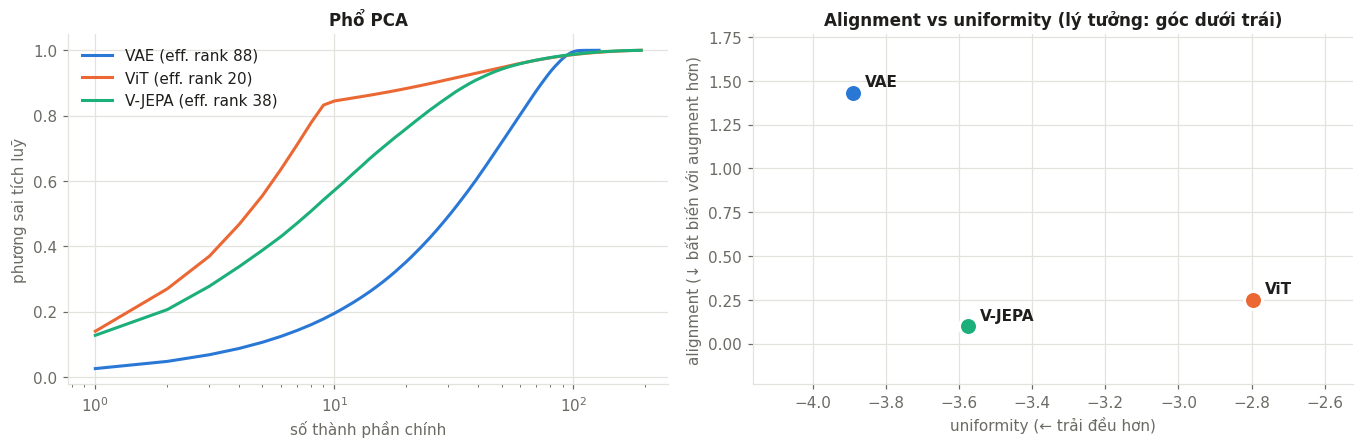

In [ ]:
def spectrum(f):
    f = f - f.mean(0)
    ev = torch.linalg.svdvals(f.double()) ** 2
    return (ev / ev.sum()).numpy()


def alignment_uniformity(n, X):
    f = F.normalize(feats_of(FEAT[n], X) - mean_tr[n], dim=1)
    torch.manual_seed(0)
    fa = F.normalize(feats_of(FEAT[n], torch.cat([gpu_aug(X[i:i + 500].to(device)).cpu() for i in range(0, len(X), 500)])) - mean_tr[n], dim=1)
    align = float((f - fa).pow(2).sum(1).mean())
    sq = torch.cdist(f, f).pow(2)
    unif = float(torch.log(torch.exp(-2 * sq[~torch.eye(len(f), dtype=bool)]).mean()))
    return align, unif


AU = {n: alignment_uniformity(n, X_test[:2000]) for n in NAMES}
ER = {n: eff_rank(F_te[n]) for n in NAMES}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
for n in NAMES:
    s = spectrum(F_te[n])
    ax1.plot(np.arange(1, len(s) + 1), np.cumsum(s), color=MODEL_COLORS[n], lw=2, label=f"{n} (eff. rank {ER[n]:.0f})")
ax1.set_xscale("log"); ax1.set_xlabel("số thành phần chính"); ax1.set_ylabel("phương sai tích luỹ")
ax1.set_title("Phổ PCA"); ax1.legend(); grid_style(ax1)
for n in NAMES:
    a, u = AU[n]
    ax2.scatter(u, a, s=140, color=MODEL_COLORS[n], edgecolors="white", linewidths=2, zorder=3)
    ax2.annotate(n, (u, a), xytext=(8, 4), textcoords="offset points", fontsize=10, fontweight="bold")
ax2.set_xlabel("uniformity (← trải đều hơn)"); ax2.set_ylabel("alignment (↓ bất biến với augment hơn)")
ax2.set_title("Alignment vs uniformity (lý tưởng: góc dưới trái)"); grid_style(ax2)
ax2.margins(0.25)
fig.tight_layout()
show(fig, "12_geometry.png")

**Nhận xét**

- **Phổ**: ViT dồn **85% phương sai vào ~9 hướng** (gấp khúc rõ ở 9 = số lớp − 1). Đây là hiện tượng "neural collapse" của học có nhãn: mỗi lớp thu về một điểm. VAE cần ~100 hướng, V-JEPA ở giữa (eff. rank 38).
- **Alignment**: V-JEPA bất biến với augment (lật + dịch) **nhất** (0,10), VAE **kém nhất** (1,43), khớp với mục 9.
- **Uniformity**: VAE trải đều nhất trên mặt cầu (−3,89), ViT kém đều nhất (−2,80, vì các điểm dồn về 10 cụm). V-JEPA nằm gần góc lý tưởng (dưới-trái) nhất.

### 12.2 Khoảng cách trong lớp và giữa các lớp

Phân phối cos (sau khi trừ trung bình) giữa các cặp ảnh **cùng lớp** và **khác lớp**. Hai phân phối càng tách rời thì không gian càng "ngữ nghĩa".
Con số `d'` = (TB cùng lớp − TB khác lớp) / độ lệch chuẩn gộp.

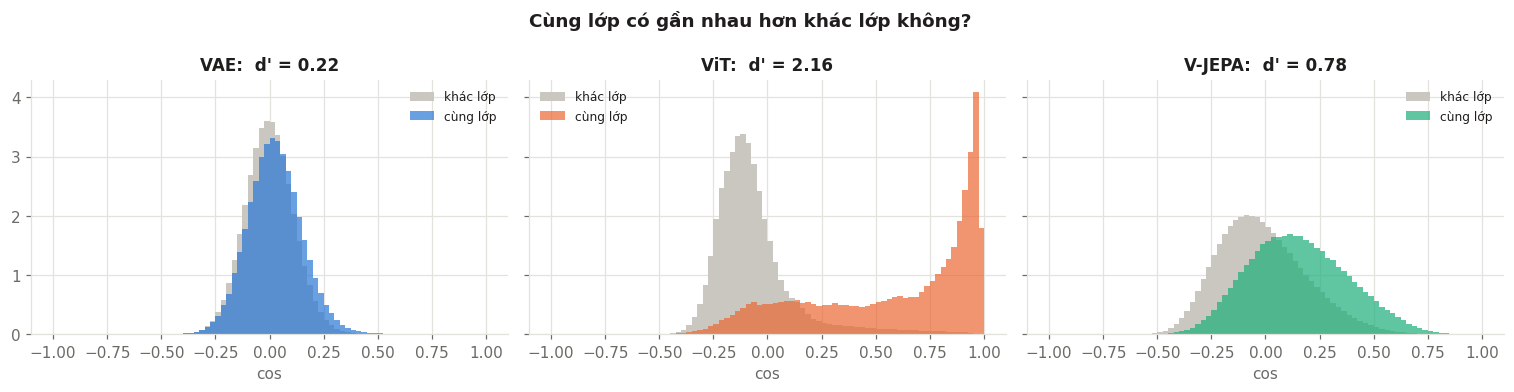

In [ ]:
SEP = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
sub = torch.arange(min(2000, len(Yp_te)))
for ax, n in zip(axes, NAMES):
    f = F.normalize(F_te[n][sub] - mean_tr[n], dim=1)
    s = f @ f.T
    y = Yp_te[sub]
    same = (y[:, None] == y[None]) & ~torch.eye(len(y), dtype=bool)
    diff = y[:, None] != y[None]
    a, b = s[same].numpy(), s[diff].numpy()
    d = (a.mean() - b.mean()) / math.sqrt(0.5 * (a.var() + b.var()))
    SEP[n] = d
    ax.hist(b, bins=80, range=(-1, 1), density=True, color="#c9c7c0", label="khác lớp")
    ax.hist(a, bins=80, range=(-1, 1), density=True, color=MODEL_COLORS[n], alpha=0.7, label="cùng lớp")
    ax.set_title(f"{n}:  d' = {d:.2f}", color=INK); ax.set_xlabel("cos"); ax.legend(fontsize=8); grid_style(ax)
fig.suptitle("Cùng lớp có gần nhau hơn khác lớp không?", fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "12b_intra_inter.png")

**Nhận xét**

- **ViT** (d' = 2,16): cặp cùng lớp dồn về cos ≈ 1, khác lớp quanh −0,1; hai phân phối gần như tách rời.
- **V-JEPA** (d' = 0,78): cùng lớp lệch phải rõ, nhưng hai phân phối còn chồng nhiều.
- **VAE** (d' = 0,22): hai phân phối gần như trùng nhau. Ảnh cùng lớp hầu như không gần nhau hơn ảnh khác lớp.

### 12.3 Linear probe: model nhầm lớp nào với lớp nào?

Logistic regression trên `N_PROBE_TRAIN` ảnh train, đánh giá trên `N_PROBE_TEST` ảnh test. Ma trận nhầm lẫn chuẩn hoá theo hàng (lớp thật).

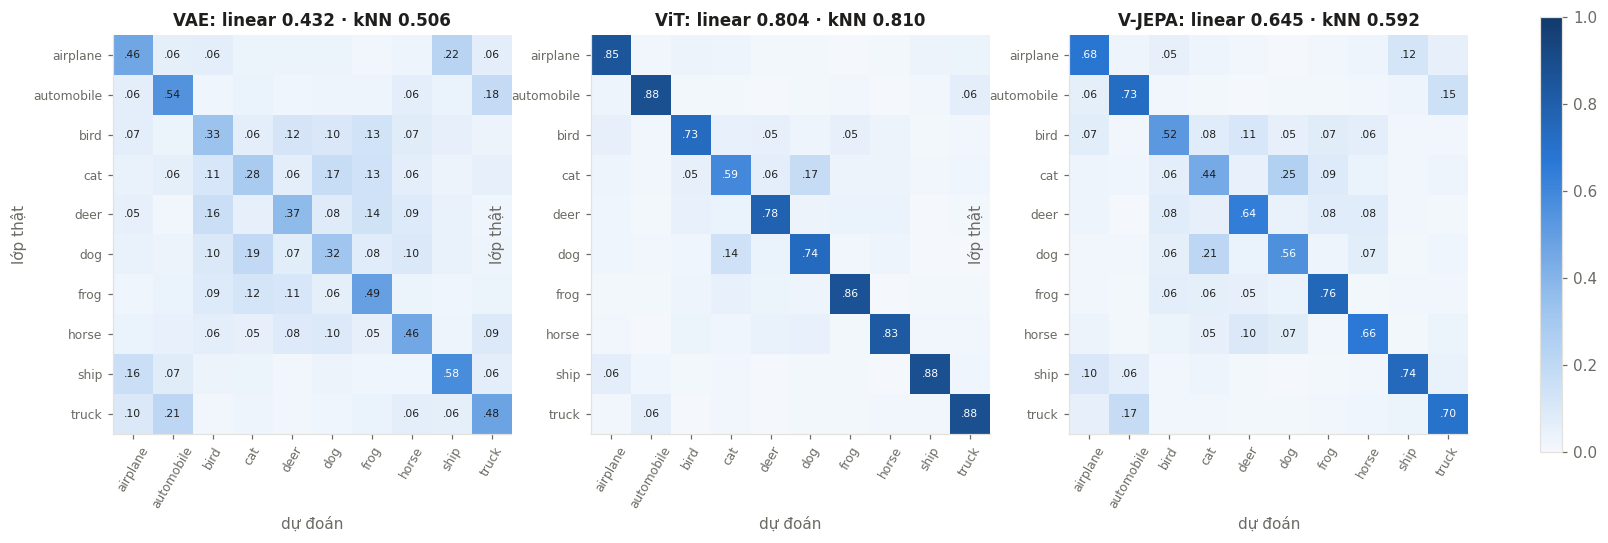

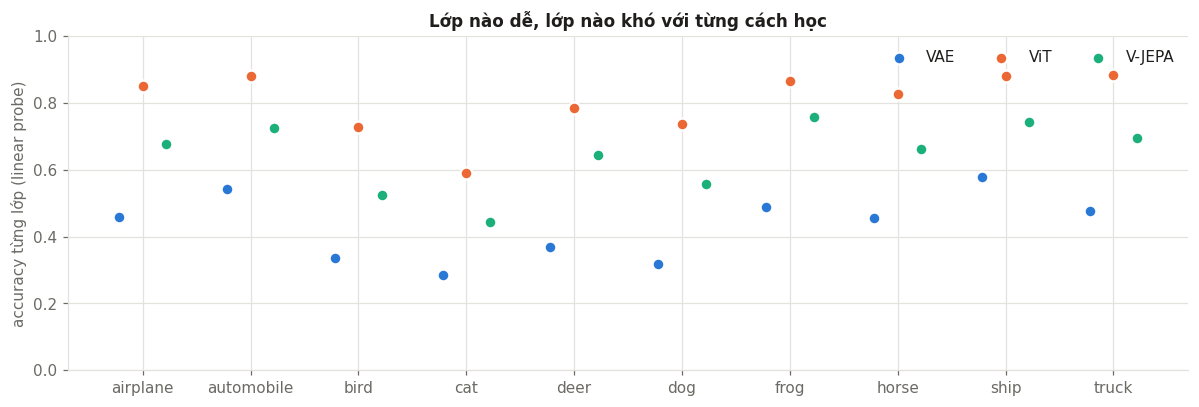

In [ ]:
LIN, CM = {}, {}
for n in NAMES:
    sc = StandardScaler().fit(F_tr[n].numpy())
    clf = LogisticRegression(max_iter=1000).fit(sc.transform(F_tr[n].numpy()), Yp_tr.numpy())
    pr_ = clf.predict(sc.transform(F_te[n].numpy()))
    LIN[n] = float((pr_ == Yp_te.numpy()).mean())
    CM[n] = confusion_matrix(Yp_te.numpy(), pr_, normalize="true")
KNN = {n: knn(F_tr[n], Yp_tr, F_te[n], Yp_te) for n in NAMES}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, n in zip(axes, NAMES):
    im = ax.imshow(CM[n], cmap=SEQ, vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if CM[n][i, j] >= 0.05:
                ax.text(j, i, f"{CM[n][i, j]:.2f}".lstrip("0"), ha="center", va="center", fontsize=7,
                        color="white" if CM[n][i, j] > 0.55 else INK)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_title(f"{n}: linear {LIN[n]:.3f} · kNN {KNN[n]:.3f}", color=INK)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("lớp thật")
fig.colorbar(im, ax=axes, fraction=0.015)
show(fig, "12c_confusion.png")

fig, ax = plt.subplots(figsize=(11, 3.8))
for k, n in enumerate(NAMES):
    acc = np.diag(CM[n])
    ax.scatter(np.arange(10) + (k - 1) * 0.22, acc, s=60, color=MODEL_COLORS[n], edgecolors="white", linewidths=1.5,
               label=n, zorder=3)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES); ax.set_ylim(0, 1)
ax.set_ylabel("accuracy từng lớp (linear probe)"); ax.legend(ncol=3); grid_style(ax)
ax.set_title("Lớp nào dễ, lớp nào khó với từng cách học")
fig.tight_layout()
show(fig, "12d_per_class.png")

**Nhận xét**

- **Ma trận nhầm lẫn**: cả ba đều nhầm **cat ↔ dog** nhiều nhất. VAE còn nhầm **airplane ↔ ship** (0,22, cùng nền xanh) và **automobile ↔ truck**. V-JEPA có cùng kiểu nhầm nhưng nhẹ hơn. ViT có đường chéo ≥ 0,59 ở mọi lớp.
- **Từng lớp**: thứ tự ViT > V-JEPA > VAE giữ nguyên ở **mọi** lớp. Xe cộ (automobile, ship, truck) dễ cho cả ba; cat, dog, bird khó nhất (VAE cat chỉ 0,28).
- Khoảng cách V-JEPA → ViT nhỏ nhất ở frog / ship / truck và lớn nhất ở cat / dog, những lớp cần chi tiết tinh mà không có nhãn thì khó học.

## 13. Tổng kết

Bảng dưới gom các con số đo được ở trên. Màu trong mỗi cột: đậm = "nhiều hơn" trong cột đó (không phải lúc nào nhiều hơn cũng tốt hơn, ví dụ invariance màu sắc).

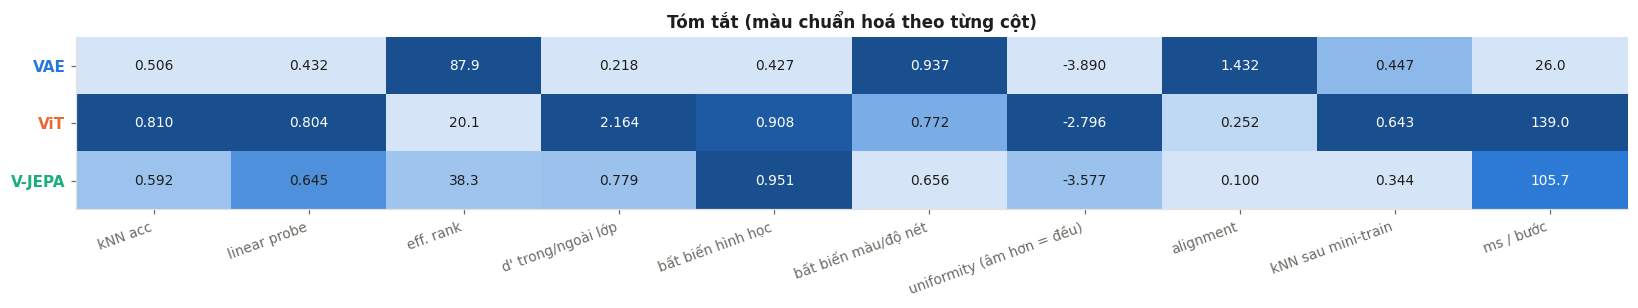

In [ ]:
inv_geo = {n: float(INV[i, :4].mean()) for i, n in enumerate(NAMES)}        # lật, dịch, xoay, zoom
inv_col = {n: float(INV[i, 4:8].mean()) for i, n in enumerate(NAMES)}       # sáng, tương phản, xám, mờ
rows = {
    "kNN acc": KNN, "linear probe": LIN, "eff. rank": ER, "d' trong/ngoài lớp": SEP,
    "bất biến hình học": inv_geo, "bất biến màu/độ nét": inv_col,
    "uniformity (âm hơn = đều)": {n: AU[n][1] for n in NAMES}, "alignment": {n: AU[n][0] for n in NAMES},
    "kNN sau mini-train": {n: logs[n]["knn"][-1] for n in NAMES},
    "ms / bước": {n: logs[n]["ms_per_step"] for n in NAMES},
}
vals = np.array([[rows[r][n] for r in rows] for n in NAMES])
norm = (vals - vals.min(0)) / (np.ptp(vals, 0) + 1e-12)
fig, ax = plt.subplots(figsize=(15, 2.9))
ax.imshow(norm, cmap=SEQ, vmin=-0.15, vmax=1.15, aspect="auto")
for i in range(len(NAMES)):
    for j in range(len(rows)):
        v = vals[i, j]
        ax.text(j, i, f"{v:.3f}" if abs(v) < 10 else f"{v:.1f}", ha="center", va="center", fontsize=9,
                color="white" if norm[i, j] > 0.6 else INK)
ax.set_xticks(range(len(rows))); ax.set_xticklabels(list(rows), rotation=20, ha="right", fontsize=9)
ax.set_yticks(range(3)); ax.set_yticklabels(NAMES)
for t, n in zip(ax.get_yticklabels(), NAMES):
    t.set_color(MODEL_COLORS[n]); t.set_fontweight("bold")
ax.set_title("Tóm tắt (màu chuẩn hoá theo từng cột)")
fig.tight_layout()
show(fig, "13_summary.png")
print("hình đã lưu trong", os.path.abspath(OUT_DIR))

**Nhận xét**

- **ViT** dẫn ở mọi thước đo về **phân lớp** (kNN, linear, d') vì được dạy trực tiếp bằng nhãn, đổi lại không gian **dẹt** (rank 20) và kém đều.
- **V-JEPA** không có nhãn nhưng đứng thứ hai về phân lớp, **bất biến hình học tốt nhất** và alignment tốt nhất. Đổi lại học rất chậm (kNN sau mini-train 25 epoch chỉ 0,34, so với 0,64 của ViT) và nhạy với màu / nhiễu.
- **VAE** giữ được nhiều thông tin nhất (rank 88, đều nhất, bền với nhiễu / độ sáng), nhưng thông tin đó là **màu và bố cục**, nên kém nhất về ngữ nghĩa và nhạy nhất với dịch / lật ảnh.

| Khía cạnh | **VAE** | **ViT** | **V-JEPA** |
|---|---|---|---|
| Không gian S (mục 1b) | đám mây trộn lớp, gần nhau theo màu / bố cục | 10 cụm tách rời, tâm lớp gần trực giao | cụm theo siêu lớp (động vật vs xe cộ), lớp chưa tách hẳn |
| Mặt cầu (mục 1c) | điểm rải đều, lớp lẫn lộn | mỗi lớp một "hòn đảo" | hai bán cầu: động vật vs xe cộ |
| Vị trí vật (mục 1d) | biết vị trí; **không** nhận ra vật khi nó dời chỗ | biết vị trí; nhận ra vật ở chỗ khác một phần | biết vị trí rõ nhất (theo hàng); nhận ra vật dịch ngang tốt hơn dịch dọc |
| Chia khung 2×2 (mục 1d) | đọc từng góc tốt nhất (nhớ bố cục) | kém nhất (gộp thành 1 nhãn) | ở giữa |
| Tín hiệu học | dày đặc, ở mức pixel, cố định | rất thưa (1 nhãn/ảnh), cố định, do người gán | khá dày (token × 192), **tự sinh**, thay đổi theo EMA |
| Gradient theo pixel (mục 3) | trải khắp ảnh, kể cả nền | tập trung vào vùng phân biệt lớp | chỉ ở phần context, hướng về vùng giúp đoán phần bị che |
| Học theo thời gian (mục 4) | kNN chạm trần (~0,45) từ epoch 4, loss vẫn giảm | kNN tăng đều, nhanh nhất | vài epoch đầu đứng yên rồi mới tăng; loss **đi lên** khi biểu diễn tốt hơn |
| Lối tắt nguy hiểm | posterior collapse (KL → 0) | học thuộc nhãn (overfit) | **collapse biểu diễn** nếu bỏ EMA/stop-grad (mục 5) |
| Attention / receptive field (mục 6) | cục bộ, tăng dần theo tầng conv | `[CLS]` gom về vật thể | không có token tổng hợp; dùng vài patch nền làm "sink" |
| Patch token (mục 7) | theo màu / độ sáng / biên | ít ràng buộc (loss chỉ dùng `[CLS]`) | vài hướng chính đầu tiên là **vị trí**; phần còn lại là nội dung cục bộ |
| Bất biến (mục 9) | rất nhạy với **hình học** (lật, dịch, xoay); ít nhạy với nhiễu / độ sáng | bất biến khá đều với mọi biến đổi | bất biến **hình học** mạnh nhất; nhạy nhất với nhiễu và ảnh xám |
| Nội suy (mục 10) | gần tuyến tính theo pixel | dạng chữ S (nhảy lớp) | hơi cong, ở giữa |
| CKA (mục 8) | gần pixel nhất | xa pixel nhất | ở giữa; các block đầu giống ViT, block cuối khác dần |
| Sinh ảnh | **có** (decoder) | không | không (chỉ dự đoán trong không gian biểu diễn) |

**Kết luận chung**: *cái mà loss so sánh* quyết định *cái mà biểu diễn giữ lại*. So sánh pixel thì giữ pixel (VAE).
So sánh nhãn thì giữ đúng thông tin phân biệt nhãn (ViT). So sánh biểu diễn của phần bị che thì giữ thông tin **dự đoán được từ ngữ cảnh**:
cấu trúc và ngữ nghĩa, không cần nhãn và không phải tốn sức cho chi tiết pixel (V-JEPA).